# UE Data Mining – Projet : le dossier ecology

Notebook réalisé dans le cadre du projet de l'UE Data Mining des Master 2 Intelligence Artificielle et Master 2 Data Science, année 2026-2027.

* Projet de groupe (groupe 10)

# Introduction

Les données du projet sont fictives et viennent de quatre domaines : registres publics, santé, écologie et logistique. Le but est de retrouver l'histoire cachée qu'elles racontent, avec les méthodes vues en cours.

Ce notebook porte sur le dossier **ecology** : le suivi des chauves-souris sur 64 sites naturels, de 2019 à 2025. Nous avançons pas à pas :

| Partie | Ce que nous faisons | Cours |
|---|---|---|
| 1 | Découvrir les données, les nettoyer, faire une première exploration | 1 |
| 2 | Comparer le site KNT-KES, qui chute en 2024, à des sites semblables | 1 |
| 3 | Finir le nettoyage et construire une table d'analyse unique | 1 |
| 4 | Décrire les variables et mesurer leurs liens | 1 |
| 5 | Comparer et regrouper les sites | 2 |
| 6 | Chercher des régularités et des anomalies | 3 |
| 7 | Étudier le temps (saisons) et l'espace (carte) | 5 |
| 8 | Lire les rapports de terrain | 6 |
| 9 | Graphes et processus | 4 |
| 10 | Tester notre hypothèse | — |
| 11 | Synthèse, limites et pistes | — |

Une annexe, à la fin, décrit l'usage de l'IA générative.

# 1. Découvrir et préparer les données

## 1.1 Les données disponibles

Le fichier `data_dictionary.csv` décrit toutes les colonnes de tous les fichiers. Nous commençons par lui, pour savoir ce que contient chaque fichier avant de l'ouvrir.

In [1]:
import re
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
data_dictionary = pd.read_csv("../data/data_dictionary.csv")
print("Nombre de fichiers décrits dans chaque lot de données :")
print(data_dictionary.groupby("source_bundle")["file_name"].nunique().to_string())
data_dictionary[["source_bundle", "source_system_id", "file_name"]].drop_duplicates().reset_index(drop=True)

Nombre de fichiers décrits dans chaque lot de données :
source_bundle
SB01    5
SB02    6
SB03    5
SB04    7
SB05    2
SB06    4


,source_bundle,source_system_id,file_name
0,SB02,SYS-CLN-OPS,clinical_encounters.csv
1,SB02,SYS-CLN-OPS,clinical_observations.csv
2,SB02,SYS-CLN-OPS,clinical_procedures.csv
3,SB02,SYS-CLN-OPS,patient_administration.csv
4,SB01,SYS-PR-FAC,licensed_facilities.csv
5,SB01,SYS-PR-PRO,licensed_professionals.csv
6,SB01,SYS-PR-OFF,officer_filings.csv
7,SB01,SYS-PR-APT,public_appointments.csv
8,SB01,SYS-PR-REG,registered_entities.csv
9,SB03,SYS-ECO-RPM,bat_surveys.csv


Le dictionnaire indique aussi, pour chaque fichier, la ou les colonnes qui doivent identifier chaque ligne de façon unique (les **clés primaires**). Elles nous serviront à repérer les doublons.

In [3]:
data_dictionary.loc[data_dictionary["key_role"] == "primary_or_composite_key", ["file_name", "field_name"]]

,file_name,field_name
0,clinical_encounters.csv,encounter_number
12,clinical_observations.csv,observation_number
26,clinical_procedures.csv,procedure_record_id
40,patient_administration.csv,patient_number
50,licensed_facilities.csv,facility_license_number
62,licensed_professionals.csv,license_number
72,officer_filings.csv,filing_id
84,public_appointments.csv,appointment_record_id
96,registered_entities.csv,registration_number
106,bat_surveys.csv,survey_id


Nous chargeons ensuite tous les fichiers dans un dictionnaire `dataframes`, une table par fichier. Le tableau résume leur taille et compte, pour chacune, les colonnes qui ont des valeurs manquantes et celles qui ne sont pas numériques.

In [4]:
domaines = ["public_records", "health", "ecology", "logistics"]
dataframes = {}
resume_tables = []
for domaine in domaines:
    for fichier in list(Path(f"../data/{domaine}").glob("*.csv")):
        df = pd.read_csv(fichier)
        dataframes[fichier.stem] = df
        resume_tables.append({"domaine": domaine, "table": fichier.stem, "lignes": df.shape[0], "colonnes": df.shape[1],
                       "colonnes avec des manquants": int((df.isna().sum() > 0).sum()),
                       "colonnes non numériques": int(sum(not pd.api.types.is_numeric_dtype(t) for t in df.dtypes))})
pd.DataFrame(resume_tables)

,domaine,table,lignes,colonnes,colonnes avec des manquants,colonnes non numériques
0,public_records,institutional_memos,30,12,3,12
1,public_records,licensed_facilities,3,12,1,9
2,public_records,licensed_professionals,53,10,2,9
3,public_records,officer_filings,136,12,1,12
4,public_records,public_and_investigative_documents,40,11,1,11
5,public_records,public_appointments,62,12,3,11
6,public_records,registered_entities,24,10,1,9
7,public_records,regulatory_case_events,233,16,4,16
8,public_records,site_access_case_events,413,15,2,15
9,health,cardiac_recordings,44,19,0,13


Le dossier ecology contient six tables : les relevés de chauves-souris (`bat_surveys`), l'environnement mensuel (`environmental_monthly`), l'état des appareils de mesure (`monitoring_device_operations`), les vergers (`orchard_surveys`), la description des sites (`monitoring_sites`) et les rapports de terrain (`environmental_field_reports`). Beaucoup de colonnes qui devraient contenir des nombres ont été lues comme du texte : c'est le premier problème à régler.

## 1.2 Nettoyer les colonnes numériques

**Pourquoi ?** Une colonne de nombres lue comme du texte ne permet aucun calcul. En général, c'est le signe que quelques valeurs sont mal écrites.

**Comment ?** Pour chaque colonne, nous listons les valeurs qui ne peuvent pas être converties en nombre, nous regardons à quoi elles ressemblent, puis nous les corrigeons. Nous vérifions enfin qu'il ne reste aucune valeur non convertie.

Nous écrivons pour cela trois petites fonctions.

In [5]:
def valeurs_non_numeriques(df, colonne):
    """Valeurs présentes qui ne peuvent pas être converties en nombre."""
    non_num = pd.to_numeric(df[colonne], errors="coerce").isna() & df[colonne].notna()
    return df.loc[non_num, [colonne]].value_counts()


def apercu_non_numeriques(table, colonnes):
    """Pour chaque colonne : nombre de valeurs non numériques et quelques exemples."""
    lignes = []
    for col in colonnes:
        valeurs = valeurs_non_numeriques(dataframes[table], col)
        exemples = [str(v[0]) for v in valeurs.index[:4]]
        lignes.append({"colonne": col, "valeurs non numériques": int(valeurs.sum()), "exemples": " | ".join(exemples)})
    return pd.DataFrame(lignes)


def nettoyer_numerique_mixte(serie, unite):
    """Retire une unité collée au nombre (« 25.86 C ») et remplace la virgule décimale par un point."""
    return (
        serie.astype(str)
        .str.replace(unite, "", regex=False)
        .str.strip()
        .str.replace(",", ".", regex=False)
        .astype(float)
    )

### Les relevés de chauves-souris (`bat_surveys`)

In [6]:
apercu_non_numeriques("bat_surveys", ["observation_hours", "observed_bat_count", "acoustic_detection_count",
                                      "nightly_visit_count", "weather_interference"])

,colonne,valeurs non numériques,exemples
0,observation_hours,30,"24,3 | 37,2 | 30,6 | 35,0"
1,observed_bat_count,25,9 count | 11 count | 16 count | 5 count
2,acoustic_detection_count,25,18 count | 14 count | 12 count | 7 count
3,nightly_visit_count,10,8 count | 7 count | 1 count | 5 count
4,weather_interference,8,"15,0 | 42,4 | 7,7 | 34,1"


Il y a deux problèmes différents :

1. `observation_hours` et `weather_interference` ont parfois une **virgule** comme séparateur décimal (`24,3`) au lieu d'un point.
2. Les trois colonnes de comptage ont parfois le mot **« count »** collé au nombre (`9 count`), sans doute un reste d'export.

Nous remplaçons la virgule par un point dans le premier cas et retirons le mot « count » dans le second.

In [7]:
bat = dataframes["bat_surveys"]

for col in ["observation_hours", "weather_interference"]:
    bat[col] = bat[col].astype(str).str.replace(",", ".", regex=False).astype(float)

for col in ["observed_bat_count", "acoustic_detection_count", "nightly_visit_count"]:
    bat[col] = bat[col].astype(str).str.replace(" count", "", regex=False).str.strip().astype(float)

colonnes_bat = ["observation_hours", "observed_bat_count", "acoustic_detection_count",
                "nightly_visit_count", "weather_interference"]
print("Valeurs manquantes après correction :", bat[colonnes_bat].isna().sum().to_dict())
bat[colonnes_bat].describe().round(1)

Valeurs manquantes après correction : {'observation_hours': 0, 'observed_bat_count': 0, 'acoustic_detection_count': 0, 'nightly_visit_count': 0, 'weather_interference': 0}


,observation_hours,observed_bat_count,acoustic_detection_count,nightly_visit_count,weather_interference
count,4994.0,4994.0,4994.0,4994.0,4994.0
mean,30.3,14.1,20.5,10.1,37.5
std,5.5,8.2,12.1,6.1,16.7
min,5.0,0.0,0.0,0.0,0.0
25%,26.9,8.0,12.0,6.0,25.1
50%,30.6,13.0,18.0,9.0,36.7
75%,34.1,18.0,26.0,13.0,49.0
max,46.9,73.0,107.0,54.0,100.0


Toutes les valeurs sont maintenant des nombres, et elles ont du sens : aucun comptage négatif, une durée d'observation de 5 à 47 heures. Les comptages montent parfois très haut (jusqu'à 73 chauves-souris observées et 107 détections acoustiques). Ces valeurs extrêmes sont possibles ; nous les gardons en tête pour la détection d'anomalies.

### L'environnement mensuel (`environmental_monthly`)

In [8]:
apercu_non_numeriques("environmental_monthly", ["mean_temperature_c", "rainfall_mm", "mean_humidity_pct", "pesticide_index"])

,colonne,valeurs non numériques,exemples
0,mean_temperature_c,40,"23,81 | 26,34 | 29,35 | 26,63"
1,rainfall_mm,50,"201,4 | 102.7 mm | 75,5 | 251.3 mm"
2,mean_humidity_pct,10,"74,8 | 64,7 | 73,5 | 83,2"
3,pesticide_index,0,


La température et la pluie mélangent deux façons d'écrire : une virgule décimale sans unité (`23,81`), ou un point décimal suivi de l'unité (`25.86 C`). L'humidité n'a que des virgules. Nous utilisons la fonction `nettoyer_numerique_mixte` pour les deux premières colonnes, et un simple remplacement de la virgule pour l'humidité. L'indice de pesticides est converti directement ; ses valeurs vides restent vides.

In [9]:
env_m = dataframes["environmental_monthly"]
env_m["mean_temperature_c"] = nettoyer_numerique_mixte(env_m["mean_temperature_c"], "C")
env_m["rainfall_mm"] = nettoyer_numerique_mixte(env_m["rainfall_mm"], "mm")
env_m["mean_humidity_pct"] = env_m["mean_humidity_pct"].astype(str).str.replace(",", ".", regex=False).astype(float)
env_m["pesticide_index"] = pd.to_numeric(env_m["pesticide_index"], errors="coerce")

colonnes_env = ["mean_temperature_c", "rainfall_mm", "mean_humidity_pct", "pesticide_index"]
print("Valeurs manquantes après correction :", env_m[colonnes_env].isna().sum().to_dict())

Valeurs manquantes après correction : {'mean_temperature_c': 0, 'rainfall_mm': 0, 'mean_humidity_pct': 0, 'pesticide_index': 15}


Il ne reste que les 15 valeurs de pesticides qui étaient déjà vides dans le fichier : elles seront traitées en partie 3. Ce mélange de deux façons d'écrire laisse penser que la table a été assemblée à partir de deux sources différentes.

### L'état des appareils (`monitoring_device_operations`)

La colonne `uptime_pct` indique la part du mois pendant laquelle l'appareil de mesure a fonctionné.

In [10]:
operations = dataframes["monitoring_device_operations"]
print(apercu_non_numeriques("monitoring_device_operations", ["uptime_pct"]).to_string(index=False))
operations["uptime_pct"] = operations["uptime_pct"].astype(str).str.replace(",", ".", regex=False).astype(float)
operations["uptime_pct"].describe().round(1)

   colonne  valeurs non numériques                   exemples
uptime_pct                      50 100,0 | 91,3 | 92,9 | 89,0


count    4994.0
mean       92.5
std         7.9
min        23.1
25%        90.2
50%        93.8
75%        97.3
max       100.0
Name: uptime_pct, dtype: float64

Même problème de virgule, corrigé de la même façon. Une valeur attire l'attention : le minimum est de **23,1 %**, alors que la moyenne est de 92,5 % et l'écart-type de 7,9. Elle est très loin du reste (moyenne − 3 écarts-types ≈ 68,8). Un appareil qui ne fonctionne qu'un quart du temps a probablement eu une panne. Pour le vérifier, nous regardons tous les mois où l'appareil a fonctionné moins de 70 % du temps.

In [11]:
uptime_bas = operations[operations["uptime_pct"] < 70]
print(f"{len(uptime_bas)} mois avec un uptime inférieur à 70 % ;"
      f" maintenance corrective : {uptime_bas['maintenance_type'].str.lower().str.contains('corrective').mean():.0%} ;"
      f" code de panne renseigné : {uptime_bas['fault_code'].notna().mean():.0%}")
uptime_bas[["site_code", "device_reference", "operation_start", "uptime_pct", "maintenance_type", "fault_code"]]

129 mois avec un uptime inférieur à 70 % ; maintenance corrective : 60% ; code de panne renseigné : 100%


,site_code,device_reference,operation_start,uptime_pct,maintenance_type,fault_code
11,KNT-KES,DEV-KNTKES-2,2019-12-01T00:00:00,69.9,corrective maintenance,STORAGE_LIMIT
17,KNT-KES,DEV-KNTKES-2,2020-06-01T00:00:00,69.4,corrective maintenance,MICROPHONE_DRIFT
20,KNT-KES,DEV-KNTKES-2,2020-09-01T00:00:00,52.9,corrective maintenance,MICROPHONE_DRIFT
101,KNT-LUM,DEV-KNTLUM-3,2020-12-01T00:00:00,62.6,corrective maintenance,MICROPHONE_DRIFT
104,KNT-LUM,DEV-KNTLUM-3,2021-03-01T00:00:00,63.2,corrective maintenance,MICROPHONE_DRIFT
...,...,...,...,...,...,...
4604,TMB-WST,DEV-TMBWST-2,2019-03-01T00:00:00,41.5,corrective maintenance,STORAGE_LIMIT
4754,TMB-SXP,DEV-TMBSXP-3,2025-03-01T00:00:00,69.0,corrective maintenance,MICROPHONE_DRIFT
4823,TMB-WQL,DEV-TMBWQL-1,2024-06-01T00:00:00,55.2,corrective maintenance,STORAGE_LIMIT
4901,TMB-QCB,DEV-TMBQCB-2,2024-06-01T00:00:00,59.8,corrective maintenance,POWER_INTERRUPTION


**Résultat.** 129 mois ont un uptime inférieur à 70 %, et **tous ont un code de panne** : `MICROPHONE_DRIFT` (dérive du micro), `STORAGE_LIMIT` (mémoire pleine) ou `POWER_INTERRUPTION` (coupure de courant). 60 % correspondent à une maintenance corrective, les autres à un remplacement de capteur. Ces remplacements se concentrent sur deux appareils, à KNT-CHP et AVL-TRP, restés longtemps en panne. Les valeurs basses ne sont donc pas des erreurs de saisie : ce sont de vraies pannes.

Cela explique aussi pourquoi `fault_code` est vide dans 96 % des lignes : il n'est rempli qu'en cas de panne. C'est une colonne rare, mais utile.

Enfin, l'appareil `DEV-KNTKES-2` du site KNT-KES apparaît trois fois (décembre 2019, juin et septembre 2020). Ce site est aussi cité dans un rapport de terrain : nous y reviendrons.

### Les vergers (`orchard_surveys`)

In [12]:
apercu_non_numeriques("orchard_surveys", ["orchard_area_ha", "durian_flower_density", "durian_yield_kg", "fertilizer_use_index"])

,colonne,valeurs non numériques,exemples
0,orchard_area_ha,5,59.7 ha | 54.7 ha | 6.0 ha | 31.3 ha
1,durian_flower_density,4,"48,4 | 49,7 | 49,5 | 71,2"
2,durian_yield_kg,5,63290.0 kg | 69487.6 kg | 116624.0 kg | 7641.7 kg
3,fertilizer_use_index,4,"50,1 | 46,8 | 44,4 | 29,8"


La surface et le rendement ont parfois leur unité collée (`59.7 ha`, `63290.0 kg`), la densité de fleurs et l'indice d'engrais une virgule décimale. Nous les corrigeons avec les mêmes outils.

In [13]:
vergers = dataframes["orchard_surveys"]
vergers["orchard_area_ha"] = nettoyer_numerique_mixte(vergers["orchard_area_ha"], "ha")
vergers["durian_yield_kg"] = nettoyer_numerique_mixte(vergers["durian_yield_kg"], "kg")
for col in ["durian_flower_density", "fertilizer_use_index"]:
    vergers[col] = vergers[col].astype(str).str.replace(",", ".", regex=False).astype(float)

colonnes_vergers = ["orchard_area_ha", "durian_flower_density", "durian_yield_kg", "fertilizer_use_index"]
print("Valeurs manquantes après correction :", vergers[colonnes_vergers].isna().sum().to_dict())
vergers[colonnes_vergers].describe().round(1)

Valeurs manquantes après correction : {'orchard_area_ha': 0, 'durian_flower_density': 0, 'durian_yield_kg': 0, 'fertilizer_use_index': 0}


,orchard_area_ha,durian_flower_density,durian_yield_kg,fertilizer_use_index
count,1250.0,1250.0,1250.0,1250.0
mean,45.5,63.1,47127.0,38.3
std,19.0,22.4,21471.4,10.7
min,6.0,17.0,3971.3,5.0
25%,31.3,45.9,31192.7,31.0
50%,47.7,58.6,46713.9,38.1
75%,59.2,84.0,62015.4,45.6
max,84.7,100.0,118638.7,74.4


**Bilan du nettoyage des nombres.**

| Table | Colonnes corrigées | Problème |
|---|---|---|
| `bat_surveys` | `observation_hours`, `weather_interference` | virgule décimale |
| `bat_surveys` | `observed_bat_count`, `acoustic_detection_count`, `nightly_visit_count` | mot « count » collé au nombre |
| `environmental_monthly` | `mean_humidity_pct` | virgule décimale |
| `environmental_monthly` | `mean_temperature_c`, `rainfall_mm` | virgule ou unité collée, selon les lignes |
| `monitoring_device_operations` | `uptime_pct` | virgule décimale |
| `orchard_surveys` | `durian_flower_density`, `fertilizer_use_index` | virgule décimale |
| `orchard_surveys` | `orchard_area_ha`, `durian_yield_kg` | unité collée |

## 1.3 Lire correctement les dates

**Pourquoi ?** Les dates sont stockées en texte. Pour calculer des durées ou regrouper par mois, il faut les convertir. Or certaines sont écrites dans un format différent du reste.

Dans `bat_surveys`, presque toutes les dates de fin de relevé suivent le format international `2019-01-12T00:00:00`. Dix font exception.

In [14]:
fin_brute = dataframes["bat_surveys"]["survey_end"]
format_iso = fin_brute.str.match(r"^\d{4}-\d{2}-\d{2}T")
fin_brute[~format_iso]

114      12/01/2022 00:00:00
246      12/01/2020 00:00:00
408      2020/07/12 00:00:00
414      2021/01/12 00:00:00
655      2021/08/12 00:00:00
1200     12/07/2021 00:00:00
1329    12-Apr-2019 00:00:00
2408    12-Sep-2024 00:00:00
3041     12/06/2025 00:00:00
3667    12-Feb-2019 00:00:00
Name: survey_end, dtype: str

On trouve trois autres formats : `2020/07/12`, `12-Apr-2019` et `12/01/2022`. Le dernier est **ambigu** : est-ce le 12 janvier ou le 1er décembre ?

Une première lecture automatique (`pd.to_datetime(format="mixed")`) choisit le format américain, mois puis jour. Résultat : certains relevés semblaient durer **330 jours**, alors que tous les autres durent 6 jours. La lecture était donc fausse.

Nous écrivons une fonction qui lit **chaque format explicitement**, avec le jour en premier pour le format `JJ/MM/AAAA`.

In [15]:
def parser_dates_robuste(serie):
    """Lit chaque format de date connu explicitement, sans laisser pandas deviner."""
    s = serie.astype(str)
    resultat = pd.Series(pd.NaT, index=s.index, dtype="datetime64[ns]")

    # Format ISO : 2019-01-12T00:00:00
    mask_iso = s.str.match(r"^\d{4}-\d{2}-\d{2}T")
    resultat[mask_iso] = pd.to_datetime(s[mask_iso], format="%Y-%m-%dT%H:%M:%S")

    # Format AAAA/MM/JJ : 2020/07/12 00:00:00
    mask_ymd = s.str.match(r"^\d{4}/\d{2}/\d{2}")
    resultat[mask_ymd] = pd.to_datetime(s[mask_ymd], format="%Y/%m/%d %H:%M:%S")

    # Format JJ-Mon-AAAA : 12-Apr-2019 00:00:00
    mask_mon = s.str.match(r"^\d{2}-[A-Za-z]{3}-\d{4}")
    resultat[mask_mon] = pd.to_datetime(s[mask_mon], format="%d-%b-%Y %H:%M:%S")

    # Format JJ/MM/AAAA : le jour vient en premier
    mask_dmy = s.str.match(r"^\d{2}/\d{2}/\d{4}") & ~mask_ymd
    resultat[mask_dmy] = pd.to_datetime(s[mask_dmy], format="%d/%m/%Y %H:%M:%S")

    return resultat

Pour les dix dates concernées, nous comparons la lecture automatique et notre lecture explicite, puis nous appliquons la fonction aux dates de début et de fin de tous les relevés.

In [16]:
debut_brut = dataframes["bat_surveys"]["survey_start"]
comparaison_dates = pd.DataFrame({
    "valeur brute": fin_brute[~format_iso],
    "lecture automatique": pd.to_datetime(fin_brute[~format_iso], format="mixed"),
    "lecture explicite": parser_dates_robuste(fin_brute[~format_iso]),
    "début du relevé": parser_dates_robuste(debut_brut[~format_iso]),
})
display(comparaison_dates)

dataframes["bat_surveys"]["survey_start"] = parser_dates_robuste(debut_brut)
dataframes["bat_surveys"]["survey_end"] = parser_dates_robuste(fin_brute)
dataframes["bat_surveys"]["duree_survey"] = (
    dataframes["bat_surveys"]["survey_end"] - dataframes["bat_surveys"]["survey_start"]
)
print("Durée des relevés après correction :")
dataframes["bat_surveys"]["duree_survey"].describe()

,valeur brute,lecture automatique,lecture explicite,début du relevé
114,12/01/2022 00:00:00,2022-12-01,2022-01-12,2022-01-05 18:00:00
246,12/01/2020 00:00:00,2020-12-01,2020-01-12,2020-01-05 18:00:00
408,2020/07/12 00:00:00,2020-07-12,2020-07-12,2020-07-05 18:00:00
414,2021/01/12 00:00:00,2021-01-12,2021-01-12,2021-01-05 18:00:00
655,2021/08/12 00:00:00,2021-08-12,2021-08-12,2021-08-05 18:00:00
1200,12/07/2021 00:00:00,2021-12-07,2021-07-12,2021-07-05 18:00:00
1329,12-Apr-2019 00:00:00,2019-04-12,2019-04-12,2019-04-05 18:00:00
2408,12-Sep-2024 00:00:00,2024-09-12,2024-09-12,2024-09-05 18:00:00
3041,12/06/2025 00:00:00,2025-12-06,2025-06-12,2025-06-05 18:00:00
3667,12-Feb-2019 00:00:00,2019-02-12,2019-02-12,2019-02-05 18:00:00


Durée des relevés après correction :


count               4994
mean     6 days 06:00:00
std      0 days 00:00:00
min      6 days 06:00:00
25%      6 days 06:00:00
50%      6 days 06:00:00
75%      6 days 06:00:00
max      6 days 06:00:00
Name: duree_survey, dtype: object

Avec la lecture explicite, **tous les relevés durent exactement 6 jours et 6 heures**, sans exception : la date de fin est maintenant cohérente avec la date de début. Cette durée constante sert uniquement de contrôle ; nous ne l'utiliserons pas dans les analyses.

Nous vérifions ensuite les dates des autres tables : sont-elles toutes au même format ?

In [17]:
controles_dates = [("monitoring_device_operations", "operation_start", r"^\d{4}-\d{2}-\d{2}T"),
             ("monitoring_device_operations", "operation_end", r"^\d{4}-\d{2}-\d{2}T"),
             ("environmental_monthly", "reporting_month", r"^\d{4}-\d{2}-\d{2}$"),
             ("orchard_surveys", "survey_period", r"^\d{4}-\d{2}-\d{2}$"),
             ("monitoring_sites", "programme_start_date", r"^\d{4}-\d{2}-\d{2}$"),
             ("environmental_field_reports", "document_date", r"^\d{4}-\d{2}-\d{2}$"),
             ("environmental_field_reports", "reporting_period", r"^\d{4}-\d{2}$")]
pd.DataFrame([{"table": t, "colonne": c,
               "dates dans un autre format": int((~dataframes[t][c].dropna().astype(str).str.match(motif)).sum())}
              for t, c, motif in controles_dates])

,table,colonne,dates dans un autre format
0,monitoring_device_operations,operation_start,0
1,monitoring_device_operations,operation_end,20
2,environmental_monthly,reporting_month,0
3,orchard_surveys,survey_period,0
4,monitoring_sites,programme_start_date,0
5,environmental_field_reports,document_date,0
6,environmental_field_reports,reporting_period,0


Presque toutes ces dates suivent un format unique. Seule la fin des opérations d'appareil (`operation_end`) a 20 dates dans d'autres formats (`31/05/2025`, `31-May-2025`, `2019/04/30`). Elles ne sont pas ambiguës : le jour vaut toujours 28 ou plus, il ne peut donc pas être pris pour un mois. La lecture automatique ne risque rien ici. Nous convertissons les dates, puis nous vérifions la durée des opérations d'appareil, qui doit être d'environ un mois.

In [18]:
dataframes["environmental_monthly"]["reporting_month"] = pd.to_datetime(dataframes["environmental_monthly"]["reporting_month"], format="mixed")
dataframes["monitoring_device_operations"]["operation_start"] = pd.to_datetime(dataframes["monitoring_device_operations"]["operation_start"], format="mixed")
dataframes["monitoring_device_operations"]["operation_end"] = pd.to_datetime(dataframes["monitoring_device_operations"]["operation_end"], format="mixed")
dataframes["orchard_surveys"]["survey_period"] = pd.to_datetime(dataframes["orchard_surveys"]["survey_period"], format="mixed")
dataframes["monitoring_sites"]["programme_start_date"] = pd.to_datetime(dataframes["monitoring_sites"]["programme_start_date"], format="mixed")
dataframes["environmental_field_reports"]["document_date"] = pd.to_datetime(
    dataframes["environmental_field_reports"]["document_date"], format="%Y-%m-%d")
dataframes["environmental_field_reports"]["reporting_period"] = pd.to_datetime(
    dataframes["environmental_field_reports"]["reporting_period"], format="%Y-%m")

duree_operations = (dataframes["monitoring_device_operations"]["operation_end"]
                    - dataframes["monitoring_device_operations"]["operation_start"]).dt.days
print("Durée des opérations d'appareil (jours) :", duree_operations.value_counts().sort_index().to_dict())

Durée des opérations d'appareil (jours) : {27: 320, 28: 128, 29: 1664, 30: 2882}


Toutes les opérations durent de 27 à 30 jours (du premier au dernier jour du mois), y compris les 20 lignes au format différent : les dates sont bien lues.

## 1.4 Croiser les relevés et l'environnement

**Pourquoi ?** Pour savoir si l'environnement influence les chauves-souris, il faut mettre côte à côte, pour chaque site et chaque mois, le relevé de chauves-souris et les conditions du milieu.

**Comment ?** Nous ajoutons aux relevés une colonne « mois », puis nous joignons les deux tables sur le couple (site, mois). Il y a 4 994 relevés : la jointure devrait donner 4 994 lignes.

In [19]:
dataframes["bat_surveys"]["reporting_month"] = (
    dataframes["bat_surveys"]["survey_start"].dt.to_period("M").dt.to_timestamp()
)
essai = dataframes["bat_surveys"].merge(dataframes["environmental_monthly"],
                                        on=["site_code", "reporting_month"], how="inner")
print("Première jointure :", essai.shape[0], "lignes, pour", len(dataframes["bat_surveys"]), "relevés")

doublons = dataframes["environmental_monthly"].duplicated(subset=["site_code", "reporting_month"], keep=False)
dataframes["environmental_monthly"][doublons].sort_values(["site_code", "reporting_month"])

Première jointure : 4996 lignes, pour 4994 relevés


,site_code,reporting_month,mean_temperature_c,rainfall_mm,mean_humidity_pct,vegetation_cover_pct,habitat_disturbance_index,pesticide_index,land_use_category,weather_exception_code,data_completeness_pct
3489,AVL-NMQ,2023-10-01,25.88,203.0,81.6,80.8,23.3,38.1,durian_orchard,NaN,100.0
4993,AVL-NMQ,2023-10-01,25.88,203.0,81.6,80.8,23.3,38.1,durian_orchard,NaN,100.0
3490,AVL-NMQ,2023-11-01,25.48,241.4,80.2,75.1,22.8,24.6,durian_orchard,NaN,92.1
4992,AVL-NMQ,2023-11-01,25.48,241.4,80.2,75.1,22.8,24.6,durian_orchard,NaN,92.1


La jointure donne 4 996 lignes, soit 2 de trop. La cause : deux mois du site AVL-NMQ (octobre et novembre 2023) apparaissent deux fois dans `environmental_monthly`. Le dictionnaire des données interdit pourtant d'avoir deux lignes pour le même couple (site, mois). Les deux copies étant identiques sur toutes les colonnes, nous en supprimons une sans risque, puis nous refaisons la jointure.

In [20]:
dataframes["environmental_monthly"] = dataframes["environmental_monthly"].drop_duplicates(
    subset=["site_code", "reporting_month"], keep="first"
)
merged = dataframes["bat_surveys"].merge(
    dataframes["environmental_monthly"],
    on=["site_code", "reporting_month"],
    how="inner"
)
print("Jointure après suppression des doublons :", merged.shape)

Jointure après suppression des doublons : (4994, 25)


Nous obtenons bien 4 994 lignes : une par relevé.

## 1.5 Premières corrélations

**Pourquoi ?** Une matrice de corrélation donne une vue d'ensemble : quelles variables évoluent ensemble ? Nous calculons la corrélation de **Pearson**, qui mesure une relation linéaire, entre -1 et 1.

Nous retirons la durée des relevés, qui vaut toujours 6 jours et 6 heures : une variable constante n'a pas de corrélation.

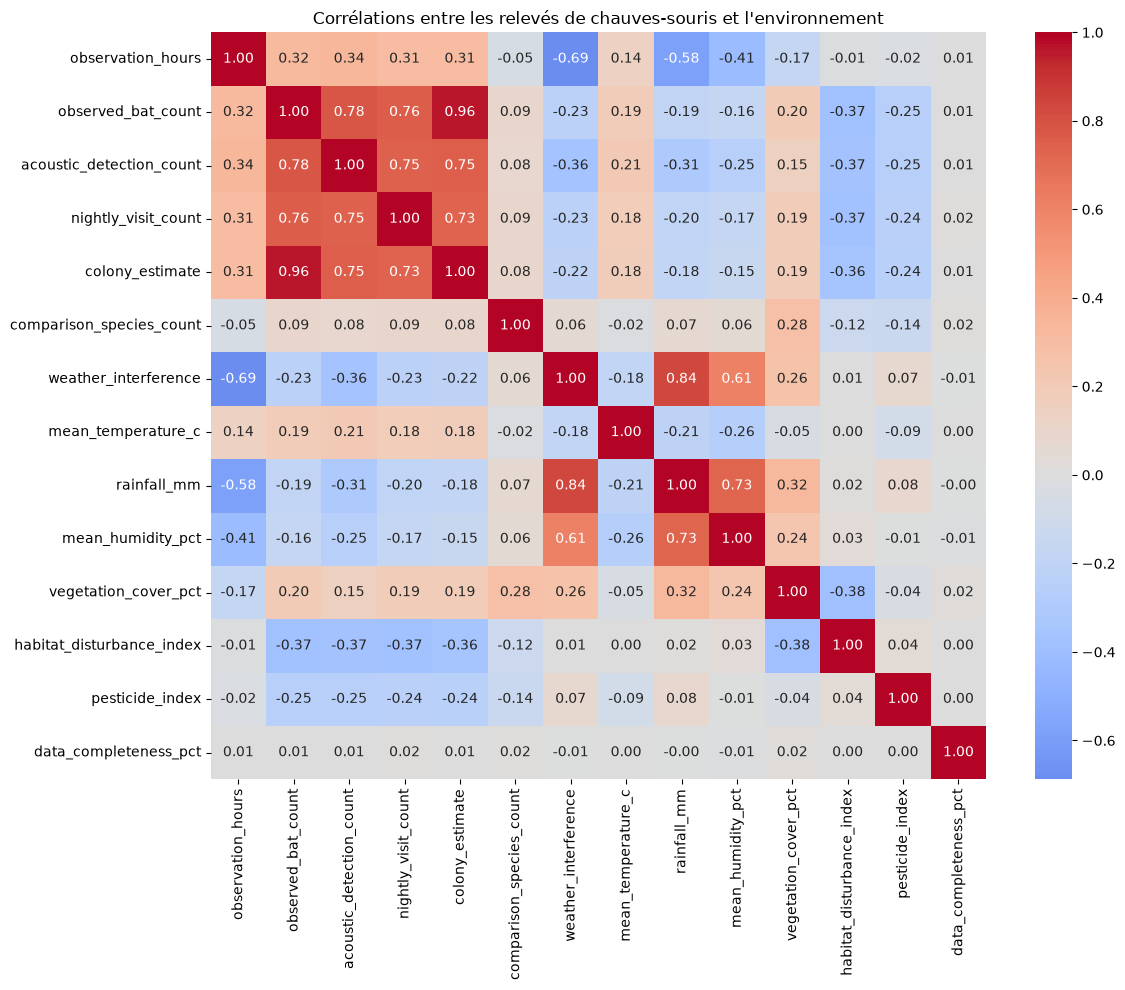

In [21]:
colonnes_numeriques = [c for c in merged.select_dtypes(include="number").columns if c != "duree_survey"]
corr = merged[colonnes_numeriques].corr()

plt.figure(figsize=(12, 10))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Corrélations entre les relevés de chauves-souris et l'environnement")
plt.tight_layout()
plt.show()

**Ce que montre la matrice.**

- **Des liens évidents** : les quatre mesures d'activité des chauves-souris (comptage, détections acoustiques, visites nocturnes, taille de colonie) sont très liées entre elles (0,73 à 0,96). C'est normal : elles mesurent la même chose. De même, la pluie, l'humidité et l'interférence météo évoluent ensemble.
- **Des liens intéressants** : deux variables du milieu sont liées négativement à l'activité :
  - la **perturbation de l'habitat** : environ −0,37 ;
  - l'**indice de pesticides** : environ −0,25.

Ces deux variables ne sont presque pas liées entre elles (0,04) : ce sont deux effets distincts. Nous regardons de plus près la relation entre perturbation et activité.

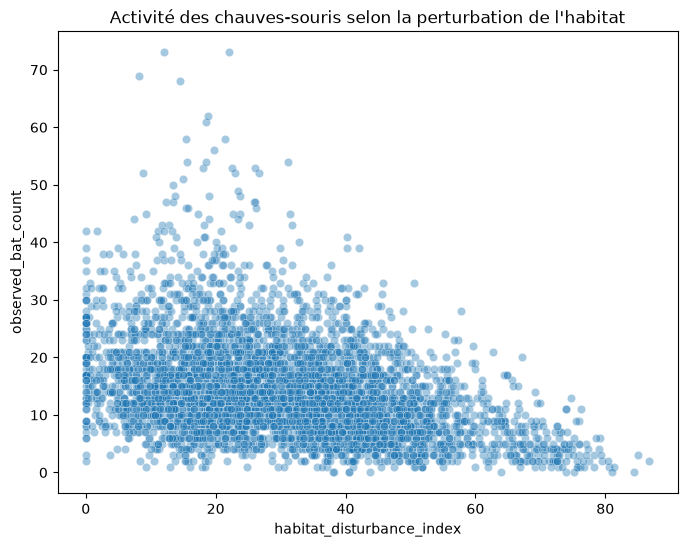

Corrélation entre perturbation et comptage :
  Pearson  : -0.375
  Spearman : -0.383


In [22]:
plt.figure(figsize=(8, 6))
sns.scatterplot(data=merged, x="habitat_disturbance_index", y="observed_bat_count", alpha=0.4)
plt.title("Activité des chauves-souris selon la perturbation de l'habitat")
plt.show()

print("Corrélation entre perturbation et comptage :")
print("  Pearson  :", round(merged["habitat_disturbance_index"].corr(merged["observed_bat_count"]), 3))
print("  Spearman :", round(merged["habitat_disturbance_index"].corr(merged["observed_bat_count"], method="spearman"), 3))

**Ce que montre le nuage de points.** Ce n'est pas une droite. Quand l'habitat est peu perturbé, l'activité peut être très faible comme très forte (de 0 à plus de 70). Quand la perturbation augmente, ce sont surtout les **valeurs les plus hautes qui disparaissent**. La perturbation semble donc limiter le nombre maximal de chauves-souris plutôt que fixer précisément chaque valeur : on parle d'**effet plafond**.

La corrélation de **Spearman**, calculée sur les rangs, mesure toute relation qui monte ou descend régulièrement, même si elle n'est pas linéaire. Elle donne presque la même valeur que Pearson (−0,38 contre −0,37) : le lien est réel, quelle que soit la méthode.

**À retenir** : l'activité baisse quand l'habitat est perturbé. Le lien est réel mais modéré, et une corrélation ne prouve pas une cause.

## 1.6 Zoom sur le site KNT-KES

**Pourquoi ce site ?** Deux indices désignent KNT-KES. Un rapport de terrain d'avril 2024 y signale un incident, et son appareil `DEV-KNTKES-2` revient plusieurs fois parmi les pannes vues en 1.2. Nous traçons l'évolution de son activité, mois par mois.

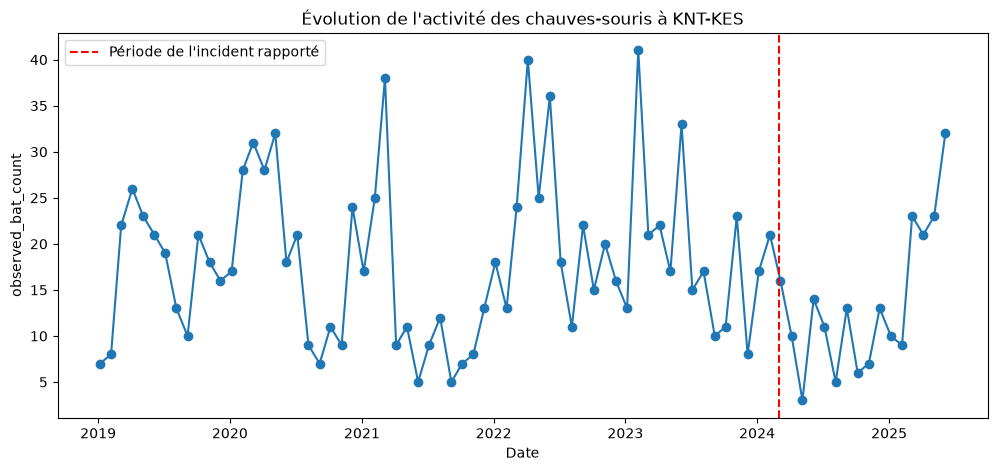

In [23]:
knt_kes = merged[merged["site_code"] == "KNT-KES"].sort_values("survey_start")

plt.figure(figsize=(12, 5))
plt.plot(knt_kes["survey_start"], knt_kes["observed_bat_count"], marker="o")
plt.axvline(pd.Timestamp("2024-03-01"), color="red", linestyle="--", label="Période de l'incident rapporté")
plt.title("Évolution de l'activité des chauves-souris à KNT-KES")
plt.xlabel("Date")
plt.ylabel("observed_bat_count")
plt.legend()
plt.show()

**Ce que montre la courbe.**

- **De 2019 au début de 2024**, l'activité varie beaucoup d'un mois à l'autre, mais le site est clairement actif, avec des pics réguliers de 30 à 40 chauves-souris (41 au début de 2023).
- **Juste après l'incident**, l'activité s'effondre : 3 chauves-souris, le minimum de toute la série sur 6 ans.
- **Jusqu'à mi-2025**, elle reste basse : les pics ne dépassent plus 10 à 14, alors qu'ils atteignaient 30 à 40 les années précédentes.
- **En 2025**, une légère reprise apparaît (21 à 32), sans revenir au niveau d'avant.

La chute coïncide donc avec l'incident décrit dans le rapport. Mais une baisse peut aussi avoir une cause générale, comme une mauvaise année pour toute la région. Pour trancher, il faut comparer KNT-KES à des sites semblables, des **sites témoins**. Nous cherchons les sites qui ont le même habitat et le même type de suivi que KNT-KES.

In [24]:
profil = dataframes["monitoring_sites"][dataframes["monitoring_sites"]["site_code"] == "KNT-KES"].iloc[0]
print("KNT-KES :", profil["site_name"], "|", profil["site_category"], "|", profil["habitat_category"], "|", profil["region"])

sites_comparables = dataframes["monitoring_sites"][
    (dataframes["monitoring_sites"]["habitat_category"] == profil["habitat_category"]) &
    (dataframes["monitoring_sites"]["site_category"] == profil["site_category"]) &
    (dataframes["monitoring_sites"]["site_code"] != "KNT-KES")
]
sites_comparables[["site_code", "site_name", "region", "habitat_category", "site_category"]]

KNT-KES : Kestrel Cavern Monitoring Site | cave monitoring | karst_habitat | Kintara Karst Cluster


,site_code,site_name,region,habitat_category,site_category
1,KNT-LUM,Luma Karst Reserve Site,Kintara Karst Cluster,karst_habitat,cave monitoring
2,KNT-SEN,Senna Ridge Cave Site,Kintara Karst Cluster,karst_habitat,cave monitoring
8,KNT-CYP,Dune Reach Monitoring Site,Kintara Karst Cluster,karst_habitat,cave monitoring
11,KNT-NNM,Mango Valley Monitoring Site,Kintara Karst Cluster,karst_habitat,cave monitoring
12,KNT-JAK,Pandan Grove Monitoring Site,Kintara Karst Cluster,karst_habitat,cave monitoring
25,KNT-BME,Ember Garden Monitoring Site,Kintara Karst Cluster,karst_habitat,cave monitoring


Six grottes karstiques de la même région ont le même profil que KNT-KES : KNT-LUM, KNT-SEN, KNT-CYP, KNT-NNM, KNT-JAK et KNT-BME. Ce seront nos sites témoins dans la partie 2.

# 2. KNT-KES face à ses sites témoins

**Pourquoi cette étape ?** En partie 1, nous avons vu l'activité de KNT-KES s'effondrer au printemps 2024. Mais une baisse peut avoir une cause banale, comme une mauvaise saison ou une météo défavorable dans toute la région. Pour le savoir, nous comparons KNT-KES aux six **sites témoins** trouvés en 1.6 : des grottes karstiques qui subissent le même climat. Si elles chutent aussi, la cause est générale. Sinon, il s'est passé quelque chose de particulier à KNT-KES.

**Comment ?** Nous comparons, mois par mois, le comptage de KNT-KES à la **médiane** des témoins. La médiane est préférée à la moyenne, parce qu'un seul témoin avec un mois exceptionnel ne la fait pas bouger.

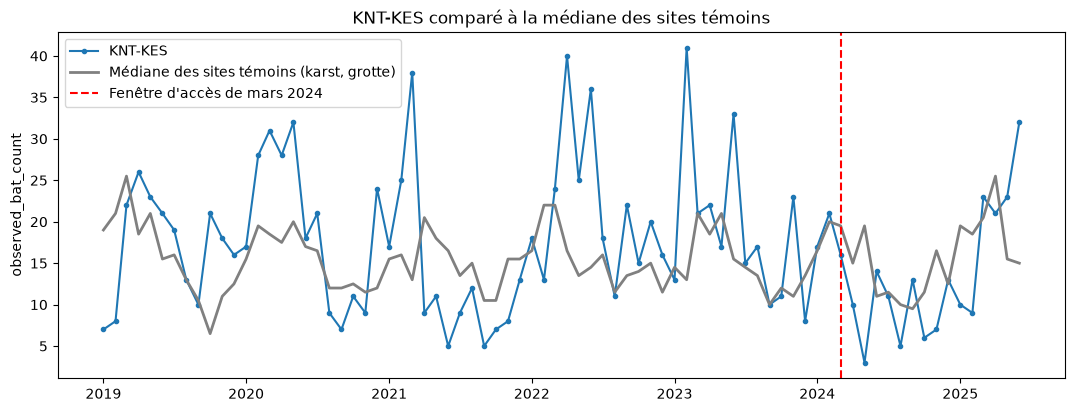

In [25]:
temoins = merged[merged["site_code"].isin(sites_comparables["site_code"])]
mediane_temoins = temoins.groupby("reporting_month")["observed_bat_count"].median()
serie_kes = (merged[merged["site_code"] == "KNT-KES"]
             .set_index("reporting_month")["observed_bat_count"].sort_index())

fig, ax = plt.subplots(figsize=(13, 4.5))
ax.plot(serie_kes.index, serie_kes.values, marker="o", ms=3, label="KNT-KES")
ax.plot(mediane_temoins.index, mediane_temoins.values, color="grey", lw=2,
        label="Médiane des sites témoins (karst, grotte)")
ax.axvline(pd.Timestamp("2024-03-01"), color="red", ls="--", label="Fenêtre d'accès de mars 2024")
ax.set_ylabel("observed_bat_count")
ax.set_title("KNT-KES comparé à la médiane des sites témoins")
ax.legend()
plt.show()

Nous résumons la comparaison par un chiffre : le **rapport** entre KNT-KES et la médiane des témoins, en moyenne sur les mois d'avril à juin de chaque année. Un rapport de 1 veut dire « comme les témoins » ; un rapport de 0,5, « deux fois moins ».

In [26]:
tableau_kes = pd.DataFrame({"KNT-KES": serie_kes, "médiane témoins": mediane_temoins})
tableau_kes["rapport"] = tableau_kes["KNT-KES"] / tableau_kes["médiane témoins"]

printemps = tableau_kes[tableau_kes.index.month.isin([4, 5, 6])]
print("Rapport moyen KNT-KES / témoins sur les mois d'avril à juin, par année :")
print(printemps.groupby(printemps.index.year)["rapport"].mean().round(2))
tableau_kes.loc["2024-01-01":"2024-09-01"].round(2)

Rapport moyen KNT-KES / témoins sur les mois d'avril à juin, par année :
reporting_month
2019    1.29
2020    1.42
2021    0.45
2022    2.25
2023    1.38
2024    0.70
2025    1.48
Name: rapport, dtype: float64


,KNT-KES,médiane témoins,rapport
reporting_month,,,
2024-01-01,17.0,16.5,1.03
2024-02-01,21.0,20.0,1.05
2024-03-01,16.0,19.5,0.82
2024-04-01,10.0,15.0,0.67
2024-05-01,3.0,19.5,0.15
2024-06-01,14.0,11.0,1.27
2024-07-01,11.0,11.5,0.96
2024-08-01,5.0,10.0,0.50
2024-09-01,13.0,9.5,1.37


Nous traçons enfin chaque grotte séparément, avec la médiane des témoins en gris, pour voir si d'autres sites décrochent aussi.

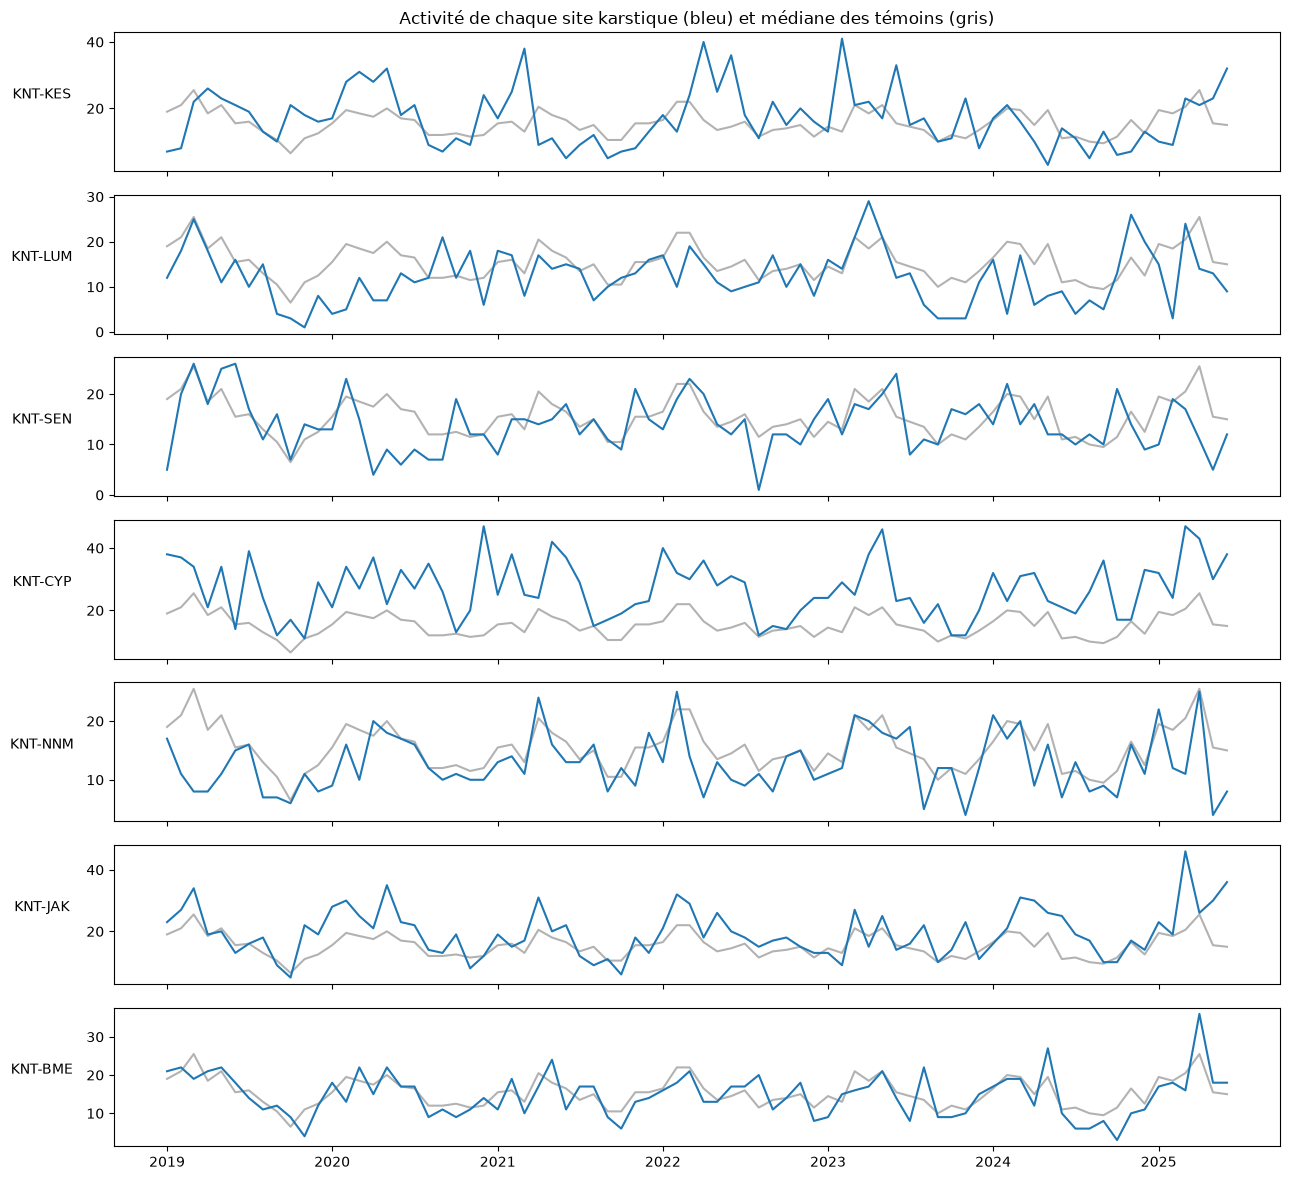

In [27]:
sites_a_tracer = ["KNT-KES"] + sites_comparables["site_code"].tolist()
fig, axes = plt.subplots(len(sites_a_tracer), 1, figsize=(13, 1.7 * len(sites_a_tracer)), sharex=True)
for ax, code_site in zip(axes, sites_a_tracer):
    s = merged[merged["site_code"] == code_site].set_index("reporting_month")["observed_bat_count"].sort_index()
    ax.plot(mediane_temoins.index, mediane_temoins.values, color="grey", alpha=0.6)
    ax.plot(s.index, s.values, color="tab:blue")
    ax.set_ylabel(code_site, rotation=0, labelpad=32)
axes[0].set_title("Activité de chaque site karstique (bleu) et médiane des témoins (gris)")
plt.tight_layout()
plt.show()

**Ce que montre la comparaison.**

- D'habitude, au printemps, KNT-KES est **plus actif** que les autres grottes : selon les années, le rapport va de 1,29 à 2,25.
- Deux printemps font exception : **2024** (rapport de 0,70) et **2021** (0,45). En mai 2024, KNT-KES compte 3 chauves-souris quand la médiane des témoins en compte 19,5.
- Les témoins, eux, ne chutent pas. **La baisse de 2024 n'est donc pas due au climat ni à la saison.**

**Un point inattendu : KNT-KES n'est pas seul.** Sur les petits graphiques, KNT-LUM décroche à l'automne 2019 puis à l'automne 2023, et KNT-SEN au printemps 2020. Pendant ce temps, KNT-CYP, KNT-NNM, KNT-JAK et KNT-BME suivent la médiane. Des chutes à des dates différentes selon les sites ne peuvent pas venir d'une cause climatique commune. Nous gardons cette piste pour la suite.

# 3. Finir le nettoyage (cours 1)

La partie 1 a corrigé les nombres et les dates. En relisant les valeurs de chaque colonne, il reste quatre problèmes :

1. **Des catégories écrites de plusieurs façons** : `routine inspection`, `ROUTINE INSPECTION` et `Routine Inspection` désignent la même chose.
2. **Des lignes en double**, avec le même identifiant.
3. **Des types ou des unités incohérents** : `acoustic_quality` est stockée en texte, et quelques taux de nouaison sont écrits en fraction (0,47) au lieu d'un pourcentage (47 %).
4. **Des valeurs manquantes** : pour chacune, il faut décider s'il faut la compléter, ou si son absence veut dire quelque chose.

Chaque choix de nettoyage peut biaiser la suite. Nous expliquons donc chaque décision.

Nous chargeons d'abord toutes les bibliothèques utilisées dans la suite du rapport.

In [28]:
# Bibliothèques utilisées dans la suite du rapport
import re
import warnings
import contextlib
import io
from collections import Counter

import networkx as nx
from networkx.algorithms import bipartite
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from scipy.spatial import Voronoi, voronoi_plot_2d
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import pairwise_distances, silhouette_score, adjusted_rand_score
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.decomposition import PCA, TruncatedSVD, LatentDirichletAllocation
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.neighbors import NearestNeighbors, LocalOutlierFactor
from sklearn.ensemble import IsolationForest
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer, ENGLISH_STOP_WORDS
from mlxtend.frequent_patterns import apriori, association_rules
from statsmodels.tsa.seasonal import STL, seasonal_decompose
from statsmodels.graphics.tsaplots import plot_acf

with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
    import pm4py   # pm4py affiche une bannière de licence à l'import

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

## 3.1 Harmoniser les catégories

Nous affichons d'abord les modalités telles qu'elles sont saisies. Les colonnes qui contiennent des **codes** (`fault_code`, `observer_team`, `weather_exception_code`, `maintenance_provider`) ne sont pas concernées : ce sont des identifiants, déjà écrits de façon cohérente.

In [29]:
colonnes_categorielles = {
    "bat_surveys": ["survey_method", "survey_quality"],
    "environmental_monthly": ["land_use_category"],
    "monitoring_device_operations": ["maintenance_type", "record_status"],
    "orchard_surveys": ["agricultural_disturbance_note"],
    "monitoring_sites": ["site_category", "habitat_category", "cave_access_category"],
}
for table, colonnes in colonnes_categorielles.items():
    for col in colonnes:
        print(f"{table}.{col} :", dataframes[table][col].value_counts().to_dict())

bat_surveys.survey_method : {'acoustic_and_visual': 1743, 'acoustic_transect': 1617, 'fixed_acoustic_station': 1614, 'FIXED_ACOUSTIC_STATION': 9, 'ACOUSTIC_AND_VISUAL': 4, 'ACOUSTIC_TRANSECT': 4, 'Fixed_Acoustic_Station': 2, 'Acoustic_Transect': 1}
bat_surveys.survey_quality : {'high': 2690, 'acceptable': 2166, 'limited': 138}
environmental_monthly.land_use_category : {'mixed_forest': 1481, 'coastal_habitat': 780, 'durian_orchard': 777, 'karst_habitat': 697, 'research_site': 467, 'mixed_agriculture': 388, 'protected_forest': 234, 'degraded_land': 153, 'Karst_Habitat': 4, 'DEGRADED_LAND': 2, 'DURIAN_ORCHARD': 2, 'Degraded_Land': 1, 'KARST_HABITAT': 1, 'Research_Site': 1, 'Durian_Orchard': 1, 'MIXED_AGRICULTURE': 1, 'Mixed_Agriculture': 1, 'Mixed_Forest': 1}
monitoring_device_operations.maintenance_type : {'routine inspection': 4785, 'corrective maintenance': 137, 'sensor replacement': 52, 'ROUTINE INSPECTION': 12, 'Routine Inspection': 8}
monitoring_device_operations.record_status : {'c

La fonction `normaliser_categorie` met le texte en minuscules et retire les espaces en trop. Nous l'appliquons à chaque colonne, puis nous comptons les modalités avant et après.

In [30]:
def normaliser_categorie(serie):
    # minuscules + espaces superflus supprimés : "  Routine  Inspection " -> "routine inspection"
    return serie.str.strip().str.lower().str.replace(r"\s+", " ", regex=True)

for table, colonnes in colonnes_categorielles.items():
    for col in colonnes:
        avant = dataframes[table][col].nunique()
        dataframes[table][col] = normaliser_categorie(dataframes[table][col])
        print(f"{table}.{col} : {avant} -> {dataframes[table][col].nunique()} modalités")

bat_surveys.survey_method : 8 -> 3 modalités
bat_surveys.survey_quality : 3 -> 3 modalités
environmental_monthly.land_use_category : 18 -> 8 modalités
monitoring_device_operations.maintenance_type : 5 -> 3 modalités
monitoring_device_operations.record_status : 3 -> 1 modalités
orchard_surveys.agricultural_disturbance_note : 4 -> 2 modalités
monitoring_sites.site_category : 4 -> 3 modalités
monitoring_sites.habitat_category : 8 -> 8 modalités
monitoring_sites.cave_access_category : 2 -> 2 modalités


Pour chaque catégorie, nous gardons la version en minuscules, qui était déjà la plus fréquente. Aucune modalité n'a été fusionnée à tort : après correction, le nombre de modalités correspond aux catégories réellement différentes.

## 3.2 Supprimer les doublons

Le dictionnaire des données indique, pour chaque table, la colonne qui doit identifier chaque ligne de façon unique (la clé primaire). Nous cherchons les identifiants qui apparaissent plusieurs fois, et nous vérifions si les lignes concernées sont identiques.

In [31]:
cles_primaires = [("bat_surveys", "survey_id"), ("monitoring_device_operations", "device_operation_id"),
                  ("orchard_surveys", "orchard_survey_id")]
for table, cle in cles_primaires:
    df = dataframes[table]
    concernes = df[df[cle].duplicated(keep=False)].sort_values(cle)
    print(f"{table} : {len(concernes)} lignes partagent un identifiant ; "
          f"lignes strictement identiques (toutes colonnes) : {df.duplicated().sum()}")
    display(concernes.iloc[:, :8])

bat_surveys : 4 lignes partagent un identifiant ; lignes strictement identiques (toutes colonnes) : 2


,survey_id,site_code,survey_start,survey_end,survey_method,observation_hours,observed_bat_count,acoustic_detection_count
3182,BAT-0003183,AVL-ABG,2024-03-05 18:00:00,2024-03-12,acoustic_and_visual,38.7,8.0,18.0
4992,BAT-0003183,AVL-ABG,2024-03-05 18:00:00,2024-03-12,acoustic_and_visual,38.7,8.0,18.0
3566,BAT-0003567,AVL-FNQ,2023-09-05 18:00:00,2023-09-12,acoustic_transect,28.9,13.0,4.0
4993,BAT-0003567,AVL-FNQ,2023-09-05 18:00:00,2023-09-12,acoustic_transect,28.9,13.0,4.0


monitoring_device_operations : 4 lignes partagent un identifiant ; lignes strictement identiques (toutes colonnes) : 2


,device_operation_id,site_code,device_reference,operation_start,operation_end,uptime_pct,acoustic_quality,maintenance_type
1225,DOP-0001226,KNT-CHP,DEV-KNTCHP-3,2023-08-01,2023-08-31 23:59:59,93.2,73.5,routine inspection
4993,DOP-0001226,KNT-CHP,DEV-KNTCHP-3,2023-08-01,2023-08-31 23:59:59,93.2,73.5,routine inspection
1390,DOP-0001391,KNT-WUQ,DEV-KNTWUQ-2,2024-05-01,2024-05-31 23:59:59,92.7,78.6,routine inspection
4992,DOP-0001391,KNT-WUQ,DEV-KNTWUQ-2,2024-05-01,2024-05-31 23:59:59,92.7,78.6,routine inspection


orchard_surveys : 4 lignes partagent un identifiant ; lignes strictement identiques (toutes colonnes) : 2


,orchard_survey_id,site_code,survey_period,orchard_area_ha,durian_flower_density,fruit_set_rate_pct,durian_yield_kg,other_pollinator_activity
892,ORC-0000893,AVL-NMQ,2021-11-01,31.3,60.2,58.7,36453.0,70.7
1248,ORC-0000893,AVL-NMQ,2021-11-01,31.3,60.2,58.7,36453.0,70.7
1189,ORC-0001190,TMB-HQL,2020-08-01,44.2,33.4,33.3,27989.9,44.0
1249,ORC-0001190,TMB-HQL,2020-08-01,44.2,33.4,33.3,27989.9,44.0


Les lignes en double sont identiques sur toutes les colonnes : nous gardons la première de chaque paire.

In [32]:
for table, cle in cles_primaires:
    dataframes[table] = dataframes[table].drop_duplicates(subset=cle, keep="first").reset_index(drop=True)
    print(table, "->", dataframes[table].shape)

bat_surveys -> (4992, 16)
monitoring_device_operations -> (4992, 11)
orchard_surveys -> (1248, 11)


**Résultat.** Les lignes en double sont **identiques sur toutes les colonnes** et réutilisent un identifiant qui devrait être unique (`survey_id`, `device_operation_id`, `orchard_survey_id`). Nous les supprimons, comme les doublons de `environmental_monthly` en partie 1. Les garder aurait compté deux fois les mêmes relevés pour six sites : AVL-ABG, AVL-FNQ, KNT-CHP, KNT-WUQ, et les vergers AVL-NMQ et TMB-HQL.

## 3.3 Corriger les types et les unités

`acoustic_quality` est convertie en nombre, avec la même correction de virgule qu'en partie 1. Pour le taux de nouaison (la part des fleurs qui donnent un fruit), nous repérons les valeurs inférieures ou égales à 1, qui ressemblent à des fractions.

In [33]:
dataframes["monitoring_device_operations"]["acoustic_quality"] = pd.to_numeric(
    dataframes["monitoring_device_operations"]["acoustic_quality"].astype(str).str.replace(",", ".", regex=False),
    errors="coerce",
)
print("acoustic_quality : valeurs non convertibles =",
      dataframes["monitoring_device_operations"]["acoustic_quality"].isna().sum())

orc = dataframes["orchard_surveys"]
fractions = orc["fruit_set_rate_pct"] <= 1
print("Nombre de taux de nouaison <= 1 :", fractions.sum())
display(orc.loc[fractions, ["orchard_survey_id", "site_code", "survey_period", "fruit_set_rate_pct"]])
print("Autres valeurs :", orc.loc[~fractions, "fruit_set_rate_pct"].describe().round(1).to_dict())

acoustic_quality : valeurs non convertibles = 0
Nombre de taux de nouaison <= 1 : 8


,orchard_survey_id,site_code,survey_period,fruit_set_rate_pct
269,ORC-0000270,AVL-TRP,2021-12-01,0.568
412,ORC-0000413,AVL-GRB,2020-11-01,0.543
454,ORC-0000455,AVL-GRB,2024-05-01,0.549
716,ORC-0000717,AVL-YAU,2020-03-01,0.561
718,ORC-0000719,AVL-YAU,2020-05-01,0.595
919,ORC-0000920,AVL-NMQ,2024-02-01,0.467
1060,ORC-0001061,TMB-BRC,2022-11-01,0.581
1180,ORC-0001181,TMB-HQL,2019-11-01,0.555


Autres valeurs : {'count': 1240.0, 'mean': 53.5, 'std': 9.3, 'min': 27.3, '25%': 47.0, '50%': 52.9, '75%': 59.4, 'max': 87.7}


Nous multiplions ces valeurs par 100 pour les ramener en pourcentage.

In [34]:
orc.loc[fractions, "fruit_set_rate_pct"] = orc.loc[fractions, "fruit_set_rate_pct"] * 100
orc["fruit_set_rate_pct"].describe().round(1)

count    1248.0
mean       53.6
std         9.3
min        27.3
25%        47.0
50%        53.0
75%        59.4
max        87.7
Name: fruit_set_rate_pct, dtype: float64

Huit taux de nouaison valent entre 0,47 et 0,60, alors que les autres vont d'environ 13 à 88 %. Un taux inférieur à 1 % n'aurait pas de sens pour un verger en production. En revanche, 0,47 à 0,60 correspond très bien à 47 à 60 % écrits **en fraction** : c'est un problème d'unité (cours 1). Nous convertissons ces 8 valeurs en pourcentage plutôt que de les supprimer.

## 3.4 Traiter les valeurs manquantes

Nous comptons d'abord les valeurs manquantes, table par table.

In [35]:
tables_eco = ["bat_surveys", "environmental_monthly", "monitoring_device_operations", "orchard_surveys",
              "monitoring_sites", "environmental_field_reports"]
manquants = pd.concat({t: dataframes[t].isna().sum() for t in tables_eco}, names=["table", "colonne"])
manquants = manquants[manquants > 0].to_frame("nb_manquants")
manquants["pct"] = [round(100 * n / len(dataframes[t]), 2)
                    for (t, _), n in zip(manquants.index, manquants["nb_manquants"])]
manquants

nb_manquants  \
table                        colonne                                       
bat_surveys                  observer_team                            20   
environmental_monthly        vegetation_cover_pct                     10   
                             pesticide_index                          15   
                             weather_exception_code                 4788   
monitoring_device_operations fault_code                             4803   
                             maintenance_provider                     30   
orchard_surveys              agricultural_disturbance_note          1225   
monitoring_sites             elevation_m                               1   
                             programme_end_date                       64   
environmental_field_reports  author_name                               1   

                                                               pct  
table                        colonne                                
bat_surveys                  observer_team                    0.40  
environmental_monthly        vegetation_cover_pct             0.20  
                             pesticide_index                  0.30  
                             weather_exception_code          95.91  
monitoring_device_operations fault_code                      96.21  
                             maintenance_provider             0.60  
orchard_surveys              agricultural_disturbance_note   98.16  
monitoring_sites             elevation_m                      1.56  
                             programme_end_date             100.00  
environmental_field_reports  author_name                      3.33

Pour chaque colonne, nous décidons s'il faut compléter les valeurs manquantes ou les laisser vides :

| Colonne | Décision | Pourquoi |
|---|---|---|
| `fault_code`, `weather_exception_code`, `agricultural_disturbance_note`, `programme_end_date` | laissées vides | Ici, l'absence **est une information** : pas de panne, pas d'exception météo, rien à signaler, programme toujours en cours. Inventer une valeur serait faux. |
| `vegetation_cover_pct`, `pesticide_index` | complétées par la médiane du site, dans une nouvelle colonne `_impute` | Moins de 0,3 % de manquants. Ces variables dépendent surtout du site, et la médiane n'est pas influencée par les valeurs extrêmes. Les colonnes d'origine restent intactes : seules les méthodes qui exigent des données complètes (ACP, regroupements) utilisent les versions complétées. |
| `elevation_m` (KNT-CYP) | complétée par la médiane des sites karstiques de Kintara | Un seul site concerné, de profil karstique. |
| `observer_team`, `maintenance_provider`, `author_name` | laissées vides | Ce sont des identifiants : ils ne servent ni aux calculs ni aux distances. |

In [36]:
env = dataframes["environmental_monthly"]
for col in ["vegetation_cover_pct", "pesticide_index"]:
    env[col + "_impute"] = env[col].fillna(env.groupby("site_code")[col].transform("median"))
    print(f"{col} : {env[col].isna().sum()} -> {env[col + '_impute'].isna().sum()} manquants")

sites = dataframes["monitoring_sites"]
display(sites.loc[sites["elevation_m"].isna(), ["site_code", "site_name", "habitat_category", "region"]])
alt_karst = sites.loc[(sites["habitat_category"] == "karst_habitat")
                      & (sites["region"] == "Kintara Karst Cluster"), "elevation_m"].median()
sites["elevation_m"] = sites["elevation_m"].fillna(alt_karst)
print("Altitude imputée :", alt_karst)

vegetation_cover_pct : 10 -> 0 manquants
pesticide_index : 15 -> 0 manquants


,site_code,site_name,habitat_category,region
8,KNT-CYP,Dune Reach Monitoring Site,karst_habitat,Kintara Karst Cluster


Altitude imputée : 185.4


## 3.5 Une table d'analyse unique : `eco`

Pour la suite, il est plus simple de travailler sur une seule table. Nous réunissons les relevés de chauves-souris, l'environnement du mois, l'état de l'appareil et les caractéristiques du site, avec une ligne par site et par mois.

Nous ajoutons une variable : le **taux horaire**, c'est-à-dire le nombre de chauves-souris observées par heure d'observation. La durée d'observation varie de 5 à 47 heures selon les mois, et plus on observe longtemps, plus on compte de chauves-souris. Diviser par la durée corrige ce **biais d'effort**.

In [37]:
dev = dataframes["monitoring_device_operations"].copy()
dev["reporting_month"] = dev["operation_start"].dt.to_period("M").dt.to_timestamp()

eco = (
    dataframes["bat_surveys"]
    .merge(dataframes["environmental_monthly"], on=["site_code", "reporting_month"], how="inner")
    .merge(dev[["site_code", "reporting_month", "device_reference", "uptime_pct", "acoustic_quality",
                "maintenance_type", "fault_code"]], on=["site_code", "reporting_month"], how="left")
    .merge(dataframes["monitoring_sites"][["site_code", "site_name", "site_category", "region", "habitat_category",
                                           "latitude", "longitude", "elevation_m"]], on="site_code", how="left")
    .sort_values(["site_code", "reporting_month"]).reset_index(drop=True)
)
eco["mois_calendaire"] = eco["reporting_month"].dt.month
eco["annee"] = eco["reporting_month"].dt.year
eco["taux_horaire"] = eco["observed_bat_count"] / eco["observation_hours"]

print("Dimensions :", eco.shape)
print("Une seule ligne par (site, mois) :", not eco.duplicated(["site_code", "reporting_month"]).any())
print("Nombre de mois par site :", eco.groupby("site_code").size().unique())
print("Période couverte :", eco["reporting_month"].min().date(), "->", eco["reporting_month"].max().date())
print("Appareil manquant pour un mois :", eco["uptime_pct"].isna().sum())
eco[["observed_bat_count", "observation_hours", "taux_horaire"]].corr(method="spearman").round(2)

Dimensions : (4992, 42)


Une seule ligne par (site, mois) : True
Nombre de mois par site : [78]
Période couverte : 2019-01-01 -> 2025-06-01
Appareil manquant pour un mois : 0


,observed_bat_count,observation_hours,taux_horaire
observed_bat_count,1.00,0.32,0.94
observation_hours,0.32,1.00,0.02
taux_horaire,0.94,0.02,1.00


Nous préparons aussi une table pour les vergers : chaque relevé de verger y est associé à l'activité des chauves-souris du même mois. Elle servira en partie 10.

In [38]:
verger = (dataframes["orchard_surveys"].rename(columns={"survey_period": "reporting_month"})
          .merge(eco[["site_code", "reporting_month", "observed_bat_count", "taux_horaire",
                      "comparison_species_count"]], on=["site_code", "reporting_month"], how="left"))
print(verger.shape, "-", verger["observed_bat_count"].isna().sum(), "mois de verger sans relevé de chauves-souris")
print("Sites de vergers :", verger["site_code"].nunique())

(1248, 14) - 0 mois de verger sans relevé de chauves-souris


Sites de vergers : 16


**Bilan du nettoyage.**

- Catégories harmonisées : `land_use_category` passe de 18 à 8 modalités, `survey_method` de 8 à 3, `record_status` de 3 à 1.
- 6 lignes en double supprimées : 2 relevés de chauves-souris, 2 opérations d'appareil et 2 relevés de vergers.
- 8 taux de nouaison convertis de fraction en pourcentage.
- 25 valeurs environnementales et 1 altitude complétées par une médiane, dans des colonnes séparées.

La table `eco` compte **4 992 lignes, soit exactement 64 sites × 78 mois** (de janvier 2019 à juin 2025), sans aucun mois manquant. Le taux horaire était le bon choix : le comptage brut augmente avec la durée d'observation (Spearman 0,32), le taux horaire non (0,02).

# 4. Décrire les variables (cours 1)

Avant de chercher des liens, il faut connaître chaque variable : son ordre de grandeur, sa dispersion, la forme de sa distribution. Comme le recommande le cours 1, nous donnons la **moyenne avec l'écart-type**, et la **médiane avec le minimum, le maximum et les quartiles**. Nous ajoutons l'**asymétrie** (*skewness*) : quand elle est nettement positive, la distribution a une longue traîne vers les grandes valeurs, et la moyenne devient trompeuse.

In [39]:
variables_cles = ["observed_bat_count", "taux_horaire", "colony_estimate", "comparison_species_count",
                  "observation_hours", "weather_interference", "mean_temperature_c", "rainfall_mm",
                  "mean_humidity_pct", "vegetation_cover_pct", "habitat_disturbance_index",
                  "pesticide_index", "uptime_pct", "acoustic_quality"]
desc = eco[variables_cles].describe().T
desc["asymetrie"] = eco[variables_cles].skew()
desc[["mean", "std", "min", "25%", "50%", "75%", "max", "asymetrie"]].round(2)

,mean,std,min,25%,50%,75%,max,asymetrie
observed_bat_count,14.13,8.25,0.0,8.00,13.00,18.00,73.00,1.42
taux_horaire,0.47,0.26,0.0,0.29,0.42,0.60,2.42,1.40
colony_estimate,15.83,9.60,0.0,9.30,14.20,20.50,99.60,1.48
comparison_species_count,10.71,3.45,1.0,8.00,11.00,13.00,26.00,0.33
observation_hours,30.33,5.50,5.0,26.90,30.60,34.10,46.90,-0.37
weather_interference,37.49,16.66,0.0,25.10,36.70,49.00,100.00,0.33
mean_temperature_c,26.38,1.67,21.3,25.19,26.35,27.61,32.00,-0.03
rainfall_mm,159.89,74.90,5.0,95.70,156.25,221.70,384.30,0.18
mean_humidity_pct,75.84,7.25,56.7,70.30,75.90,81.50,96.40,-0.01
vegetation_cover_pct,61.01,14.00,15.0,52.70,62.30,70.90,98.00,-0.44


Les histogrammes montrent la forme de chaque distribution. La ligne rouge est la moyenne, la ligne noire en pointillés la médiane : quand elles s'écartent, la distribution est asymétrique.

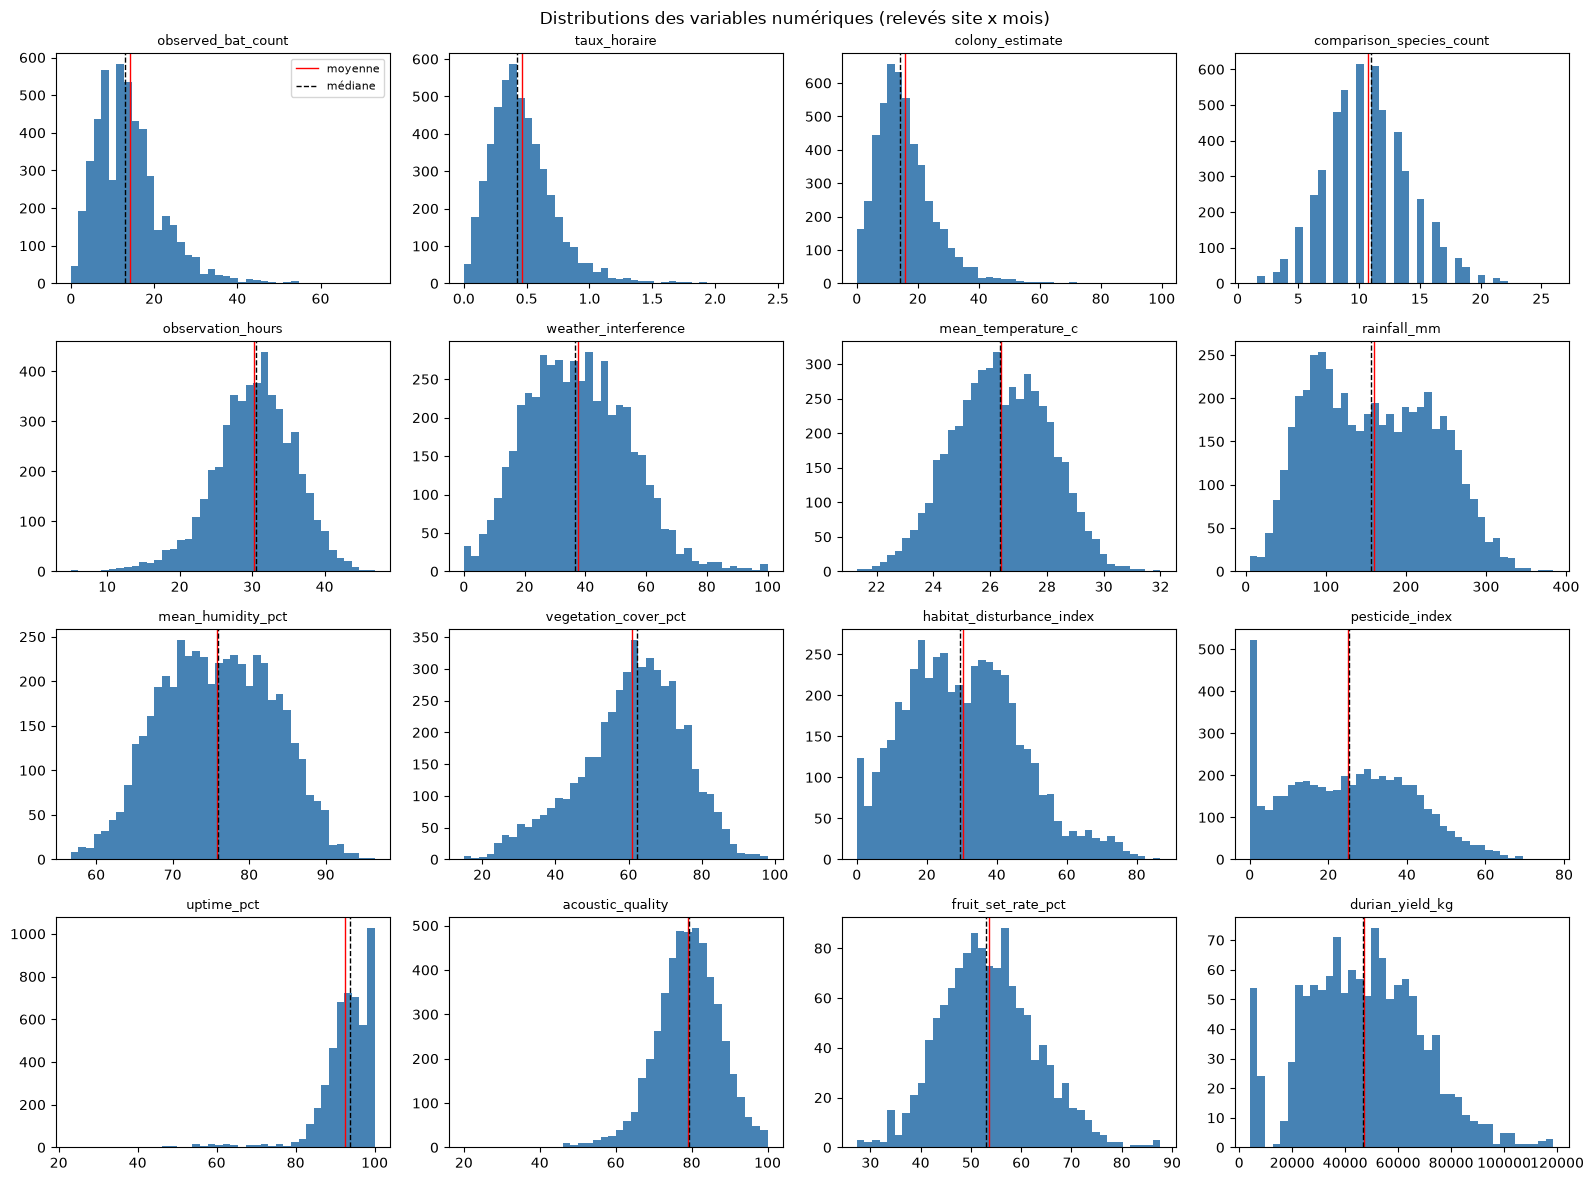

In [40]:
fig, axes = plt.subplots(4, 4, figsize=(16, 12))
for ax, col in zip(axes.flat, variables_cles + ["fruit_set_rate_pct", "durian_yield_kg"]):
    donnees = eco[col] if col in eco.columns else verger[col]
    ax.hist(donnees.dropna(), bins=40, color="steelblue")
    ax.axvline(donnees.mean(), color="red", lw=1, label="moyenne")
    ax.axvline(donnees.median(), color="black", lw=1, ls="--", label="médiane")
    ax.set_title(col, fontsize=9)
axes[0, 0].legend(fontsize=8)
plt.suptitle("Distributions des variables numériques (relevés site x mois)")
plt.tight_layout()
plt.show()

**Ce que montrent les distributions.**

- **Comptages de chauves-souris** (comptage, taux horaire, taille de colonie) : la plupart des valeurs sont moyennes, mais quelques mois montent très haut, jusqu'à 73 chauves-souris (asymétrie ≈ 1,4). La moyenne est donc tirée vers le haut. Pour comparer, nous utiliserons plutôt des **médianes** et un **logarithme** (`log1p`), qui réduit le poids des grandes valeurs.
- **Variables environnementales** (température, pluie, humidité, perturbation, pesticides) : distributions à peu près symétriques. La moyenne et l'écart-type les décrivent bien.
- **`uptime_pct`** : presque tous les mois dépassent 90 %, mais quelques pannes descendent jusqu'à 23 %.
- **Taux de nouaison** : centré sur 53 %. Il n'y a plus de valeurs proches de 0 depuis la correction de la partie 3.3.

Nous comparons maintenant l'activité selon le type de site (boîtes à moustaches) et selon la région (diagrammes en violon, qui montrent toute la forme de la distribution).

C:\Users\hp\miniconda3\envs\datamining-projet\Lib\site-packages\seaborn\categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)


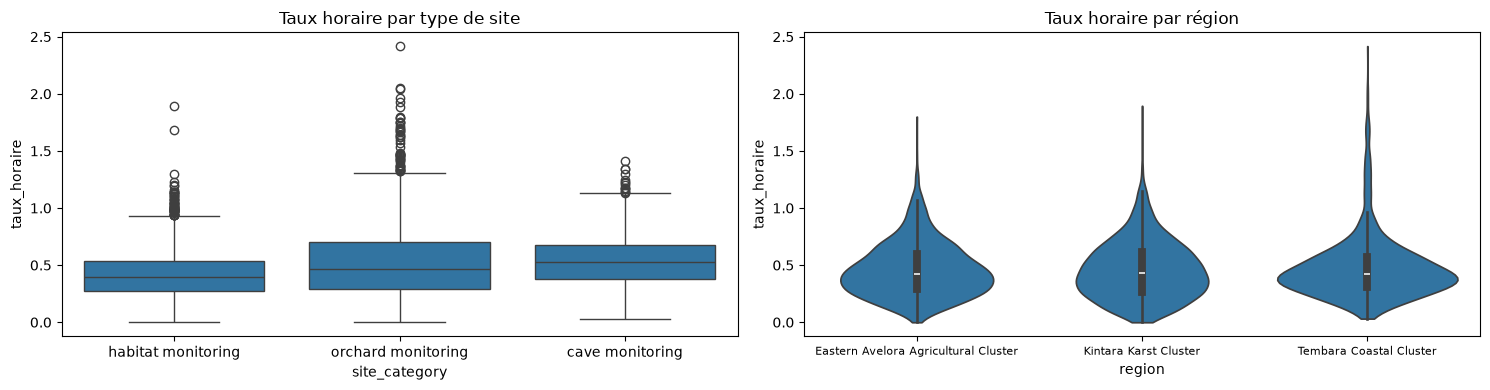

In [41]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
sns.boxplot(data=eco, x="site_category", y="taux_horaire", ax=axes[0])
axes[0].set_title("Taux horaire par type de site")
sns.violinplot(data=eco, x="region", y="taux_horaire", ax=axes[1], cut=0)
axes[1].set_title("Taux horaire par région")
axes[1].tick_params(axis="x", labelsize=8)
plt.tight_layout()
plt.show()

Pour les variables nominales, c'est-à-dire des catégories sans ordre, nous comptons simplement combien de fois chaque modalité apparaît.

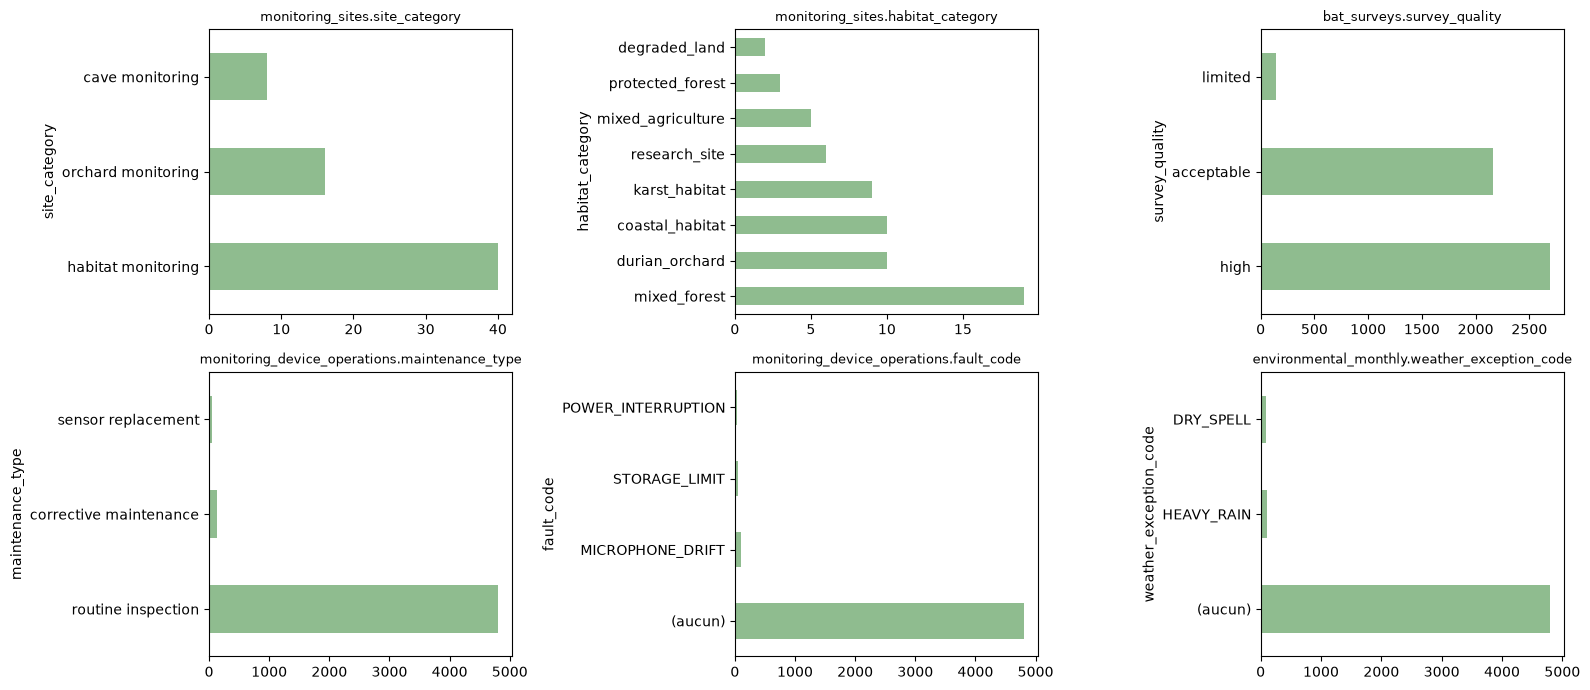

In [42]:
fig, axes = plt.subplots(2, 3, figsize=(16, 7))
for ax, (table, col) in zip(axes.flat, [("monitoring_sites", "site_category"), ("monitoring_sites", "habitat_category"),
                                        ("bat_surveys", "survey_quality"), ("monitoring_device_operations", "maintenance_type"),
                                        ("monitoring_device_operations", "fault_code"),
                                        ("environmental_monthly", "weather_exception_code")]):
    dataframes[table][col].fillna("(aucun)").value_counts().plot.barh(ax=ax, color="darkseagreen")
    ax.set_title(f"{table}.{col}", fontsize=9)
plt.tight_layout()
plt.show()

**Par type de site et par région.** Les vergers ont l'activité la plus variable, avec beaucoup de valeurs hautes (jusqu'à 2,4 chauves-souris par heure). Les grottes ont la médiane la plus élevée. Les trois régions ont des distributions presque identiques : la région, à elle seule, n'explique pas l'activité.

**Variables nominales.** On compte 40 sites d'habitat, 16 vergers et 8 grottes ; la forêt mixte est l'habitat le plus fréquent. Les événements techniques sont rares :

- relevés de qualité « limitée » : 2,8 % ;
- maintenances correctives : 2,7 % ;
- codes de panne : 3,8 % ;
- exceptions météo : 4,1 %.

Ces quelques mois risquent pourtant de produire des valeurs anormales **à cause de la mesure**, sans rapport avec les chauves-souris. Nous en tiendrons compte en partie 6.

## 4.1 Corrélations : Pearson et Spearman

En partie 1, nous n'avions calculé la corrélation de Spearman que pour une seule paire de variables. Le cours recommande de calculer les deux coefficients partout :

- **Pearson** mesure une relation **linéaire**, en ligne droite ;
- **Spearman** travaille sur les rangs : il mesure toute relation qui monte ou descend régulièrement, même si elle n'est pas droite, et résiste mieux aux valeurs extrêmes.

Si les deux coefficients sont très différents, la relation n'est pas linéaire, ou des valeurs extrêmes pèsent sur le résultat.

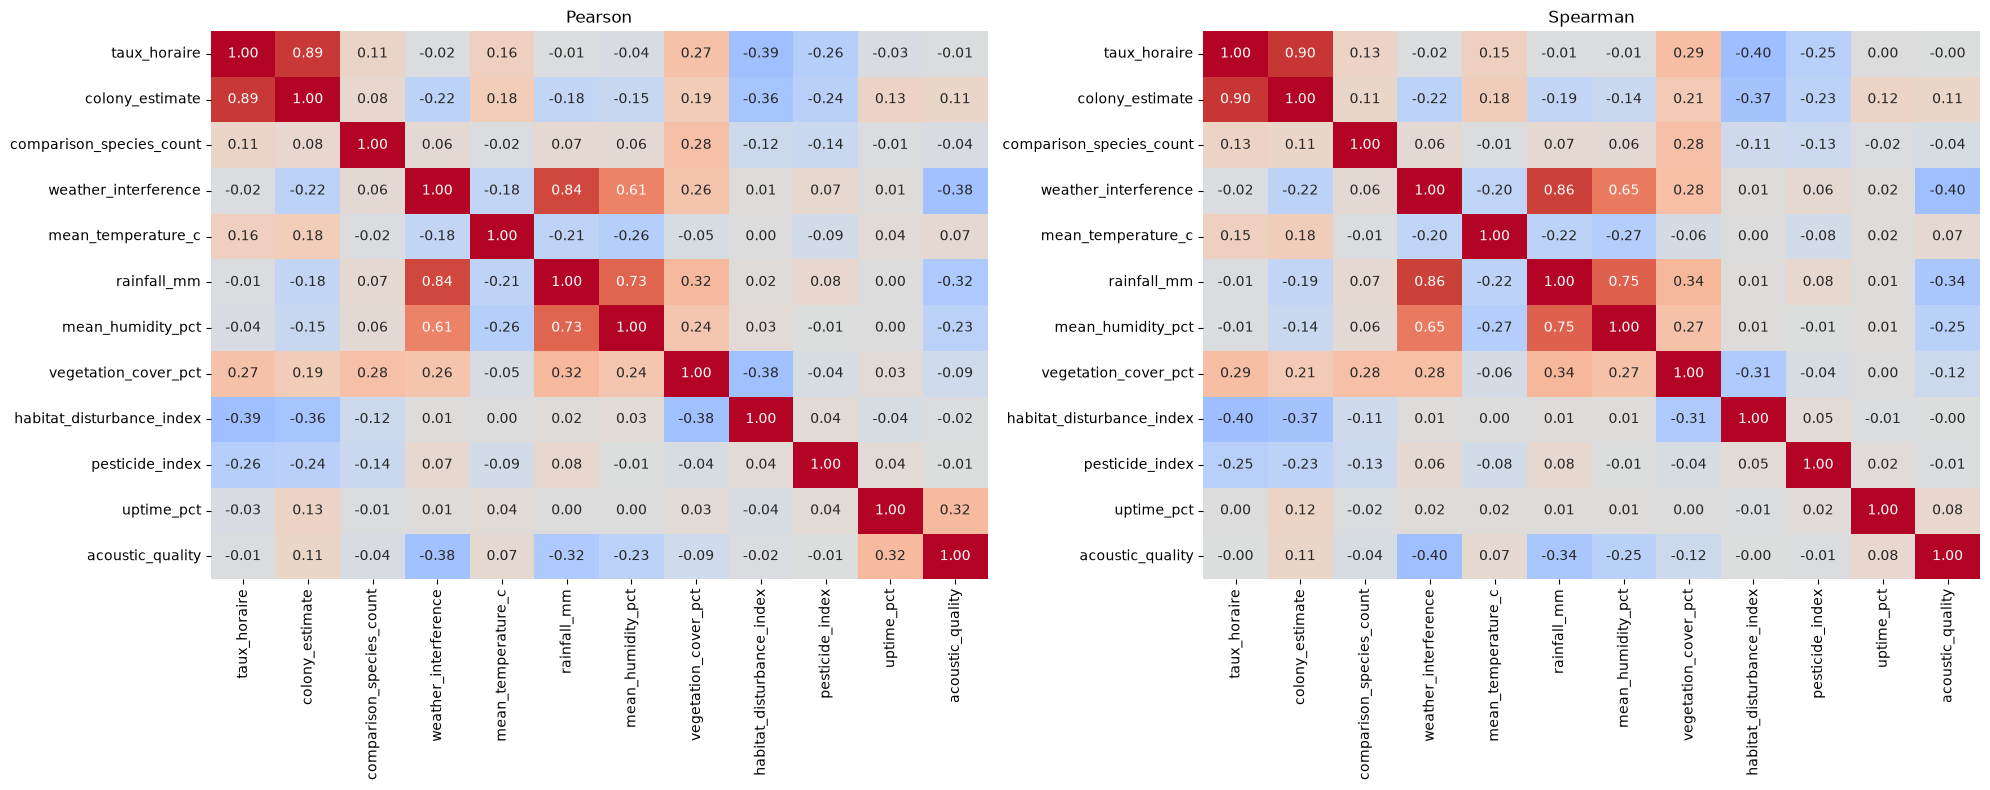

In [43]:
vars_corr = ["taux_horaire", "colony_estimate", "comparison_species_count", "weather_interference",
             "mean_temperature_c", "rainfall_mm", "mean_humidity_pct", "vegetation_cover_pct",
             "habitat_disturbance_index", "pesticide_index", "uptime_pct", "acoustic_quality"]
corr_p = eco[vars_corr].corr(method="pearson")
corr_s = eco[vars_corr].corr(method="spearman")

fig, axes = plt.subplots(1, 2, figsize=(20, 8))
for ax, (nom, c) in zip(axes, [("Pearson", corr_p), ("Spearman", corr_s)]):
    sns.heatmap(c, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1, ax=ax, cbar=False)
    ax.set_title(nom)
plt.tight_layout()
plt.show()

Nous cherchons les paires de variables où Pearson et Spearman diffèrent le plus, puis nous listons les corrélations de chaque variable avec le taux horaire.

In [44]:
triangle = np.triu(np.ones(corr_p.shape, dtype=bool), k=1)
ecarts_corr = (corr_s - corr_p).where(triangle).stack()
print("Plus grands écarts Spearman - Pearson :")
print(ecarts_corr.reindex(ecarts_corr.abs().sort_values(ascending=False).index).head(6).round(2))
print("\nCorrélations de Spearman avec le taux horaire :")
print(corr_s["taux_horaire"].drop("taux_horaire").sort_values().round(2))

Plus grands écarts Spearman - Pearson :
uptime_pct                 acoustic_quality            -0.23
vegetation_cover_pct       habitat_disturbance_index    0.08
weather_interference       mean_humidity_pct            0.04
taux_horaire               uptime_pct                   0.03
habitat_disturbance_index  uptime_pct                   0.03
vegetation_cover_pct       acoustic_quality            -0.03
dtype: float64

Corrélations de Spearman avec le taux horaire :
habitat_disturbance_index   -0.40
pesticide_index             -0.25
weather_interference        -0.02
mean_humidity_pct           -0.01
rainfall_mm                 -0.01
acoustic_quality            -0.00
uptime_pct                   0.00
comparison_species_count     0.13
mean_temperature_c           0.15
vegetation_cover_pct         0.29
colony_estimate              0.90
Name: taux_horaire, dtype: float64


**Résultat.** Pearson et Spearman sont presque identiques partout. Le plus grand écart (−0,23) concerne `uptime_pct` et `acoustic_quality`, justement les deux variables les plus asymétriques.

Avec le **taux horaire**, trois liens ressortent (Spearman) :

- **perturbation de l'habitat : −0,40** ;
- **pesticides : −0,25** ;
- **couverture végétale : +0,29**.

Autrement dit, plus un habitat est perturbé ou traité, moins il y a de chauves-souris ; plus il est végétalisé, plus il y en a. Cela confirme la partie 1, avec un effet un peu plus net une fois l'effort d'observation corrigé.

La météo et l'état des appareils, eux, ne sont **pas** liés à l'activité (|r| ≤ 0,02).

Rappel : **une corrélation n'est pas une causalité.** Ces chiffres disent que deux variables varient ensemble, pas pourquoi.

# 5. Comparer et regrouper les sites (cours 2)

## 5.1 Décrire chaque site par un profil

Pour comparer des sites entre eux, nous résumons chacun par sa moyenne sur 2019-2025 : une ligne par site, soit 64 lignes. Voici les variables retenues, et pourquoi :

- **L'activité des chauves-souris** : les quatre mesures disponibles sont très corrélées entre elles (0,73 à 0,96, partie 1). Elles disent la même chose, donc nous n'en gardons qu'une, le **taux horaire**.
- **L'amplitude saisonnière** : l'écart entre le mois le plus actif et le moins actif. Elle décrit le *rythme* du site, pas seulement son niveau.
- **Les espèces de comparaison et l'environnement** : température, pluie, humidité, végétation, perturbation, pesticides, altitude.
- **Écartées** : `uptime_pct` et `acoustic_quality`, qui décrivent l'appareil et non le milieu, et `weather_interference`, qui répète l'information de la pluie et de l'humidité.
- **Les variables nominales** (type de site et habitat) : comme ce sont des catégories, nous les comparons avec la **distance de Hamming**, c'est-à-dire la part des caractéristiques qui diffèrent entre deux sites.

In [45]:
profil_sites = eco.groupby("site_code").agg(
    taux_horaire=("taux_horaire", "mean"),
    especes_comparaison=("comparison_species_count", "mean"),
    temperature=("mean_temperature_c", "mean"),
    pluie=("rainfall_mm", "mean"),
    humidite=("mean_humidity_pct", "mean"),
    vegetation=("vegetation_cover_pct_impute", "mean"),
    perturbation=("habitat_disturbance_index", "mean"),
    pesticide=("pesticide_index_impute", "mean"),
)
rythme = eco.groupby(["site_code", "mois_calendaire"])["taux_horaire"].mean().unstack()
profil_sites["amplitude_saisonniere"] = rythme.max(axis=1) - rythme.min(axis=1)
profil_sites = profil_sites.join(
    dataframes["monitoring_sites"].set_index("site_code")[["elevation_m", "site_category", "habitat_category",
                                                           "region", "latitude", "longitude"]])
vars_profil = ["taux_horaire", "especes_comparaison", "amplitude_saisonniere", "temperature", "pluie",
               "humidite", "vegetation", "perturbation", "pesticide", "elevation_m"]

c = profil_sites[vars_profil].corr(method="spearman")
print("Paires de variables de profil avec |Spearman| > 0,8 :")
print(c.where(np.triu(np.ones(c.shape, dtype=bool), k=1)).stack().loc[lambda s: s.abs() > 0.8].round(2))
profil_sites[vars_profil].describe().round(2)

Paires de variables de profil avec |Spearman| > 0,8 :
especes_comparaison  vegetation    0.84
dtype: float64


,taux_horaire,especes_comparaison,amplitude_saisonniere,temperature,pluie,humidite,vegetation,perturbation,pesticide,elevation_m
count,64.00,64.00,64.00,64.00,64.00,64.00,64.00,64.00,64.00,64.00
mean,0.47,10.71,0.30,26.38,159.89,75.84,61.01,30.36,25.02,148.44
std,0.19,1.01,0.13,1.03,18.27,3.26,12.55,15.06,14.61,96.44
min,0.10,8.13,0.05,23.85,121.61,67.85,28.68,5.27,2.12,5.00
25%,0.35,10.16,0.21,25.58,146.00,74.35,54.52,19.32,13.62,82.35
50%,0.45,10.94,0.27,26.45,157.86,75.98,62.85,31.32,26.15,148.00
75%,0.54,11.40,0.38,27.08,171.67,77.59,69.82,39.59,35.54,221.95
max,1.38,12.74,0.63,29.39,205.35,83.66,83.51,72.80,52.21,418.80


## 5.2 Mettre les variables à la même échelle

La pluie se compte en centaines de millimètres et l'altitude en centaines de mètres, alors que le taux horaire vaut moins de 1. Si on calcule une distance entre sites sans précaution, les variables aux grands nombres écrasent les autres. Pour le vérifier, nous calculons la part de chaque variable dans la distance entre KNT-KES et les autres sites, sur les données **brutes**.

In [46]:
X_brut = profil_sites[vars_profil]
carres = (X_brut - X_brut.loc["KNT-KES"]) ** 2
(carres.sum() / carres.sum().sum()).sort_values(ascending=False).round(3).to_frame("part de la distance brute")

,part de la distance brute
elevation_m,0.939
pluie,0.021
perturbation,0.016
vegetation,0.013
pesticide,0.011
humidite,0.001
temperature,0.000
especes_comparaison,0.000
taux_horaire,0.000
amplitude_saisonniere,0.000


Nous standardisons ensuite les variables (moyenne 0, écart-type 1), puis nous comparons plusieurs distances : euclidienne, Manhattan, cosinus, Hamming, et une distance **mixte** qui combine les variables numériques et les catégories. Pour chacune, nous listons les 5 sites les plus proches de KNT-KES.

In [47]:
X_std = pd.DataFrame(StandardScaler().fit_transform(X_brut), index=X_brut.index, columns=vars_profil)
X_nom = pd.get_dummies(profil_sites[["site_category", "habitat_category"]]).astype(bool)

distances = {
    "euclidienne (brute)": pairwise_distances(X_brut, metric="euclidean"),
    "euclidienne (standardisée)": pairwise_distances(X_std, metric="euclidean"),
    "manhattan (standardisée)": pairwise_distances(X_std, metric="cityblock"),
    "cosinus (standardisée)": pairwise_distances(X_std, metric="cosine"),
    "hamming (nominales)": pairwise_distances(X_nom.values, metric="hamming"),
}
# distance mixte : moitié numérique (ramenée à [0, 1]) + moitié nominale (Hamming)
d_num = distances["euclidienne (standardisée)"] / distances["euclidienne (standardisée)"].max()
distances["mixte (num. + nominale)"] = 0.5 * d_num + 0.5 * distances["hamming (nominales)"]

i_kes = profil_sites.index.get_loc("KNT-KES")


def plus_proches(D, i, n=5):
    ordre = [j for j in np.argsort(D[i], kind="stable") if j != i]   # exclut le site lui-même
    return profil_sites.index[ordre[:n]].tolist()


voisins_kes = pd.DataFrame({nom: plus_proches(D, i_kes) for nom, D in distances.items()},
                           index=[f"voisin {k}" for k in range(1, 6)])
voisins_kes

,euclidienne (brute),euclidienne (standardisée),manhattan (standardisée),cosinus (standardisée),hamming (nominales),mixte (num. + nominale)
voisin 1,AVL-SEY,KNT-XAC,KNT-XAC,KNT-CHP,KNT-BME,KNT-JAK
voisin 2,AVL-ORR,KNT-JAK,KNT-TEX,KNT-XAC,KNT-CYP,KNT-NNM
voisin 3,AVL-HTY,KNT-TEX,KNT-VLB,KNT-VLB,KNT-JAK,KNT-CYP
voisin 4,KNT-XAC,TMB-QCB,TMB-HVD,KNT-JAK,KNT-LUM,KNT-SEN
voisin 5,TMB-BRC,KNT-NNM,KNT-JAK,KNT-CYP,KNT-NNM,KNT-BME


**Sans mise à l'échelle, une seule variable compte.** Sur les données brutes, l'**altitude représente 94 % de la distance** entre KNT-KES et les autres sites. Comparer les sites revient alors à chercher ceux qui ont la même altitude : la distance désigne comme voisins des sites d'Avelora (AVL-SEY, AVL-ORR, AVL-HTY), à plus de 1 000 km, ce qui n'a aucun sens écologique.

**Nous standardisons donc les variables** : chacune a ensuite une moyenne de 0 et un écart-type de 1, et pèse autant que les autres. La comparaison avec l'autre méthode du cours, la normalisation min-max, est faite juste après.

**Quelle distance choisir ?**

| Distance | Plus proches voisins de KNT-KES | Remarque |
|---|---|---|
| Euclidienne / Manhattan (standardisées) | KNT-XAC, KNT-TEX, KNT-JAK… | sites de la même région, quel que soit leur type |
| Cosinus | fait remonter KNT-CHP | compare la *forme* du profil plutôt que son niveau |
| Hamming (catégories seules) | les autres grottes karstiques | beaucoup d'égalités, donc un ordre arbitraire |
| **Mixte** (moitié numérique, moitié catégories) | **KNT-JAK, KNT-NNM, KNT-CYP, KNT-SEN, KNT-BME** | grottes karstiques au milieu proche |

La distance mixte est la plus adaptée pour choisir des sites témoins : elle confirme après coup ceux de la partie 2.

**Standardisation ou min-max ?** Le cours présente une autre façon de mettre les variables à la même échelle : la normalisation **min-max**, qui ramène chaque variable entre 0 et 1. Nous refaisons le même calcul avec les deux méthodes.

In [48]:
# Standardisation ou normalisation min-max ? (slide 7) : les deux mises à l'échelle du cours, comparées
from sklearn.preprocessing import MinMaxScaler
X_mm = pd.DataFrame(MinMaxScaler().fit_transform(X_brut), index=X_brut.index, columns=vars_profil)
parts_echelle = {}
for nom, X in [("brute", X_brut), ("standardisée", X_std), ("min-max", X_mm)]:
    carres_e = (X - X.loc["KNT-KES"]) ** 2
    parts_echelle[f"part de la distance ({nom})"] = carres_e.sum() / carres_e.sum().sum()
comparaison_echelle = pd.DataFrame(parts_echelle)
comparaison_echelle["écart-type après min-max"] = X_mm.std()

D_mm = pairwise_distances(X_mm, metric="euclidean")
D_std = distances["euclidienne (standardisée)"]
iu_e = np.triu_indices(len(X_mm), 1)
print(f"Accord entre les distances standardisée et min-max (Spearman sur {len(iu_e[0])} paires de sites) : "
      f"{pd.Series(D_std[iu_e]).corr(pd.Series(D_mm[iu_e]), method='spearman'):.2f}")
print("5 plus proches voisins de KNT-KES : standardisée", plus_proches(D_std, i_kes), "/ min-max", plus_proches(D_mm, i_kes))
print("Voisins communs :", len(set(plus_proches(D_std, i_kes)) & set(plus_proches(D_mm, i_kes))), "sur 5")
comparaison_echelle.sort_values("part de la distance (min-max)", ascending=False).round(3)

Accord entre les distances standardisée et min-max (Spearman sur 2016 paires de sites) : 0.97
5 plus proches voisins de KNT-KES : standardisée ['KNT-XAC', 'KNT-JAK', 'KNT-TEX', 'TMB-QCB', 'KNT-NNM'] / min-max ['KNT-XAC', 'KNT-TEX', 'KNT-VLB', 'TMB-QCB', 'KNT-JAK']
Voisins communs : 4 sur 5


,part de la distance (brute),part de la distance (standardisée),part de la distance (min-max),écart-type après min-max
elevation_m,0.939,0.140,0.158,0.233
amplitude_saisonniere,0.000,0.141,0.140,0.219
vegetation,0.013,0.119,0.129,0.229
pesticide,0.011,0.069,0.121,0.292
perturbation,0.016,0.098,0.101,0.223
especes_comparaison,0.000,0.087,0.087,0.219
pluie,0.021,0.086,0.085,0.218
temperature,0.000,0.110,0.079,0.186
humidite,0.001,0.069,0.061,0.206
taux_horaire,0.000,0.082,0.039,0.152


**Résultat.**

- Les deux méthodes règlent le problème de l'altitude : après standardisation, aucune variable ne dépasse 14 % de la distance ; après min-max, aucune ne dépasse 16 %.
- Mais la min-max ne donne pas le même poids à toutes les variables. Le taux horaire a quelques valeurs très hautes (TMB-BRC par exemple) : la min-max tasse toutes les autres vers 0. Sa part dans la distance tombe à 3,9 %, contre 8,2 % avec la standardisation.
- Les conclusions, elles, ne changent pas : les deux distances classent les paires de sites presque de la même façon (Spearman de 0,97 sur 2 016 paires), et KNT-KES garde 4 de ses 5 plus proches voisins.

**Décision : nous gardons la standardisation.** Elle donne le même poids à chaque variable et résiste mieux à un site extrême, ce qui compte ici, puisque la variable d'activité est justement la plus asymétrique.

## 5.3 Résumer et visualiser : ACP puis t-SNE

Nous passons aux relevés mois par mois : 4 992 lignes et 9 variables standardisées. Avec 9 variables, on ne peut pas tout dessiner. Deux méthodes du cours 2 projettent les données sur un plan :

- l'**ACP** (analyse en composantes principales) cherche les axes qui résument le plus d'information ;
- le **t-SNE** place côte à côte, sur le plan, les points qui se ressemblent, pour faire apparaître d'éventuels groupes.

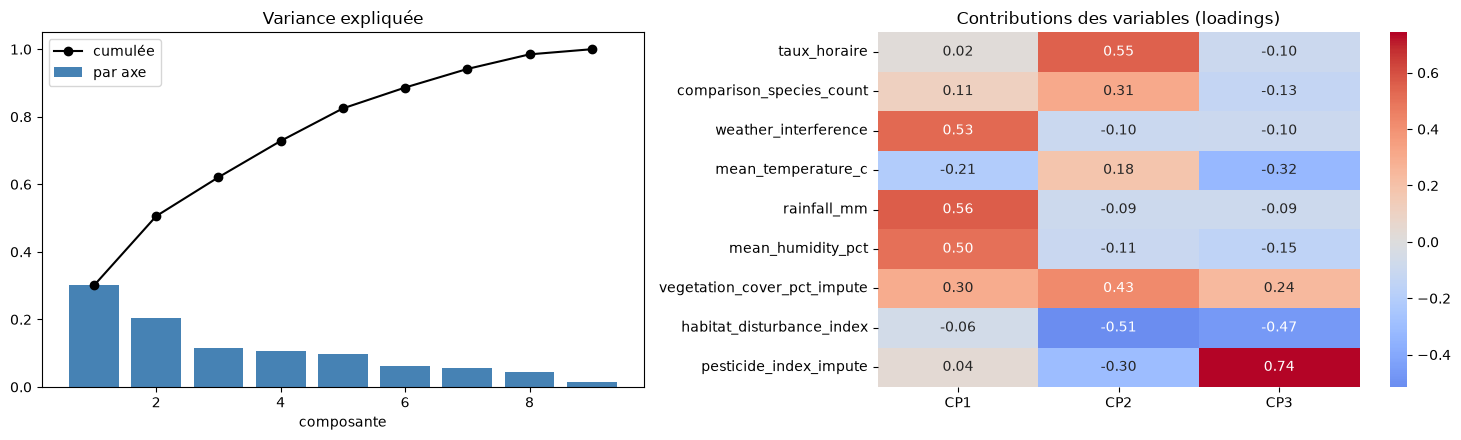

Variance expliquée (%) : [30.  20.5 11.5 10.7  9.6  6.2  5.5  4.3  1.5]


In [49]:
vars_mois = ["taux_horaire", "comparison_species_count", "weather_interference", "mean_temperature_c",
             "rainfall_mm", "mean_humidity_pct", "vegetation_cover_pct_impute", "habitat_disturbance_index",
             "pesticide_index_impute"]
X_mois = StandardScaler().fit_transform(eco[vars_mois])
acp = PCA().fit(X_mois)
coord_acp = acp.transform(X_mois)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
axes[0].bar(range(1, len(vars_mois) + 1), acp.explained_variance_ratio_, color="steelblue", label="par axe")
axes[0].plot(range(1, len(vars_mois) + 1), np.cumsum(acp.explained_variance_ratio_), "o-", color="black", label="cumulée")
axes[0].set_xlabel("composante")
axes[0].set_title("Variance expliquée")
axes[0].legend()
charges = pd.DataFrame(acp.components_[:3].T, index=vars_mois, columns=["CP1", "CP2", "CP3"])
sns.heatmap(charges, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=axes[1])
axes[1].set_title("Contributions des variables (loadings)")
plt.tight_layout()
plt.show()
print("Variance expliquée (%) :", (100 * acp.explained_variance_ratio_).round(1))

Nous dessinons les relevés sur les deux premiers axes de l'ACP, colorés par région puis par habitat.

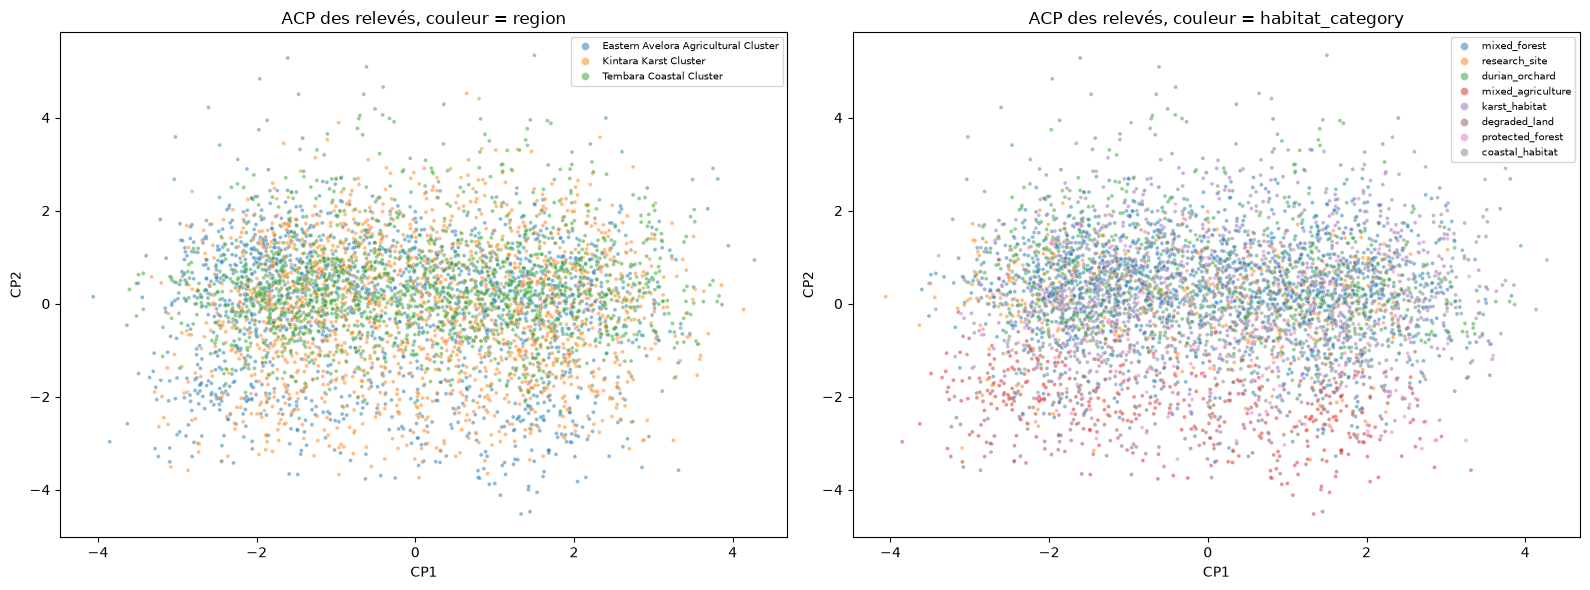

In [50]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, couleur in zip(axes, ["region", "habitat_category"]):
    sns.scatterplot(x=coord_acp[:, 0], y=coord_acp[:, 1], hue=eco[couleur], s=8, alpha=0.5, ax=ax)
    ax.set_xlabel("CP1")
    ax.set_ylabel("CP2")
    ax.set_title(f"ACP des relevés, couleur = {couleur}")
    ax.legend(fontsize=7, markerscale=2)
plt.tight_layout()
plt.show()

**Ce que montre l'ACP.** Les deux premiers axes résument 50 % de l'information, et il en faut 5 pour atteindre 83 %. Les 9 variables apportent donc des informations assez différentes : il était justifié de toutes les garder.

- **Axe 1 (30 %) : la météo.** Il regroupe la pluie, l'interférence météo et l'humidité. L'interférence météo est donc surtout un effet de la pluie.
- **Axe 2 (20 %) : la qualité écologique.** D'un côté le taux horaire, la végétation et les espèces de comparaison ; de l'autre, la perturbation et les pesticides. On retrouve, sans l'avoir cherchée, la relation « milieu perturbé, moins de chauves-souris ».
- **Axe 3** : surtout les pesticides.

Les trois régions se superposent complètement sur le graphique. Les relevés d'**agriculture mixte** (en rouge) sont en bas de l'axe 2 : ce sont les milieux les plus dégradés et les plus pauvres en chauves-souris.

**Classer les sites.** Appliquée aux profils de sites, l'ACP donne un premier axe (29 % de l'information) qui oppose les sites préservés (activité, espèces de comparaison, végétation) aux sites perturbés (perturbation, pesticides). Il permet de classer les 64 sites sur **une seule échelle** :

- en bas : AVL-GRB, KNT-GGN, AVL-FNQ, AVL-TRP, AVL-HUA, presque tous en agriculture mixte ou en milieu dégradé ;
- en haut : TMB-BRC, KNT-CHP, KNT-TLQ.

In [51]:
# Ordonner les sites sur une seule dimension : la 1re composante de l'ACP des profils
acp_sites = PCA(n_components=2).fit(X_std)
print("Variance expliquée par les 2 axes (profils de sites) :", (100 * acp_sites.explained_variance_ratio_).round(1))
print("Loadings de CP1 :", dict(zip(vars_profil, acp_sites.components_[0].round(2))))
score_cp1 = pd.Series(acp_sites.transform(X_std)[:, 0], index=X_std.index, name="score_CP1").sort_values()
pd.concat([score_cp1.head(5), score_cp1.tail(5)]).to_frame().join(profil_sites[["habitat_category", "region"]])

Variance expliquée par les 2 axes (profils de sites) : [29.3 16.9]
Loadings de CP1 : {'taux_horaire': np.float64(0.46), 'especes_comparaison': np.float64(0.5), 'amplitude_saisonniere': np.float64(0.3), 'temperature': np.float64(-0.02), 'pluie': np.float64(-0.13), 'humidite': np.float64(-0.1), 'vegetation': np.float64(0.45), 'perturbation': np.float64(-0.4), 'pesticide': np.float64(-0.23), 'elevation_m': np.float64(0.05)}


,score_CP1,habitat_category,region
site_code,,,
AVL-GRB,-4.472150,mixed_agriculture,Eastern Avelora Agricultural Cluster
KNT-GGN,-4.335277,degraded_land,Kintara Karst Cluster
AVL-FNQ,-2.952078,mixed_agriculture,Eastern Avelora Agricultural Cluster
AVL-TRP,-2.888488,mixed_agriculture,Eastern Avelora Agricultural Cluster
AVL-HUA,-2.876924,mixed_agriculture,Eastern Avelora Agricultural Cluster
TMB-NAC,2.232706,coastal_habitat,Tembara Coastal Cluster
KNT-CYP,2.420831,karst_habitat,Kintara Karst Cluster
KNT-TLQ,2.526254,mixed_forest,Kintara Karst Cluster
KNT-CHP,4.058902,karst_habitat,Kintara Karst Cluster


Le t-SNE dépend d'un réglage, la **perplexité**, qui fixe à peu près le nombre de voisins que chaque point « regarde ». Nous l'essayons avec trois valeurs : 5, 30 et 100.

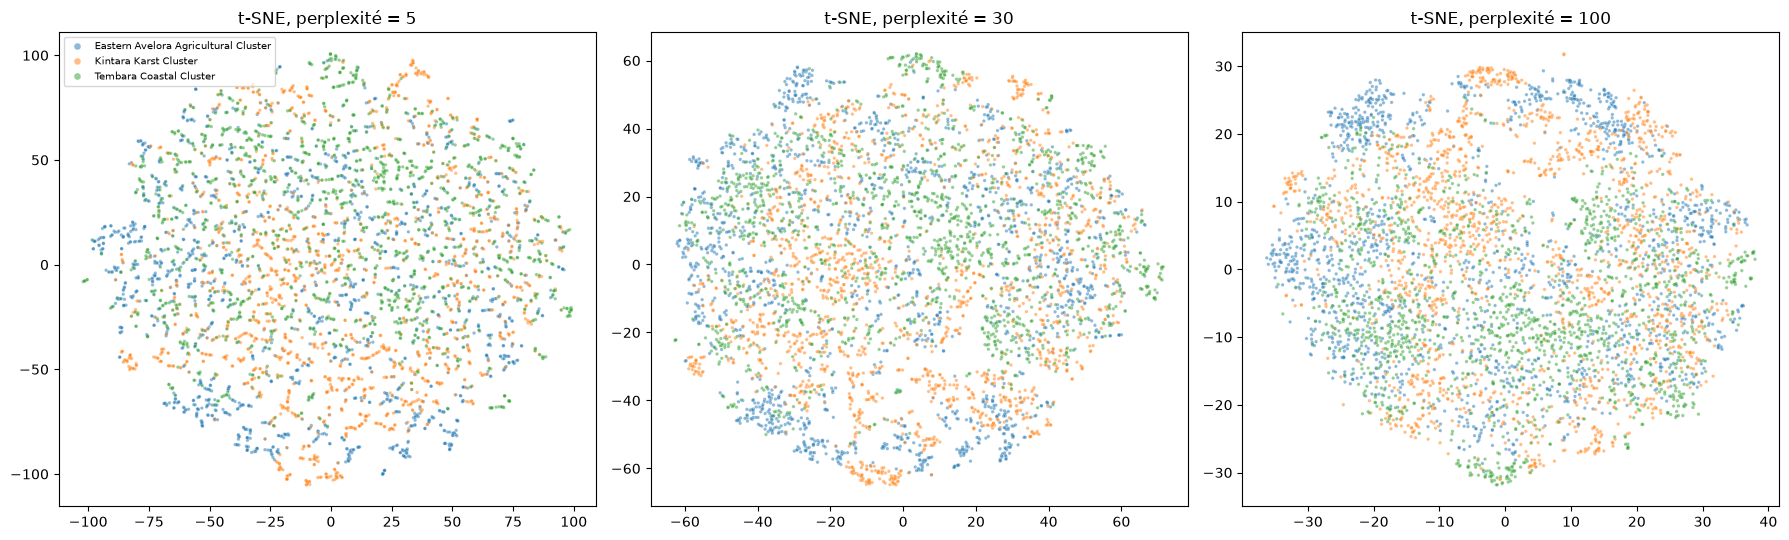

In [52]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
for ax, perplexite in zip(axes, [5, 30, 100]):
    emb = TSNE(n_components=2, perplexity=perplexite, init="pca", random_state=0).fit_transform(X_mois)
    sns.scatterplot(x=emb[:, 0], y=emb[:, 1], hue=eco["region"], s=6, alpha=0.5, ax=ax, legend=(perplexite == 5))
    ax.set_title(f"t-SNE, perplexité = {perplexite}")
axes[0].legend(fontsize=7, markerscale=2)
plt.tight_layout()
plt.show()

**Ce que montre le t-SNE.**

- Avec une perplexité de 5, on ne voit que de petits filaments, sans organisation d'ensemble.
- Avec 30 puis 100, de petits îlots d'une même couleur apparaissent : un site garde des conditions proches d'un mois à l'autre, donc ses relevés se regroupent.
- Aucune séparation en grands groupes n'apparaît.

Ni l'ACP ni le t-SNE ne font apparaître de **groupes naturels de relevés** : les données varient de façon continue. La structure la plus nette reste l'axe de qualité écologique. Cela nous oriente vers une analyse **site par site et dans le temps**, plutôt que vers un regroupement global.

## 5.4 Regrouper les sites : CAH, k-means et DBSCAN

Existe-t-il des familles de sites qui se ressemblent ? Nous testons les trois méthodes de regroupement du cours 2 sur les 64 profils de sites standardisés :

- la **CAH** (classification ascendante hiérarchique) fusionne pas à pas les sites les plus proches et donne un arbre, le **dendrogramme**. Nous utilisons le critère de **Ward**, qui fusionne à chaque étape les deux groupes dont la réunion reste la plus homogène ;
- le **k-means** répartit les sites en k groupes autour de k centres ;
- **DBSCAN** cherche des zones denses et laisse de côté les points isolés, appelés « bruit ».

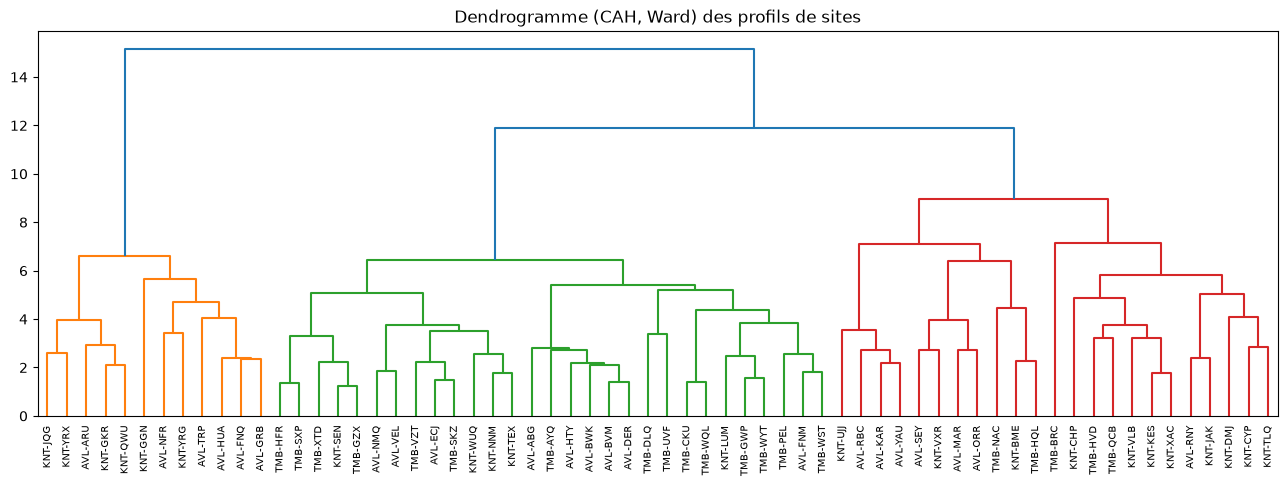

In [53]:
Z = linkage(X_std.values, method="ward")
fig, ax = plt.subplots(figsize=(16, 5))
dendrogram(Z, labels=X_std.index.tolist(), leaf_font_size=7, ax=ax)
ax.set_title("Dendrogramme (CAH, Ward) des profils de sites")
plt.show()

Pour choisir le nombre de groupes k, nous calculons la **silhouette** pour k allant de 2 à 10. Elle va de −1 à 1 : proche de 1, les groupes sont bien séparés ; proche de 0, ils se chevauchent.

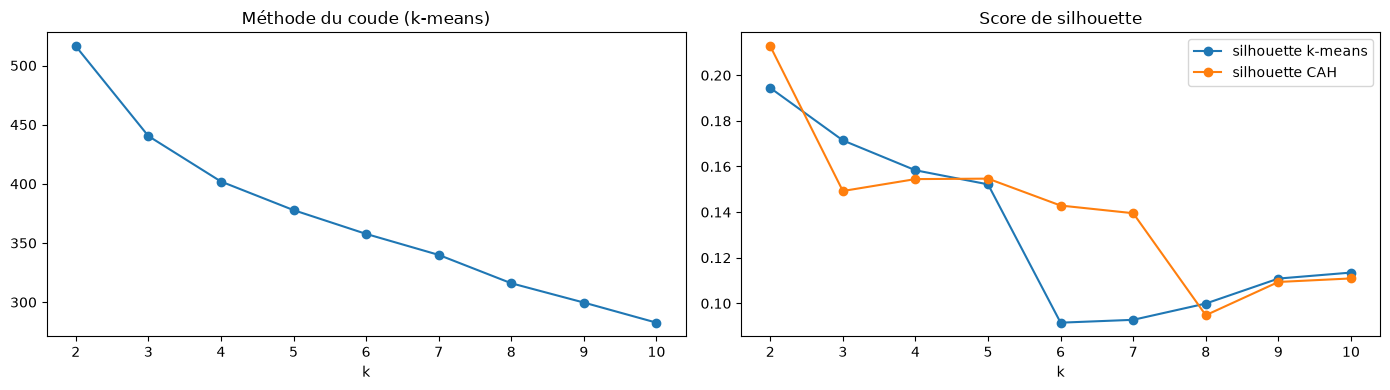

,inertie k-means,silhouette k-means,silhouette CAH
k,,,
2,516.349,0.194,0.213
3,440.408,0.171,0.149
4,401.961,0.158,0.154
5,377.797,0.152,0.155
6,357.681,0.092,0.143
7,339.943,0.093,0.140
8,315.975,0.100,0.095
9,299.658,0.111,0.109
10,282.668,0.113,0.111


In [54]:
resultats_k = []
for k in range(2, 11):
    km = KMeans(n_clusters=k, init="k-means++", n_init=20, random_state=0).fit(X_std)
    cah = fcluster(Z, k, criterion="maxclust")
    resultats_k.append({"k": k, "inertie k-means": km.inertia_,
                        "silhouette k-means": silhouette_score(X_std, km.labels_),
                        "silhouette CAH": silhouette_score(X_std, cah)})
resultats_k = pd.DataFrame(resultats_k).set_index("k")

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
resultats_k["inertie k-means"].plot(marker="o", ax=axes[0], title="Méthode du coude (k-means)")
resultats_k[["silhouette k-means", "silhouette CAH"]].plot(marker="o", ax=axes[1], title="Score de silhouette")
plt.tight_layout()
plt.show()
resultats_k.round(3)

Nous gardons le nombre de groupes qui donne la meilleure silhouette pour le k-means.

In [55]:
k_choisi = int(resultats_k["silhouette k-means"].idxmax())
print("k retenu (meilleure silhouette k-means) :", k_choisi)
profil_sites["cluster_kmeans"] = KMeans(n_clusters=k_choisi, init="k-means++", n_init=20,
                                        random_state=0).fit_predict(X_std)
profil_sites["cluster_cah"] = fcluster(Z, k_choisi, criterion="maxclust")

for col in ["habitat_category", "site_category", "region"]:
    print(f"ARI k-means vs {col} : {adjusted_rand_score(profil_sites[col], profil_sites['cluster_kmeans']):.2f}"
          f"   |   ARI CAH vs {col} : {adjusted_rand_score(profil_sites[col], profil_sites['cluster_cah']):.2f}")
display(pd.crosstab(profil_sites["habitat_category"], profil_sites["cluster_kmeans"]))
display(pd.crosstab(profil_sites["region"], profil_sites["cluster_kmeans"]))

k retenu (meilleure silhouette k-means) : 2
ARI k-means vs habitat_category : 0.06   |   ARI CAH vs habitat_category : 0.08
ARI k-means vs site_category : -0.02   |   ARI CAH vs site_category : 0.00
ARI k-means vs region : -0.00   |   ARI CAH vs region : 0.02


cluster_kmeans,0,1
habitat_category,,
coastal_habitat,7,3
degraded_land,0,2
durian_orchard,9,1
karst_habitat,8,1
mixed_agriculture,0,5
mixed_forest,16,3
protected_forest,2,1
research_site,5,1


cluster_kmeans,0,1
region,,
Eastern Avelora Agricultural Cluster,15,7
Kintara Karst Cluster,15,7
Tembara Coastal Cluster,17,3


Pour comprendre chaque groupe, nous affichons son profil moyen : en rouge, les variables au-dessus de la moyenne ; en bleu, celles en dessous.

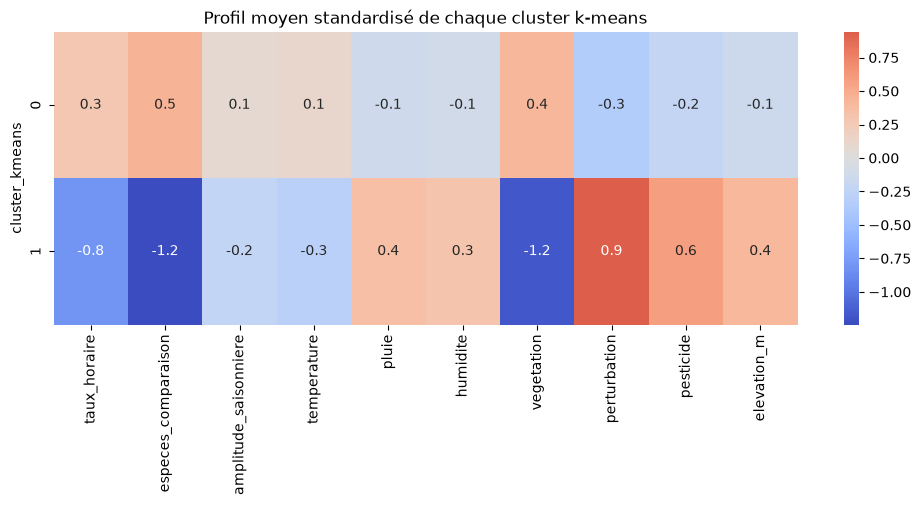

Taille des clusters : {0: 47, 1: 17}
Sites du plus petit cluster : ['AVL-ARU', 'AVL-FNQ', 'AVL-GRB', 'AVL-HUA', 'AVL-KAR', 'AVL-NFR', 'AVL-TRP', 'KNT-GGN', 'KNT-GKR', 'KNT-JQG', 'KNT-QWU', 'KNT-UJJ', 'KNT-YRG', 'KNT-YRX', 'TMB-DLQ', 'TMB-PEL', 'TMB-WST']


In [56]:
centres = X_std.groupby(profil_sites["cluster_kmeans"]).mean()
plt.figure(figsize=(12, 3 + 0.4 * k_choisi))
sns.heatmap(centres, annot=True, fmt=".1f", cmap="coolwarm", center=0)
plt.title("Profil moyen standardisé de chaque cluster k-means")
plt.show()
print("Taille des clusters :", profil_sites["cluster_kmeans"].value_counts().to_dict())
print("Sites du plus petit cluster :", profil_sites.index[profil_sites["cluster_kmeans"]
      == profil_sites["cluster_kmeans"].value_counts().idxmin()].tolist())

Pour DBSCAN, le réglage principal est **epsilon**, la distance en dessous de laquelle deux sites sont considérés comme voisins. Nous le choisissons à partir du graphique des distances au 4e voisin, comme le recommande le cours.

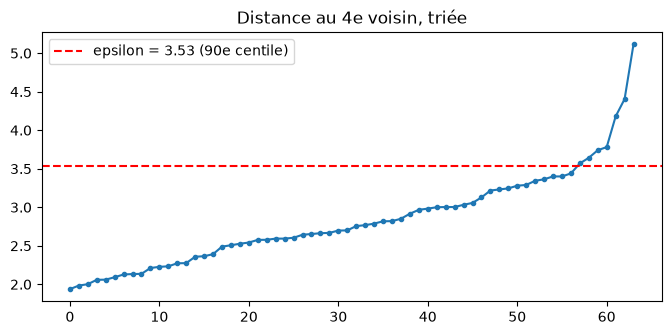

cluster_dbscan
0        62
bruit     2
Name: count, dtype: int64
Sites classés comme bruit : ['KNT-GGN', 'TMB-BRC']


In [57]:
# DBSCAN : epsilon choisi à partir du graphe des k-distances (k = min_samples = 4)
dist_k = np.sort(NearestNeighbors(n_neighbors=5).fit(X_std).kneighbors(X_std)[0][:, 4])
eps = float(np.quantile(dist_k, 0.90))

plt.figure(figsize=(8, 3.5))
plt.plot(dist_k, marker=".")
plt.axhline(eps, color="red", ls="--", label=f"epsilon = {eps:.2f} (90e centile)")
plt.title("Distance au 4e voisin, triée")
plt.legend()
plt.show()

profil_sites["cluster_dbscan"] = DBSCAN(eps=eps, min_samples=4).fit_predict(X_std)
print(profil_sites["cluster_dbscan"].value_counts().rename({-1: "bruit"}))
print("Sites classés comme bruit :", profil_sites.index[profil_sites["cluster_dbscan"] == -1].tolist())

Enfin, nous plaçons les sites sur le plan de l'ACP, colorés selon leur groupe k-means, avec les sites isolés par DBSCAN entourés en rouge.

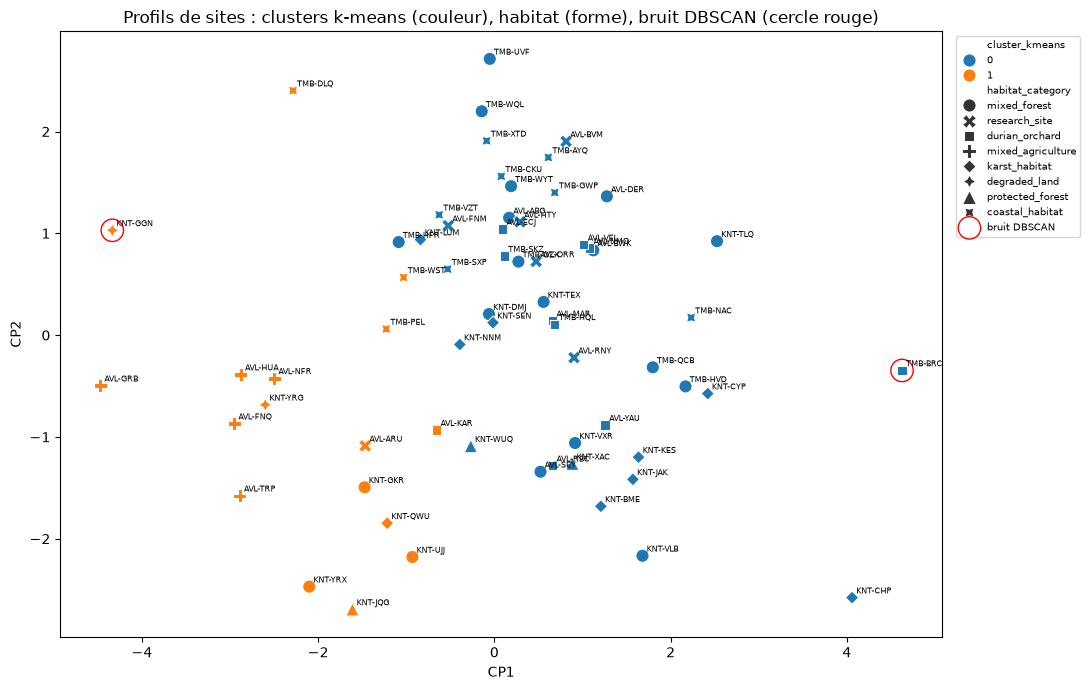

In [58]:
coord_sites = acp_sites.transform(X_std)
fig, ax = plt.subplots(figsize=(11, 7))
sns.scatterplot(x=coord_sites[:, 0], y=coord_sites[:, 1], hue=profil_sites["cluster_kmeans"].astype(str),
                style=profil_sites["habitat_category"], s=90, ax=ax)
bruit = profil_sites["cluster_dbscan"].values == -1
ax.scatter(coord_sites[bruit, 0], coord_sites[bruit, 1], s=260, facecolors="none", edgecolors="red",
           label="bruit DBSCAN")
for (x, y), nom in zip(coord_sites, profil_sites.index):
    ax.annotate(nom, (x, y), fontsize=6, xytext=(3, 3), textcoords="offset points")
ax.set_xlabel("CP1")
ax.set_ylabel("CP2")
ax.set_title("Profils de sites : clusters k-means (couleur), habitat (forme), bruit DBSCAN (cercle rouge)")
ax.legend(fontsize=7, bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.show()

**Résultats.**

- **Les groupes sont peu marqués.** La meilleure silhouette n'est que de 0,19 avec le k-means (pour k = 2), et de 0,21 avec la CAH. Le dendrogramme ne montre aucune coupure évidente : les sites varient de façon continue.
- **Le k-means sépare 47 sites « préservés » de 17 sites « dégradés ».** Les sites dégradés ont une activité plus basse, moins d'espèces de comparaison et moins de végétation, plus de perturbation et de pesticides. On y trouve les 5 sites d'agriculture mixte, les 2 sites dégradés et quelques sites d'autres habitats.
- **Ces groupes ne correspondent pas aux catégories officielles** : l'ARI vaut au plus 0,08 avec l'habitat, et environ 0 avec la région et le type de site. L'ARI mesure l'accord entre deux classements : 1 s'ils sont identiques, 0 s'ils ne s'accordent pas plus que le hasard. La catégorie déclarée d'un site dit donc très peu de chose de son état réel.
- **DBSCAN** met 62 sites dans un seul groupe et isole **2 sites** : KNT-GGN, le plus dégradé, et TMB-BRC, le plus actif. Ce sont les deux extrémités du classement de la partie 5.3.

Parmi les 8 sites qui seront au centre de la suite, 7 sont dans le groupe « préservé ». **En moyenne, ils n'ont rien d'anormal** : ce qui les distinguera, ce sont des épisodes ponctuels dans le temps.

# 6. Chercher des régularités et des anomalies (cours 3)

## 6.1 Les relevés vus comme des « paniers »

Les règles d'association (Apriori) viennent de l'analyse des paniers d'achat : quels produits sont souvent achetés ensemble ? Ici, chaque relevé (un site, un mois) devient un panier, et ses caractéristiques deviennent des « articles » présents ou absents. Les variables numériques sont découpées en trois tranches de même taille (les **tertiles** : basse, moyenne, haute) :

- l'**activité relative** est le taux horaire divisé par la médiane du site. Ainsi, un site naturellement pauvre en chauves-souris n'est pas toujours classé « bas » ;
- la perturbation, les pesticides, la pluie et l'interférence météo sont « hautes » dans leur tiers supérieur ; la végétation est « basse » dans son tiers inférieur ;
- les événements sont repris tels quels : exceptions météo, codes de panne, maintenance corrective, relevé de qualité limitée, uptime inférieur à 80 %, habitat.

In [59]:
eco["activite_relative"] = eco["taux_horaire"] / eco.groupby("site_code")["taux_horaire"].transform("median")

def tiers_haut(col):
    return eco[col] >= eco[col].quantile(2 / 3)

def tiers_bas(col):
    return eco[col] <= eco[col].quantile(1 / 3)

items = pd.DataFrame({
    "activite=basse": tiers_bas("activite_relative"),
    "activite=haute": tiers_haut("activite_relative"),
    "perturbation=haute": tiers_haut("habitat_disturbance_index"),
    "pesticide=haut": tiers_haut("pesticide_index_impute"),
    "vegetation=basse": tiers_bas("vegetation_cover_pct_impute"),
    "pluie=forte": tiers_haut("rainfall_mm"),
    "interference_meteo=haute": tiers_haut("weather_interference"),
    "maintenance=corrective": eco["maintenance_type"].eq("corrective maintenance"),
    "maintenance=remplacement_capteur": eco["maintenance_type"].eq("sensor replacement"),
    "releve=qualite_limitee": eco["survey_quality"].eq("limited"),
    "uptime<80": eco["uptime_pct"] < 80,
})
for code_ in eco["weather_exception_code"].dropna().unique():
    items[f"exception={code_}"] = eco["weather_exception_code"].eq(code_)
for code_ in eco["fault_code"].dropna().unique():
    items[f"panne={code_}"] = eco["fault_code"].eq(code_)
for h in eco["habitat_category"].unique():
    items[f"habitat={h}"] = eco["habitat_category"].eq(h)
items = items.fillna(False).astype(bool)
print(items.shape)
items.mean().sort_values(ascending=False).round(3).to_frame("support")

(4992, 24)


,support
pesticide=haut,0.335
perturbation=haute,0.334
vegetation=basse,0.334
interference_meteo=haute,0.334
pluie=forte,0.334
activite=haute,0.333
activite=basse,0.333
habitat=mixed_forest,0.297
habitat=coastal_habitat,0.156
habitat=durian_orchard,0.156


Première étape : la **matrice de co-occurrences**. Chaque case donne, parmi les relevés qui ont la caractéristique de la ligne, le pourcentage qui ont aussi celle de la colonne.

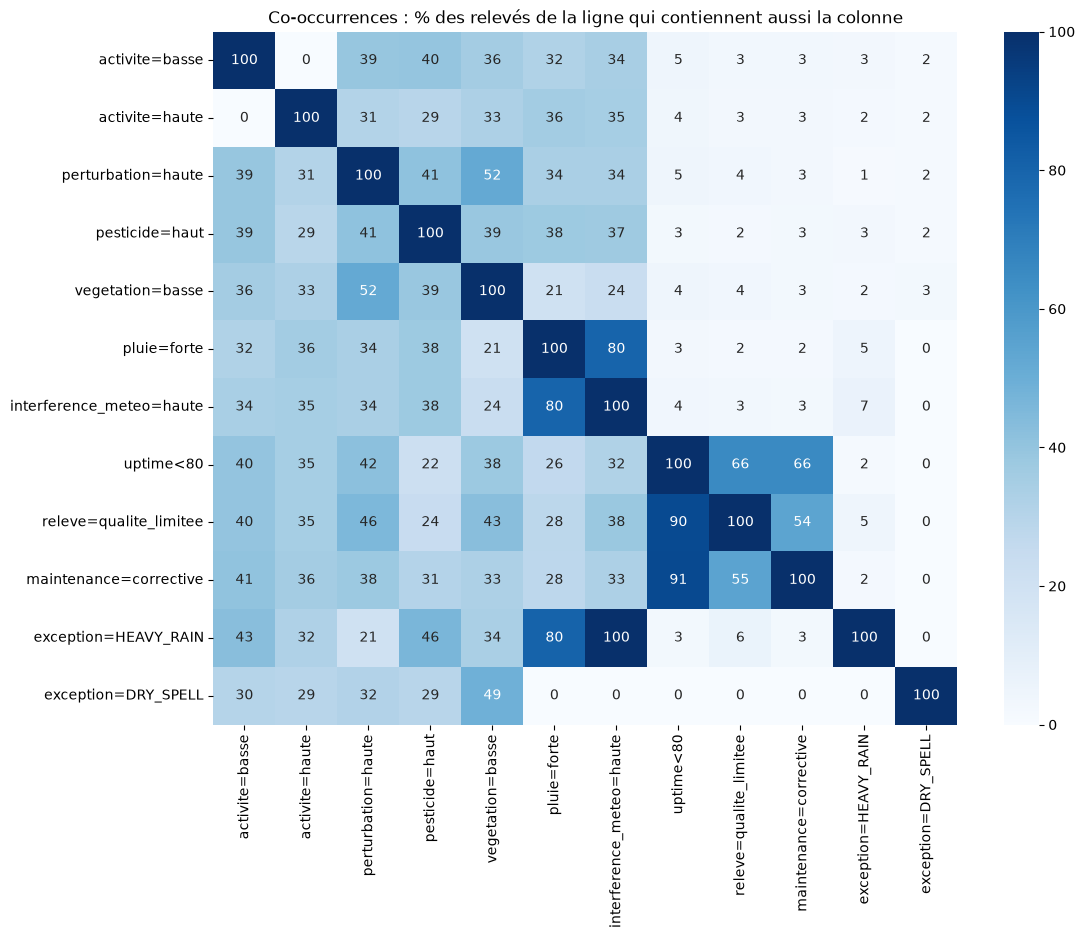

In [60]:
# Matrice de co-occurrences en pourcentage par ligne : P(colonne | ligne)
selection = ["activite=basse", "activite=haute", "perturbation=haute", "pesticide=haut", "vegetation=basse",
             "pluie=forte", "interference_meteo=haute", "uptime<80", "releve=qualite_limitee",
             "maintenance=corrective", "exception=HEAVY_RAIN", "exception=DRY_SPELL"]
B_items = items[selection].astype(int)
cooc = B_items.T @ B_items
cooc_pct = cooc.div(np.diag(cooc), axis=0)

plt.figure(figsize=(12, 9))
sns.heatmap(100 * cooc_pct, annot=True, fmt=".0f", cmap="Blues")
plt.title("Co-occurrences : % des relevés de la ligne qui contiennent aussi la colonne")
plt.show()

**Ce que montre la matrice.**

- **Des liens évidents** :
  - 80 % des mois très pluvieux ont aussi une forte interférence météo, et c'est le cas de 100 % des exceptions « forte pluie » ;
  - 91 % des maintenances correctives et 90 % des relevés de qualité limitée tombent un mois où l'appareil a fonctionné moins de 80 % du temps.

  Les variables d'appareil forment un bloc à part, sans lien avec l'écologie.
- **Activité basse** : on la trouve dans 39 % des relevés très perturbés et dans 39 % de ceux à pesticides élevés, contre 33 % en moyenne. Le lien existe, mais il est modéré.
- **Appareil en panne** : quand l'uptime est sous 80 %, l'activité est basse dans 40 % des cas. Une panne fait baisser le comptage *mesuré*, sans que les chauves-souris soient forcément moins nombreuses.

Limite : la matrice ne regarde que des paires. Pour des combinaisons de trois caractéristiques, il faut Apriori.

Apriori cherche les combinaisons fréquentes et en tire des **règles** de la forme « si A, alors B ». Trois mesures décrivent une règle :

- le **support** : la part des relevés où A et B sont présents ensemble ;
- la **confiance** : quand A est présent, la part des cas où B l'est aussi ;
- le **lift** : combien de fois plus souvent A et B vont ensemble que s'ils étaient indépendants (1 = aucun lien).

In [61]:
itemsets = apriori(items, min_support=0.01, use_colnames=True, max_len=3)
regles = association_rules(itemsets, num_itemsets=len(items), metric="lift", min_threshold=1.0)
print(len(itemsets), "itemsets fréquents,", len(regles), "règles de lift >= 1")
colonnes_regles = ["antecedents", "consequents", "support", "confidence", "lift", "leverage"]

vers_basse = regles[regles["consequents"] == frozenset({"activite=basse"})]
print("\nRègles qui mènent à une activité basse :")
display(vers_basse.sort_values("lift", ascending=False)[colonnes_regles].head(10).round(3))

269 itemsets fréquents, 716 règles de lift >= 1

Règles qui mènent à une activité basse :


,antecedents,consequents,support,confidence,lift,leverage
271,"frozenset({interference_meteo=haute, habitat=m...",frozenset({activite=basse}),0.016,0.488,1.463,0.005
135,"frozenset({perturbation=haute, pesticide=haut})",frozenset({activite=basse}),0.062,0.448,1.343,0.016
259,"frozenset({pluie=forte, habitat=mixed_agricult...",frozenset({activite=basse}),0.012,0.446,1.338,0.003
193,"frozenset({interference_meteo=haute, pesticide...",frozenset({activite=basse}),0.055,0.442,1.327,0.014
280,"frozenset({uptime<80, maintenance=corrective})",frozenset({activite=basse}),0.011,0.427,1.282,0.002
207,"frozenset({habitat=mixed_agriculture, pesticid...",frozenset({activite=basse}),0.025,0.426,1.277,0.005
224,"frozenset({interference_meteo=haute, vegetatio...",frozenset({activite=basse}),0.033,0.418,1.255,0.007
169,"frozenset({perturbation=haute, habitat=mixed_a...",frozenset({activite=basse}),0.029,0.416,1.248,0.006
152,"frozenset({perturbation=haute, interference_me...",frozenset({activite=basse}),0.047,0.414,1.242,0.009
198,"frozenset({habitat=mixed_forest, pesticide=haut})",frozenset({activite=basse}),0.019,0.413,1.239,0.004


Nous regardons les règles qui mènent à une activité haute, puis celles qui ont le plus fort lift.

In [62]:
vers_haute = regles[regles["consequents"] == frozenset({"activite=haute"})]
print("Règles qui mènent à une activité haute :")
display(vers_haute.sort_values("lift", ascending=False)[colonnes_regles].head(6).round(3))
print("Règles de plus fort lift, toutes conséquences confondues :")
display(regles.sort_values("lift", ascending=False)[colonnes_regles].head(8).round(3))

Règles qui mènent à une activité haute :


,antecedents,consequents,support,confidence,lift,leverage
366,"frozenset({habitat=coastal_habitat, pluie=forte})",frozenset({activite=haute}),0.024,0.415,1.244,0.005
386,"frozenset({habitat=coastal_habitat, interferen...",frozenset({activite=haute}),0.023,0.401,1.204,0.004
33,frozenset({habitat=degraded_land}),frozenset({activite=haute}),0.012,0.378,1.135,0.001
372,"frozenset({habitat=research_site, interference...",frozenset({activite=haute}),0.010,0.376,1.128,0.001
361,"frozenset({pluie=forte, habitat=karst_habitat})",frozenset({activite=haute}),0.017,0.375,1.125,0.002
342,"frozenset({habitat=degraded_land, vegetation=b...",frozenset({activite=haute}),0.012,0.374,1.123,0.001


Règles de plus fort lift, toutes conséquences confondues :


,antecedents,consequents,support,confidence,lift,leverage
698,"frozenset({panne=MICROPHONE_DRIFT, releve=qual...",frozenset({maintenance=remplacement_capteur}),0.01,0.654,62.769,0.01
703,frozenset({maintenance=remplacement_capteur}),"frozenset({panne=MICROPHONE_DRIFT, releve=qual...",0.01,0.981,62.769,0.01
709,frozenset({maintenance=remplacement_capteur}),"frozenset({uptime<80, panne=MICROPHONE_DRIFT})",0.01,1.000,53.677,0.01
704,"frozenset({uptime<80, panne=MICROPHONE_DRIFT})",frozenset({maintenance=remplacement_capteur}),0.01,0.559,53.677,0.01
122,frozenset({panne=MICROPHONE_DRIFT}),frozenset({maintenance=remplacement_capteur}),0.01,0.536,51.464,0.01
708,frozenset({panne=MICROPHONE_DRIFT}),"frozenset({uptime<80, maintenance=remplacement...",0.01,0.536,51.464,0.01
700,"frozenset({releve=qualite_limitee, maintenance...",frozenset({panne=MICROPHONE_DRIFT}),0.01,1.000,51.464,0.01
123,frozenset({maintenance=remplacement_capteur}),frozenset({panne=MICROPHONE_DRIFT}),0.01,1.000,51.464,0.01


**Résultats d'Apriori** (support minimal de 1 %, combinaisons de 3 éléments au plus) : 269 combinaisons fréquentes et 716 règles de lift supérieur ou égal à 1.

- **Les règles les plus fortes (lift d'environ 50 à 63) décrivent le fonctionnement des appareils**, par exemple « remplacement de capteur → panne de micro » (confiance de 1). Elles sont fortes mais **sans intérêt pour nous** : elles décrivent une procédure de maintenance, pas le milieu.
- **Les règles qui mènent à une activité basse ont un lift modeste** (1,24 à 1,46). La plus fréquente est **{perturbation haute, pesticides hauts} → activité basse** (lift 1,34) : quand les deux pressions se cumulent, une activité basse est 34 % plus probable que d'habitude. La règle {uptime < 80, maintenance corrective} → activité basse rappelle qu'une partie des comptages bas vient de la mesure.
- **Les règles qui mènent à une activité haute** combinent surtout les habitats côtiers ou karstiques et la pluie (lift ≤ 1,24).

**Conclusion.** L'environnement influence l'activité, mais aucune règle n'explique une forte chute : la confiance reste sous 50 %. Les chutes que nous cherchons ne sont pas des situations qui se répètent dans certaines conditions : ce sont des **événements ponctuels**. D'où la détection d'anomalies qui suit.

## 6.2 Repérer les valeurs anormales, une variable à la fois

Nous cherchons les comptages anormaux avec les trois méthodes du cours :

- la règle de l'**IQR** : une valeur est anormale si elle sort de l'intervalle [Q1 − 1,5 × IQR ; Q3 + 1,5 × IQR], où l'IQR est l'écart entre le premier et le troisième quartile ;
- le **z-score** : le nombre d'écarts-types entre la valeur et la moyenne (anormal au-delà de 3) ;
- le **z-score modifié** : la même idée avec la médiane et le **MAD** (l'écart médian à la médiane), moins sensibles aux valeurs extrêmes (anormal au-delà de 3,5).

Nous les appliquons d'abord à **tous les relevés ensemble**, puis **site par site**. Une anomalie, c'est ce qui ne correspond pas au comportement habituel ; pour un site, le comportement habituel, c'est son propre historique.

In [63]:
x = eco["observed_bat_count"]
q1, q3 = x.quantile([0.25, 0.75])
iqr = q3 - q1
z = (x - x.mean()) / x.std()
mad = (x - x.median()).abs().median()
z_mod = 0.6745 * (x - x.median()) / mad

global_ = pd.DataFrame({
    "IQR (hors [Q1-1,5IQR ; Q3+1,5IQR])": [(x < q1 - 1.5 * iqr).sum(), (x > q3 + 1.5 * iqr).sum()],
    "z-score (|z| > 3)": [(z < -3).sum(), (z > 3).sum()],
    "z-score modifié (|z| > 3,5)": [(z_mod < -3.5).sum(), (z_mod > 3.5).sum()],
}, index=["valeurs trop basses", "valeurs trop hautes"])
print(f"Bornes IQR : [{q1 - 1.5 * iqr:.1f} ; {q3 + 1.5 * iqr:.1f}]")
global_

Bornes IQR : [-7.0 ; 33.0]


,"IQR (hors [Q1-1,5IQR ; Q3+1,5IQR])",z-score (|z| > 3),"z-score modifié (|z| > 3,5)"
valeurs trop basses,0,0,0
valeurs trop hautes,128,68,68


Même calcul, mais site par site, et sur le logarithme des comptages pour réduire le poids des valeurs très hautes.

In [64]:
# Même calcul, mais site par site, sur le log des comptages (distribution asymétrique)
log_c = np.log1p(eco["observed_bat_count"])
med_site = log_c.groupby(eco["site_code"]).transform("median")
mad_site = (log_c - med_site).abs().groupby(eco["site_code"]).transform("median")
eco["z_mod_site"] = 0.6745 * (log_c - med_site) / mad_site

print("Relevés anormalement bas pour leur site (z modifié < -3,5) :", (eco["z_mod_site"] < -3.5).sum())
eco.nsmallest(12, "z_mod_site")[["site_code", "reporting_month", "observed_bat_count", "z_mod_site",
                                 "uptime_pct", "fault_code", "survey_quality"]].round(2)

Relevés anormalement bas pour leur site (z modifié < -3,5) : 30


,site_code,reporting_month,observed_bat_count,z_mod_site,uptime_pct,fault_code,survey_quality
1618,AVL-VEL,2023-11-01,2.0,-6.15,85.4,NaN,acceptable
4173,TMB-NAC,2022-04-01,2.0,-6.02,93.5,NaN,acceptable
2643,KNT-QWU,2024-10-01,0.0,-5.92,96.4,NaN,high
3018,KNT-VLB,2023-07-01,1.0,-5.82,96.5,NaN,acceptable
2695,KNT-SEN,2022-08-01,1.0,-5.75,80.8,NaN,acceptable
3309,KNT-YRG,2021-10-01,0.0,-5.22,93.7,NaN,acceptable
4172,TMB-NAC,2022-03-01,3.0,-5.06,94.1,NaN,acceptable
1571,AVL-VEL,2019-12-01,4.0,-4.53,95.8,NaN,high
1621,AVL-VEL,2024-02-01,4.0,-4.53,90.9,NaN,high
1370,AVL-RNY,2022-09-01,4.0,-4.19,94.7,NaN,acceptable


**Tous les relevés ensemble.** Les trois méthodes ne signalent **que des valeurs trop hautes** (128 avec l'IQR, 68 avec chaque z-score), et jamais de valeurs trop basses. La borne basse de l'IQR est même négative (−7). Quand on mélange des sites très différents, un mois à 0 ou 3 chauves-souris n'a rien d'exceptionnel.

**Site par site**, le z-score modifié fait apparaître **30 relevés anormalement bas pour leur site**. Aucun n'a de panne, et leur qualité est toujours bonne. On y trouve par exemple AVL-VEL (novembre 2023, février 2024), TMB-NAC (mars-avril 2022) et KNT-SEN (août 2022).

**Ce que nous en retenons** : il faut comparer chaque site à lui-même, sinon les chutes passent inaperçues. Il faudra aussi retirer la saison, car un mois bas peut n'être qu'un creux saisonnier normal : c'est l'objet de la partie 7.

## 6.3 Repérer les combinaisons anormales

Un relevé peut sembler normal variable par variable, mais être anormal par sa *combinaison* de valeurs. Nous appliquons les quatre méthodes multivariées du cours à 10 variables standardisées (activité relative au site, espèces de comparaison, uptime, qualité acoustique, interférence météo, perturbation, pesticides, végétation, pluie, température) :

- l'**Isolation Forest** coupe les données au hasard, encore et encore : un point anormal se retrouve isolé en très peu de coupures ;
- le **LOF** compare la densité autour d'un point à celle autour de ses voisins ;
- **DBSCAN** signale les points qui n'appartiennent à aucune zone dense ;
- **ABOD** regarde sous quels angles un point « voit » les autres : un point en bordure les voit tous dans la même direction.

L'Isolation Forest, le LOF et ABOD signalent chacun les 2 % de relevés les plus suspects. Pour DBSCAN, epsilon est fixé au 98e centile de la distance au 10e voisin. La version exacte d'ABOD est trop lente, car elle examine tous les triplets de points : nous programmons sa version rapide, limitée aux 10 plus proches voisins.

In [65]:
eco["log_activite_relative"] = np.log1p(eco["observed_bat_count"]) - med_site
vars_anomalie = ["log_activite_relative", "comparison_species_count", "uptime_pct", "acoustic_quality",
                 "weather_interference", "habitat_disturbance_index", "pesticide_index_impute",
                 "vegetation_cover_pct_impute", "rainfall_mm", "mean_temperature_c"]
X_anom = StandardScaler().fit_transform(eco[vars_anomalie])
part_suspecte = 0.02

eco["iforest"] = IsolationForest(contamination=part_suspecte, random_state=0).fit_predict(X_anom) == -1
lof = LocalOutlierFactor(n_neighbors=20, contamination=part_suspecte)
eco["lof"] = lof.fit_predict(X_anom) == -1
eco["score_lof"] = -lof.negative_outlier_factor_

dist_k_anom = np.sort(NearestNeighbors(n_neighbors=11).fit(X_anom).kneighbors(X_anom)[0][:, 10])
eco["dbscan_bruit"] = DBSCAN(eps=float(np.quantile(dist_k_anom, 0.98)), min_samples=10).fit_predict(X_anom) == -1


def fast_abod(X, k=10):
    """ABOD restreint aux k plus proches voisins : variance des angles (pondérés par les distances)
    sous lesquels un point voit ses voisins. Variance faible = point en périphérie = suspect."""
    voisins = NearestNeighbors(n_neighbors=k + 1).fit(X).kneighbors(X, return_distance=False)[:, 1:]
    haut = np.triu_indices(k, 1)
    scores = np.empty(len(X))
    for i in range(len(X)):
        V = X[voisins[i]] - X[i]
        normes2 = (V ** 2).sum(axis=1) + 1e-12
        scores[i] = ((V @ V.T) / np.outer(normes2, normes2))[haut].var()
    return scores


eco["score_abod"] = fast_abod(X_anom)
eco["abod"] = eco["score_abod"] <= eco["score_abod"].quantile(part_suspecte)

methodes = ["iforest", "lof", "dbscan_bruit", "abod"]
print(eco[methodes].sum())
recouvrement = pd.DataFrame([[(eco[a] & eco[b]).sum() / (eco[a] | eco[b]).sum() for b in methodes] for a in methodes],
                            index=methodes, columns=methodes)
print("\nIndice de Jaccard entre les ensembles de relevés signalés :")
recouvrement.round(2)

iforest         100
lof             100
dbscan_bruit     25
abod            100
dtype: int64

Indice de Jaccard entre les ensembles de relevés signalés :


,iforest,lof,dbscan_bruit,abod
iforest,1.00,0.14,0.21,0.31
lof,0.14,1.00,0.11,0.37
dbscan_bruit,0.21,0.11,1.00,0.24
abod,0.31,0.37,0.24,1.00


Nous comparons ensuite les relevés signalés par chaque méthode, et nous comptons combien correspondent à un problème de mesure (uptime inférieur à 80 %, panne ou relevé de qualité limitée).

In [66]:
# Une valeur aberrante n'est pas forcément une anomalie écologique : beaucoup peuvent venir de l'appareil
eco["probleme_mesure"] = (eco["uptime_pct"] < 80) | eco["fault_code"].notna() | eco["survey_quality"].eq("limited")
bilan = pd.DataFrame({m: [eco.loc[eco[m], "probleme_mesure"].mean(),
                          eco.loc[eco[m], "log_activite_relative"].mean()] for m in methodes},
                     index=["part avec un problème de mesure", "activité relative moyenne (log)"])
bilan["tous les relevés"] = [eco["probleme_mesure"].mean(), eco["log_activite_relative"].mean()]
display(bilan.round(2))

eco["nb_methodes"] = eco[methodes].sum(axis=1)
print("Relevés signalés par au moins 3 méthodes :")
eco[eco["nb_methodes"] >= 3].sort_values("log_activite_relative")[
    ["site_code", "reporting_month", "observed_bat_count", "log_activite_relative", "uptime_pct",
     "fault_code", "survey_quality", "nb_methodes"]].head(15).round(2)

,iforest,lof,dbscan_bruit,abod,tous les relevés
part avec un problème de mesure,0.77,0.34,0.92,0.57,0.04
activité relative moyenne (log),-0.62,-0.61,-0.91,-0.73,-0.04


Relevés signalés par au moins 3 méthodes :


,site_code,reporting_month,observed_bat_count,log_activite_relative,uptime_pct,fault_code,survey_quality,nb_methodes
3423,KNT-YRX,2024-10-01,0.0,-2.25,73.1,STORAGE_LIMIT,acceptable,4
605,AVL-FNQ,2023-12-01,0.0,-1.95,58.5,MICROPHONE_DRIFT,limited,4
697,AVL-GRB,2025-02-01,0.0,-1.95,94.9,NaN,high,4
693,AVL-GRB,2024-10-01,0.0,-1.95,91.7,NaN,high,3
968,AVL-MAR,2021-09-01,1.0,-1.95,85.3,NaN,limited,4
1827,KNT-CHP,2021-10-01,2.0,-1.79,41.7,MICROPHONE_DRIFT,limited,4
2332,KNT-JQG,2024-11-01,1.0,-1.61,78.7,NaN,acceptable,3
4172,TMB-NAC,2022-03-01,3.0,-1.50,94.1,NaN,acceptable,4
2081,KNT-GGN,2023-06-01,0.0,-1.39,99.0,NaN,high,3
2126,KNT-GKR,2020-09-01,1.0,-1.32,99.4,NaN,acceptable,3


**Résultats.**

- Les méthodes signalent des relevés assez différents. L'indice de Jaccard, qui mesure le recouvrement entre deux listes, va de 0,11 à 0,37 : chaque méthode a sa propre idée de ce qu'est un point « isolé ».
- **La plupart des relevés signalés sont des problèmes de mesure** : 92 % des points isolés par DBSCAN, 77 % des alertes de l'Isolation Forest et 57 % de celles d'ABOD, alors que ces problèmes ne concernent que 4 % des relevés. Une panne produit un relevé très atypique (uptime bas, mauvaise qualité acoustique, comptage bas), que les algorithmes repèrent facilement. Le LOF y est le moins sensible (34 %).

C'est la leçon du cours 3 : **une valeur aberrante n'est pas forcément une anomalie.** Les relevés signalés par au moins 3 méthodes sont surtout des pannes : KNT-YRX en octobre 2024, AVL-FNQ en décembre 2023, KNT-CHP en octobre 2021. Nous les écartons. Quelques-uns ont pourtant une mesure fiable et correspondent à de vraies chutes, par exemple TMB-NAC en mars 2022 (3 chauves-souris, avec un appareil en marche 94 % du temps).

# 7. Le temps et l'espace (cours 5)

## 7.1 Séparer la tendance, la saison et le reste

Une baisse peut n'être qu'un effet de **saison** : il y a moins de chauves-souris chaque année à la même période. Pour ne pas prendre un creux saisonnier pour une anomalie, nous **décomposons** la série en trois parties :

- la **tendance** : l'évolution de fond ;
- la **saisonnalité** : le motif qui se répète chaque année ;
- le **résidu** : ce qui reste.

Nous commençons par la moyenne de tous les sites, avec une période de 12 mois. Nous traçons aussi l'**autocorrélation** (ACF), qui indique si la série ressemble à elle-même décalée de 1, 2… 36 mois.

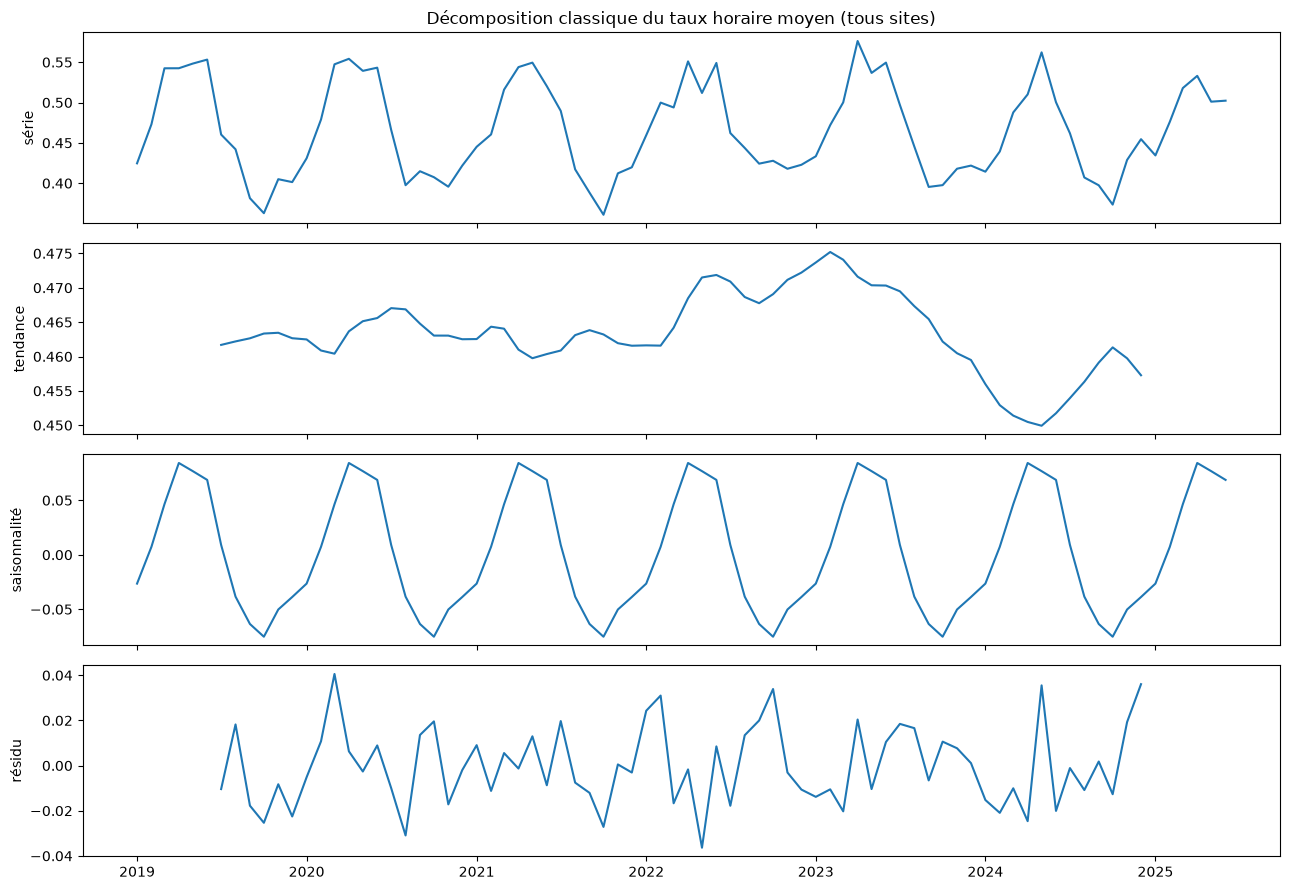

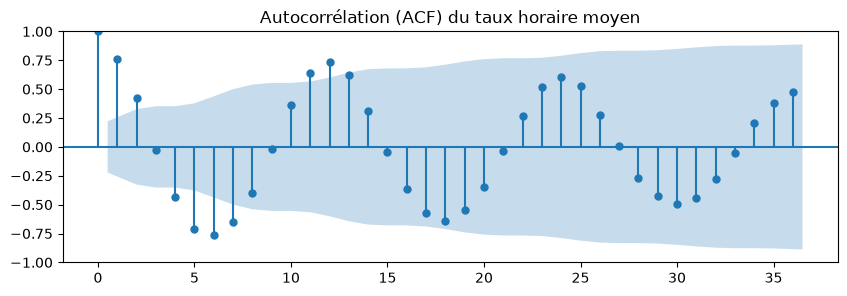

In [67]:
serie_globale = eco.groupby("reporting_month")["taux_horaire"].mean().asfreq("MS")
decomp = seasonal_decompose(serie_globale, model="additive", period=12)

fig, axes = plt.subplots(4, 1, figsize=(13, 9), sharex=True)
for ax, (nom, composante) in zip(axes, [("série", decomp.observed), ("tendance", decomp.trend),
                                       ("saisonnalité", decomp.seasonal), ("résidu", decomp.resid)]):
    ax.plot(composante)
    ax.set_ylabel(nom)
axes[0].set_title("Décomposition classique du taux horaire moyen (tous sites)")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(10, 3))
plot_acf(serie_globale, lags=36, ax=ax)
ax.set_title("Autocorrélation (ACF) du taux horaire moyen")
plt.show()

**Ce que montre la décomposition.**

- **Une saison très marquée** : l'activité est au plus haut de mars à juin (environ 0,55 chauve-souris par heure) et au plus bas en septembre-octobre (environ 0,37). L'ACF le confirme, avec des pics tous les 12 mois : le cycle est **annuel**.
- **Une tendance stable** jusqu'en 2023, puis une légère baisse en 2024, avant une remontée. La baisse est faible en moyenne parce qu'elle ne touche que peu de sites, mais elle tombe à la période de l'incident de KNT-KES.
- **Un résidu faible** (± 0,04).

Comparer septembre à avril reviendrait donc à prendre un creux saisonnier pour une anomalie. **Il faut retirer la saison avant de chercher des anomalies.**

Nous appliquons maintenant la **STL** à KNT-KES. C'est une décomposition plus souple que la précédente, et résistante aux valeurs extrêmes. Nous comparons ensuite chaque résidu à ceux des 13 mois qui l'entourent (une **fenêtre glissante**) : un mois est anormal si son z-score modifié, calculé sur cette fenêtre, est inférieur à −3,5.

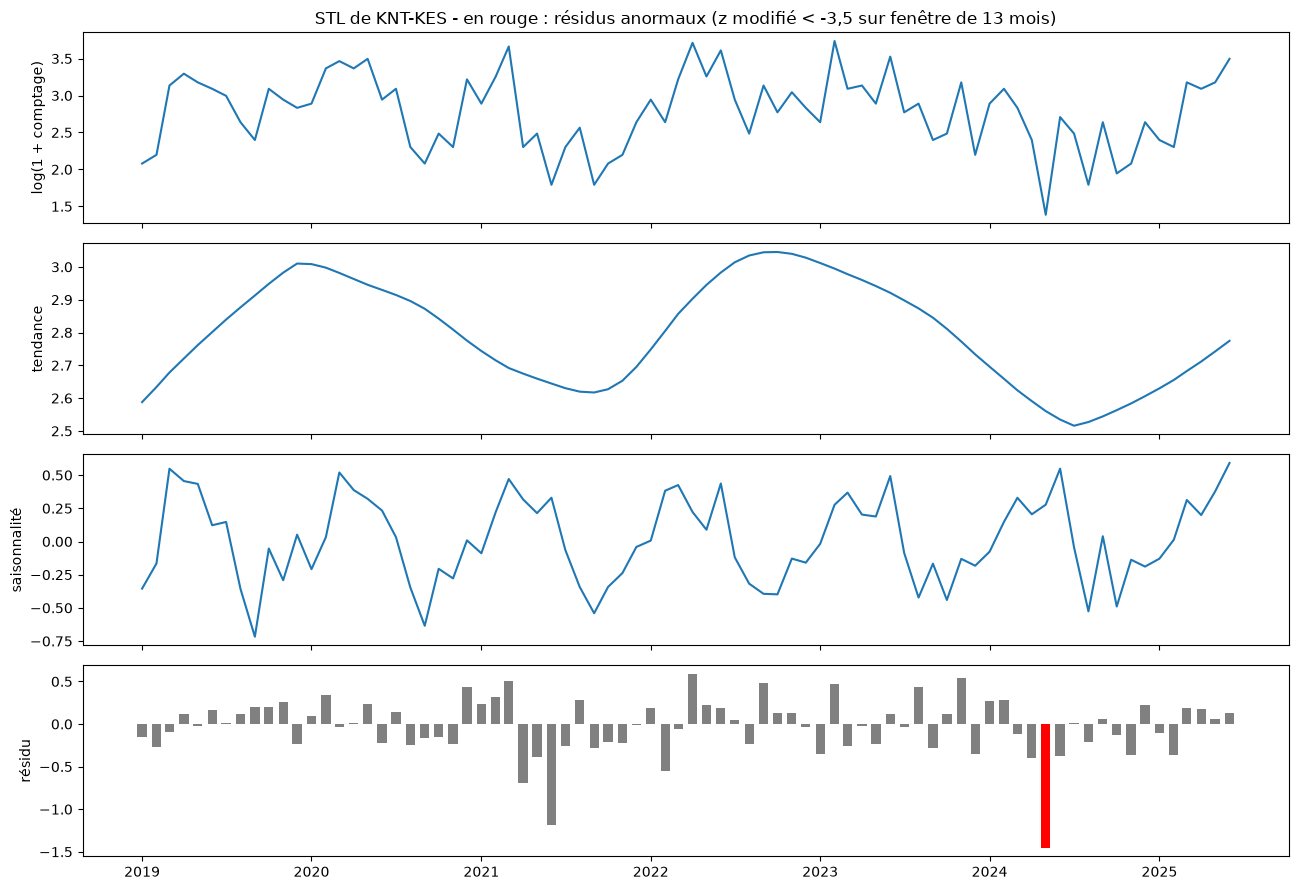

Mois anormaux à KNT-KES : {Timestamp('2024-05-01 00:00:00'): -3.7}


In [68]:
# STL (décomposition robuste par LOESS) appliquée à KNT-KES, sur le log des comptages
serie_kes_log = np.log1p(eco[eco["site_code"] == "KNT-KES"].set_index("reporting_month")["observed_bat_count"]).asfreq("MS")
stl_kes = STL(serie_kes_log, period=12, robust=True).fit()

# Fenêtre glissante (slide 20) : chaque résidu est comparé aux résidus de [t - 6 mois ; t + 6 mois]
fenetre = stl_kes.resid.rolling(13, center=True, min_periods=7)
med_f = fenetre.median()
mad_f = fenetre.apply(lambda w: np.median(np.abs(w - np.median(w))), raw=True)
z_fenetre = 0.6745 * (stl_kes.resid - med_f) / mad_f

fig, axes = plt.subplots(4, 1, figsize=(13, 9), sharex=True)
axes[0].plot(serie_kes_log)
axes[0].set_ylabel("log(1 + comptage)")
axes[1].plot(stl_kes.trend)
axes[1].set_ylabel("tendance")
axes[2].plot(stl_kes.seasonal)
axes[2].set_ylabel("saisonnalité")
axes[3].bar(stl_kes.resid.index, stl_kes.resid, width=20,
            color=np.where(z_fenetre < -3.5, "red", "grey"))
axes[3].set_ylabel("résidu")
axes[0].set_title("STL de KNT-KES - en rouge : résidus anormaux (z modifié < -3,5 sur fenêtre de 13 mois)")
plt.tight_layout()
plt.show()
print("Mois anormaux à KNT-KES :", z_fenetre[z_fenetre < -3.5].round(1).to_dict())

**Résultat pour KNT-KES.** Une fois la saison et la tendance retirées, la fenêtre glissante ne signale **qu'un seul mois sur 78 : mai 2024** (z = −3,7, avec 3 chauves-souris). La méthode retrouve donc, **sans savoir quoi chercher**, l'incident décrit dans le rapport de terrain d'avril 2024.

Le printemps 2021, repéré en partie 2, n'atteint pas ce seuil, car la baisse y est plus étalée dans le temps. Il ressort en revanche avec la méthode de la partie 7.2 (juin 2021, z = −3,4).

## 7.2 La même méthode sur les 64 sites

Nous appliquons la STL à chaque site et standardisons son résidu. Nous calculons aussi un indicateur plus simple à lire, l'**écart saisonnier** : le logarithme du comptage du mois, moins la valeur habituelle du **même site** pour le **même mois de l'année** (la médiane sur les sept années). Un écart de −0,7 veut dire environ deux fois moins de chauves-souris que d'habitude à cette période (e^−0,7 ≈ 0,5).

Mois signalés avec le z modifié (MAD) < -3,5 : 360 (7.2 %)
Mois signalés avec le z (écart-type) < -3   : 81 (1.6 %)


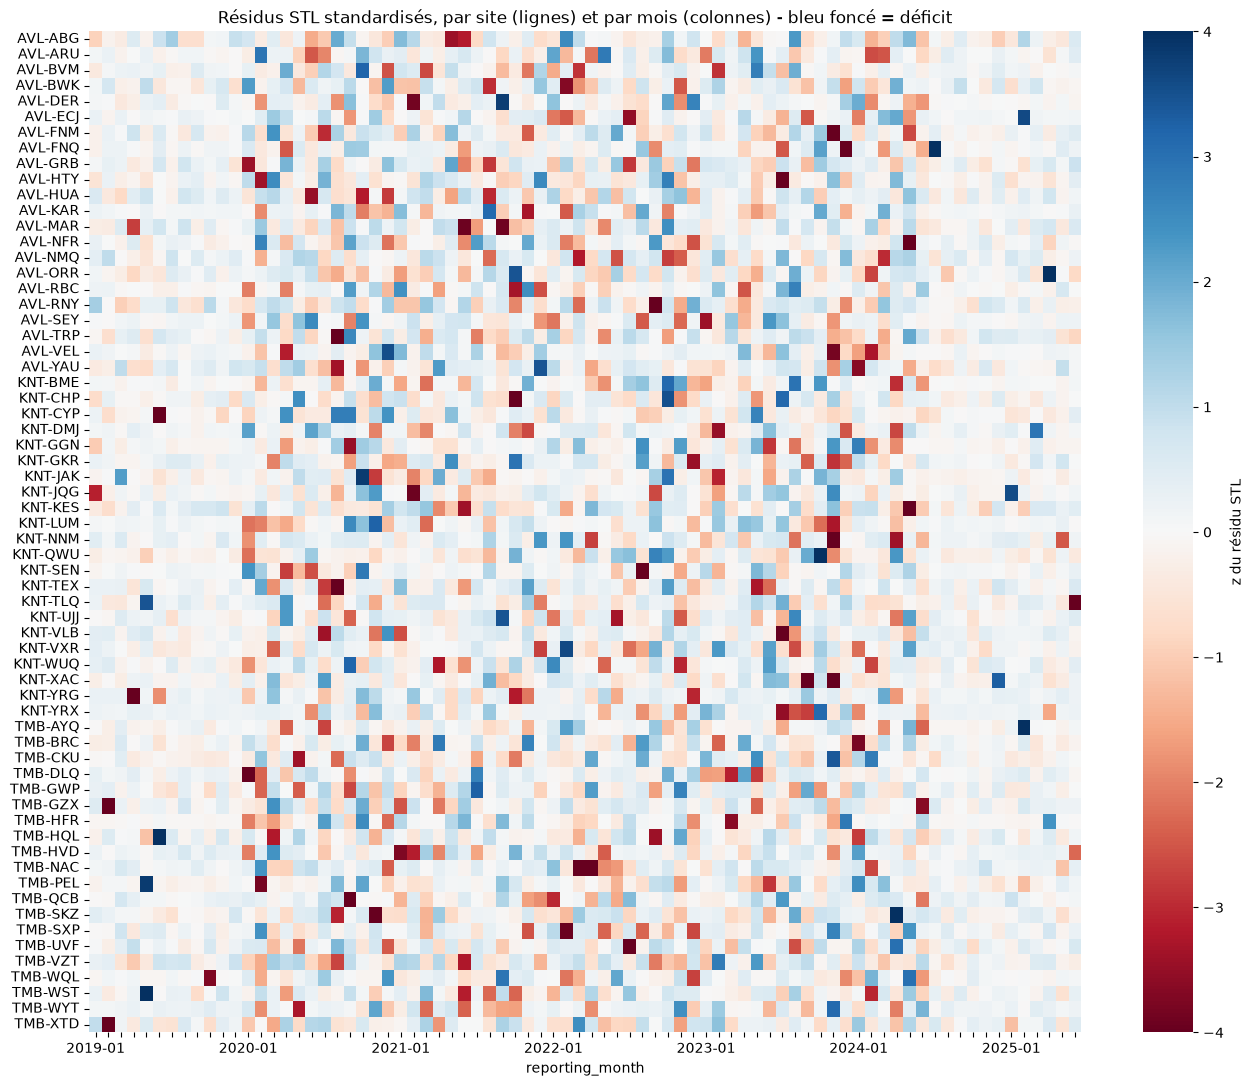

In [69]:
log_c = np.log1p(eco["observed_bat_count"])
eco["ecart_saisonnier"] = log_c - log_c.groupby([eco["site_code"], eco["mois_calendaire"]]).transform("median")

residus = []
for code_site, groupe in eco.groupby("site_code"):
    s = np.log1p(groupe.set_index("reporting_month")["observed_bat_count"]).asfreq("MS")
    residus.append(STL(s, period=12, robust=True).fit().resid.rename(code_site))
residus = pd.concat(residus, axis=1)

# Choix de la standardisation du résidu : la STL robuste ajuste très étroitement les mois « normaux »,
# si bien que le MAD des résidus est minuscule et que le z-score modifié signale beaucoup trop de mois.
z_mad = 0.6745 * (residus - residus.median()) / (residus - residus.median()).abs().median()
z_stl = (residus - residus.mean()) / residus.std()
n_mois = residus.size
print(f"Mois signalés avec le z modifié (MAD) < -3,5 : {(z_mad < -3.5).sum().sum()} ({100 * (z_mad < -3.5).sum().sum() / n_mois:.1f} %)")
print(f"Mois signalés avec le z (écart-type) < -3   : {(z_stl < -3).sum().sum()} ({100 * (z_stl < -3).sum().sum() / n_mois:.1f} %)")
eco = eco.merge(z_stl.stack().rename("z_stl").reset_index().rename(columns={"level_1": "site_code"}),
                on=["reporting_month", "site_code"], how="left")

fig, ax = plt.subplots(figsize=(16, 13))
sns.heatmap(z_stl.T.clip(-4, 4), cmap="RdBu", center=0, ax=ax, cbar_kws={"label": "z du résidu STL"},
            xticklabels=[d.strftime("%Y-%m") if d.month == 1 else "" for d in z_stl.index])
ax.set_title("Résidus STL standardisés, par site (lignes) et par mois (colonnes) - bleu foncé = déficit")
plt.show()

Nous gardons les mois dont le résidu standardisé est inférieur à −3, puis nous retirons ceux où la mesure était douteuse (uptime inférieur à 80 %, panne ou relevé de qualité limitée).

In [70]:
deficits = eco[eco["z_stl"] < -3].copy()
print("Mois en déficit (z STL < -3) :", len(deficits), "dont", deficits["probleme_mesure"].sum(),
      "avec un problème de mesure (uptime < 80, panne ou relevé limité)")
deficits_retenus = deficits[~deficits["probleme_mesure"]]
print("Déficits retenus (mesure fiable) :", len(deficits_retenus), "sur", deficits_retenus["site_code"].nunique(), "sites")
print("\nSites les plus touchés :")
print(deficits_retenus["site_code"].value_counts().head(10))
deficits_retenus.sort_values("z_stl")[["site_code", "reporting_month", "observed_bat_count", "z_stl",
                                       "ecart_saisonnier", "uptime_pct", "survey_quality"]].head(20).round(2)

Mois en déficit (z STL < -3) : 81 dont 9 avec un problème de mesure (uptime < 80, panne ou relevé limité)
Déficits retenus (mesure fiable) : 72 sur 49 sites

Sites les plus touchés :
site_code
AVL-HUA    3
AVL-VEL    3
KNT-YRG    3
AVL-ABG    2
AVL-YAU    2
KNT-JQG    2
KNT-KES    2
KNT-NNM    2
KNT-TEX    2
KNT-VLB    2
Name: count, dtype: int64


,site_code,reporting_month,observed_bat_count,z_stl,ecart_saisonnier,uptime_pct,survey_quality
3018,KNT-VLB,2023-07-01,1.0,-5.52,-2.08,96.5,acceptable
4310,TMB-QCB,2020-09-01,1.0,-5.46,-1.83,90.3,high
4915,TMB-XTD,2019-02-01,3.0,-5.16,-1.18,91.4,high
2885,KNT-TLQ,2025-06-01,12.0,-5.12,-0.65,88.9,high
2695,KNT-SEN,2022-08-01,1.0,-5.06,-1.79,80.8,acceptable
1877,KNT-CYP,2019-06-01,14.0,-5.02,-0.76,93.3,acceptable
4566,TMB-UVF,2022-07-01,1.0,-4.79,-1.70,92.2,acceptable
1501,AVL-TRP,2020-08-01,2.0,-4.70,-1.14,88.6,acceptable
1370,AVL-RNY,2022-09-01,4.0,-4.48,-0.90,94.7,acceptable
3279,KNT-YRG,2019-04-01,1.0,-4.37,-1.25,94.9,acceptable


**Résultats sur les 64 sites.**

- **Pourquoi l'écart-type et pas le MAD ?** La STL colle de très près aux mois ordinaires, si bien que le MAD des résidus est minuscule. Avec le z-score modifié, 7,2 % des mois seraient « anormaux », beaucoup trop. Nous standardisons donc par l'écart-type, avec un seuil de −3 : **81 mois en déficit, soit 1,6 %**.
- **9 de ces mois** ont un problème de mesure et sont écartés. Il reste **72 déficits fiables, répartis sur 49 sites**, et aucun site n'en a plus de 3.
- **Pas d'événement commun** : sur la carte de chaleur, les déficits forts sont dispersés. Aucun mois ne voit beaucoup de sites chuter en même temps. Ces déficits ne viennent donc pas d'un événement climatique général : ce sont des événements **locaux**.

KNT-KES y figure avec mai 2024 (z = −4,2) et juin 2021 (−3,4). Mais sur 4 992 relevés, une partie de ces 72 déficits n'est que du hasard. Pour savoir lesquels ont une cause, il faut une information **extérieure** aux comptages : c'est l'objet des parties 8 à 10.

**Regrouper les séries.** Les 64 séries couvrent les mêmes 78 mois. Nous standardisons chacune, pour comparer leur forme et non leur niveau, puis nous les regroupons avec un k-means.

Valeurs manquantes dans la matrice des séries : 0


Silhouette par k : {2: 0.088, 3: 0.032, 4: 0.024, 5: 0.02, 6: 0.031, 7: 0.019} -> k = 2


groupe_serie,0,1
region,,
Eastern Avelora Agricultural Cluster,16,6
Kintara Karst Cluster,21,1
Tembara Coastal Cluster,7,13


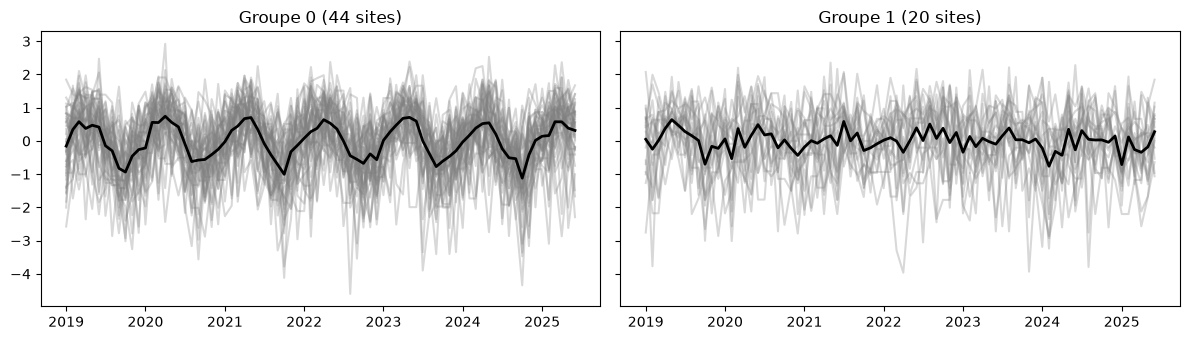

Profil saisonnier moyen (z) de chaque groupe, par mois calendaire :


reporting_month,1,2,3,4,5,6,7,8,9,10,11,12
groupe_serie,,,,,,,,,,,,
0,-0.03,0.30,0.48,0.60,0.56,0.38,-0.09,-0.45,-0.66,-0.82,-0.41,-0.25
1,-0.19,-0.17,-0.06,-0.11,0.16,0.16,0.25,0.22,0.03,-0.08,-0.12,-0.05


In [71]:
# Regrouper les séries temporelles : elles sont alignées (mêmes 78 mois pour chaque site),
# donc chaque série peut être traitée comme un vecteur (slide 18) ; le time warping (DTW) n'est pas nécessaire.
series = eco.pivot(index="site_code", columns="reporting_month", values="observed_bat_count")
series_z = np.log1p(series)
series_z = series_z.sub(series_z.mean(axis=1), axis=0).div(series_z.std(axis=1), axis=0)
print("Valeurs manquantes dans la matrice des séries :", int(series_z.isna().sum().sum()))

sil_series = {k: silhouette_score(series_z, KMeans(n_clusters=k, n_init=20, random_state=0).fit_predict(series_z))
              for k in range(2, 8)}
k_series = max(sil_series, key=sil_series.get)
print("Silhouette par k :", {k: round(v, 3) for k, v in sil_series.items()}, "-> k =", k_series)
groupes_series = pd.Series(KMeans(n_clusters=k_series, n_init=20, random_state=0).fit_predict(series_z),
                           index=series_z.index, name="groupe_serie")
display(pd.crosstab(profil_sites["region"], groupes_series))

fig, axes = plt.subplots(1, k_series, figsize=(6 * k_series, 3.5), sharey=True)
for g, ax in zip(range(k_series), np.atleast_1d(axes)):
    membres = series_z[groupes_series == g]
    ax.plot(membres.columns, membres.T.values, color="grey", alpha=0.3)
    ax.plot(membres.columns, membres.mean(), color="black", lw=2)
    ax.set_title(f"Groupe {g} ({len(membres)} sites)")
plt.tight_layout()
plt.show()

profil_moyen = series_z.T.groupby(series_z.columns.month).mean().T.groupby(groupes_series).mean()
print("Profil saisonnier moyen (z) de chaque groupe, par mois calendaire :")
profil_moyen.round(2)

**Résultat.** La silhouette est faible (0,09 pour k = 2), mais les deux groupes ont un sens :

- **Groupe 0** (44 sites : 21 de Kintara, 16 d'Avelora, 7 de Tembara) : il suit le cycle principal, avec un pic de mars à mai et un creux en septembre-octobre.
- **Groupe 1** (20 sites, dont 13 de Tembara) : son cycle est plus faible et **décalé**, avec un maximum en juillet-août.

La région côtière de Tembara a donc **sa propre saison**, que la moyenne de tous les sites cachait. C'est une raison de plus pour calculer l'écart saisonnier **site par site et mois par mois**, plutôt qu'avec un calendrier commun.

## 7.3 L'espace : carte, voisins et régions

Chaque site a des coordonnées (latitude, longitude). Pour mesurer la distance entre deux points sur la Terre, nous utilisons la distance de **Haversine**, qui tient compte de la courbure du globe. Une distance euclidienne sur les degrés serait fausse.

Distances entre centres des régions (km) :


region,Eastern Avelora Agricultural Cluster,Kintara Karst Cluster,Tembara Coastal Cluster
region,,,
Eastern Avelora Agricultural Cluster,0.0,1218.0,658.0
Kintara Karst Cluster,1218.0,0.0,933.0
Tembara Coastal Cluster,658.0,933.0,0.0


Distance médiane d'un site à son plus proche voisin (km) : 6.6


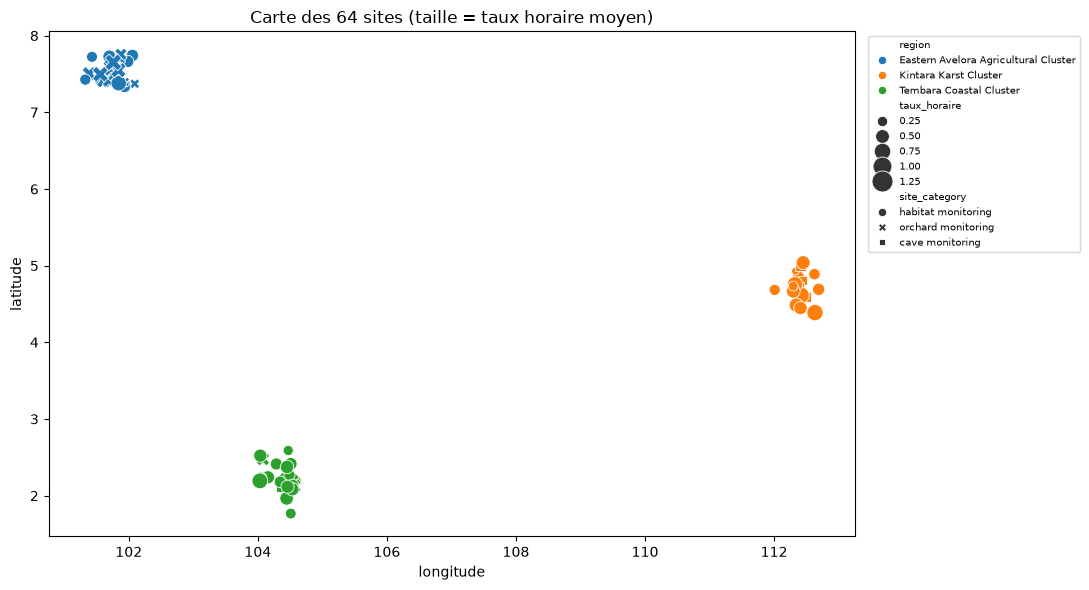

In [72]:
def haversine_km(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, (lat1, lon1, lat2, lon2))
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 2 * 6371 * np.arcsin(np.sqrt(a))

coords = profil_sites[["latitude", "longitude"]]
D_km = pd.DataFrame(haversine_km(coords["latitude"].values[:, None], coords["longitude"].values[:, None],
                                 coords["latitude"].values[None, :], coords["longitude"].values[None, :]),
                    index=coords.index, columns=coords.index)
centres_reg = profil_sites.groupby("region")[["latitude", "longitude"]].mean()
print("Distances entre centres des régions (km) :")
display(pd.DataFrame(haversine_km(centres_reg["latitude"].values[:, None], centres_reg["longitude"].values[:, None],
                                  centres_reg["latitude"].values[None, :], centres_reg["longitude"].values[None, :]),
                     index=centres_reg.index, columns=centres_reg.index).round(0))
print("Distance médiane d'un site à son plus proche voisin (km) :",
      round(float(np.median(np.sort(D_km.values, axis=1)[:, 1])), 1))

fig, ax = plt.subplots(figsize=(11, 6))
sns.scatterplot(data=profil_sites, x="longitude", y="latitude", hue="region", style="site_category",
                size="taux_horaire", sizes=(30, 250), ax=ax)
ax.set_title("Carte des 64 sites (taille = taux horaire moyen)")
ax.legend(fontsize=7, bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.show()

Nous cartographions l'**écart saisonnier moyen depuis avril 2024** de chaque site. Pour mieux voir les zones, nous ajoutons une **tessellation de Voronoï** : chaque site reçoit la zone des points dont il est le plus proche.

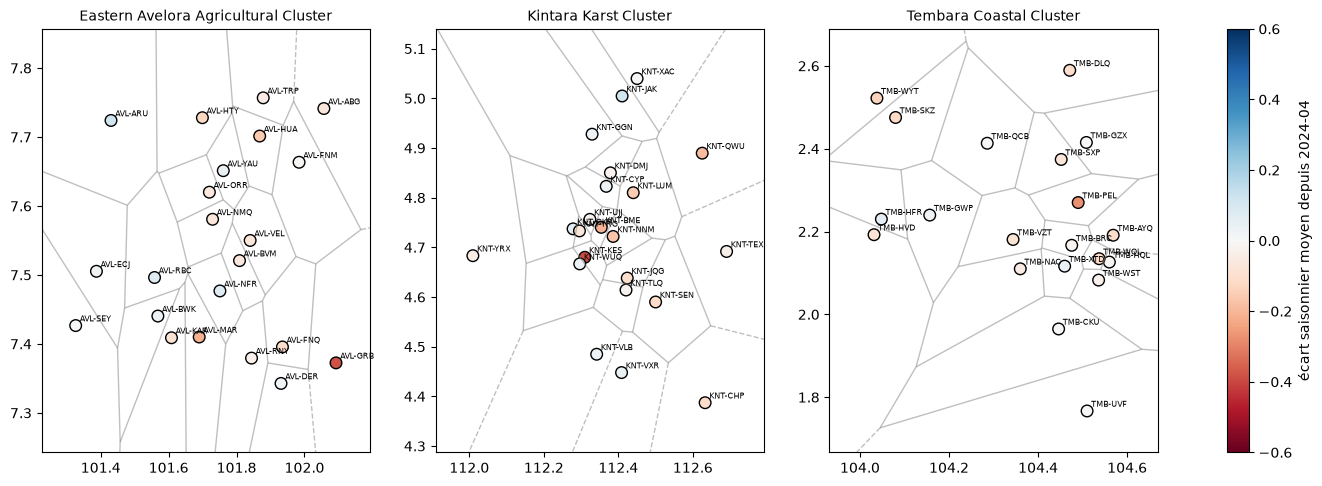

In [73]:
# Variable d'intérêt pour la suite : écart saisonnier moyen depuis avril 2024 (période qui suit l'incident documenté)
profil_sites["ecart_post_2024"] = eco[eco["reporting_month"] >= "2024-04-01"].groupby("site_code")["ecart_saisonnier"].mean()

# Tessellation de Voronoï par région (slide 8) : chaque site reçoit la zone des points dont il est le plus proche
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
norme = plt.Normalize(-0.6, 0.6)
for ax, (region, groupe) in zip(axes, profil_sites.groupby("region")):
    pts = groupe[["longitude", "latitude"]].values
    voronoi_plot_2d(Voronoi(pts), ax=ax, show_points=False, show_vertices=False, line_colors="grey", line_alpha=0.5)
    sc = ax.scatter(pts[:, 0], pts[:, 1], c=groupe["ecart_post_2024"], cmap="RdBu", norm=norme, s=70, edgecolors="black")
    for (lon, lat), nom in zip(pts, groupe.index):
        ax.annotate(nom, (lon, lat), fontsize=6, xytext=(3, 3), textcoords="offset points")
    ax.set_xlim(pts[:, 0].min() - 0.1, pts[:, 0].max() + 0.1)
    ax.set_ylim(pts[:, 1].min() - 0.1, pts[:, 1].max() + 0.1)
    ax.set_title(region, fontsize=10)
fig.colorbar(sc, ax=axes, label="écart saisonnier moyen depuis 2024-04")
plt.show()

Les sites proches se ressemblent-ils ? Pour le savoir, nous définissons les voisins de chaque site (ses 4 plus proches) et calculons l'**I de Moran** : il est positif si les voisins se ressemblent, et proche de 0 sinon. Pour savoir si le résultat est significatif, nous le comparons à 999 tirages où les valeurs sont mélangées au hasard entre les sites.

In [74]:
# Matrice de voisinage : les 4 plus proches voisins (Haversine), rendue symétrique
k_vois = 4
W = np.zeros(D_km.shape)
for i, ligne in enumerate(D_km.values):
    W[i, np.argsort(ligne)[1:k_vois + 1]] = 1
W = np.maximum(W, W.T)
print("Liens entre régions différentes :",
      int(sum(W[i, j] for i in range(len(W)) for j in range(len(W))
              if profil_sites["region"].iloc[i] != profil_sites["region"].iloc[j]) / 2))


def moran_I(y, W):
    zc = y - y.mean()
    return len(y) / W.sum() * (zc @ W @ zc) / (zc @ zc)


def moran_permutation(y, W, n=999, seed=0):
    rng = np.random.default_rng(seed)
    obs = moran_I(y, W)
    sims = np.array([moran_I(rng.permutation(y), W) for _ in range(n)])
    p = (1 + (sims >= obs).sum()) / (n + 1) if obs > sims.mean() else (1 + (sims <= obs).sum()) / (n + 1)
    return obs, p


lignes = []
for var in ["taux_horaire", "perturbation", "pesticide", "vegetation", "ecart_post_2024"]:
    y = profil_sites[var].values.astype(float)
    I_glob, p_glob = moran_permutation(y, W)
    I_intra = []
    for region in profil_sites["region"].unique():
        m = (profil_sites["region"] == region).values
        I_intra.append(moran_I(y[m], W[np.ix_(m, m)]))
    lignes.append({"variable": var, "I de Moran (64 sites)": I_glob, "p (permutations)": p_glob,
                   "I moyen intra-région": np.mean(I_intra)})
pd.DataFrame(lignes).set_index("variable").round(3)

Liens entre régions différentes : 0


,I de Moran (64 sites),p (permutations),I moyen intra-région
variable,,,
taux_horaire,-0.074,0.201,-0.086
perturbation,-0.071,0.238,-0.098
pesticide,0.100,0.059,0.008
vegetation,0.029,0.244,0.004
ecart_post_2024,0.046,0.167,0.032


L'I de Moran donne une réponse globale. Les indicateurs **LISA** donnent la même information site par site, pour repérer d'éventuels « points chauds » ou « points froids ».

In [75]:
def lisa(y, W, n=999, seed=0, seuil=0.05):
    """Indicateurs locaux d'association spatiale (I de Moran local) avec permutations conditionnelles."""
    rng = np.random.default_rng(seed)
    Wn = W / W.sum(axis=1, keepdims=True)
    zs = (y - y.mean()) / y.std()
    decalage = Wn @ zs
    I_local = zs * decalage
    p = np.empty(len(y))
    for i in range(len(y)):
        voisins_i = np.flatnonzero(W[i])
        autres = np.delete(zs, i)
        sims = zs[i] * np.array([rng.choice(autres, len(voisins_i), replace=False).mean() for _ in range(n)])
        p[i] = (1 + (np.abs(sims) >= abs(I_local[i])).sum()) / (n + 1)
    quadrant = np.select([(zs > 0) & (decalage > 0), (zs < 0) & (decalage < 0), (zs > 0) & (decalage < 0)],
                         ["HH (point chaud)", "LL (point froid)", "HL"], "LH")
    return pd.DataFrame({"z": zs, "decalage_spatial": decalage, "I_local": I_local, "p": p,
                         "quadrant": np.where(p < seuil, quadrant, "non significatif")})

lisa_post = lisa(profil_sites["ecart_post_2024"].values, W).set_index(profil_sites.index)
print(lisa_post["quadrant"].value_counts())
lisa_post[lisa_post["quadrant"] != "non significatif"].sort_values("z").round(3)

quadrant
non significatif    62
HH (point chaud)     1
LL (point froid)     1
Name: count, dtype: int64


,z,decalage_spatial,I_local,p,quadrant
site_code,,,,,
KNT-NNM,-1.18,-0.819,0.967,0.007,LL (point froid)
AVL-ECJ,0.78,1.112,0.867,0.032,HH (point chaud)


Enfin, la **régionalisation** regroupe des sites à la fois voisins et semblables : c'est une CAH de Ward où seuls des sites voisins peuvent être fusionnés.

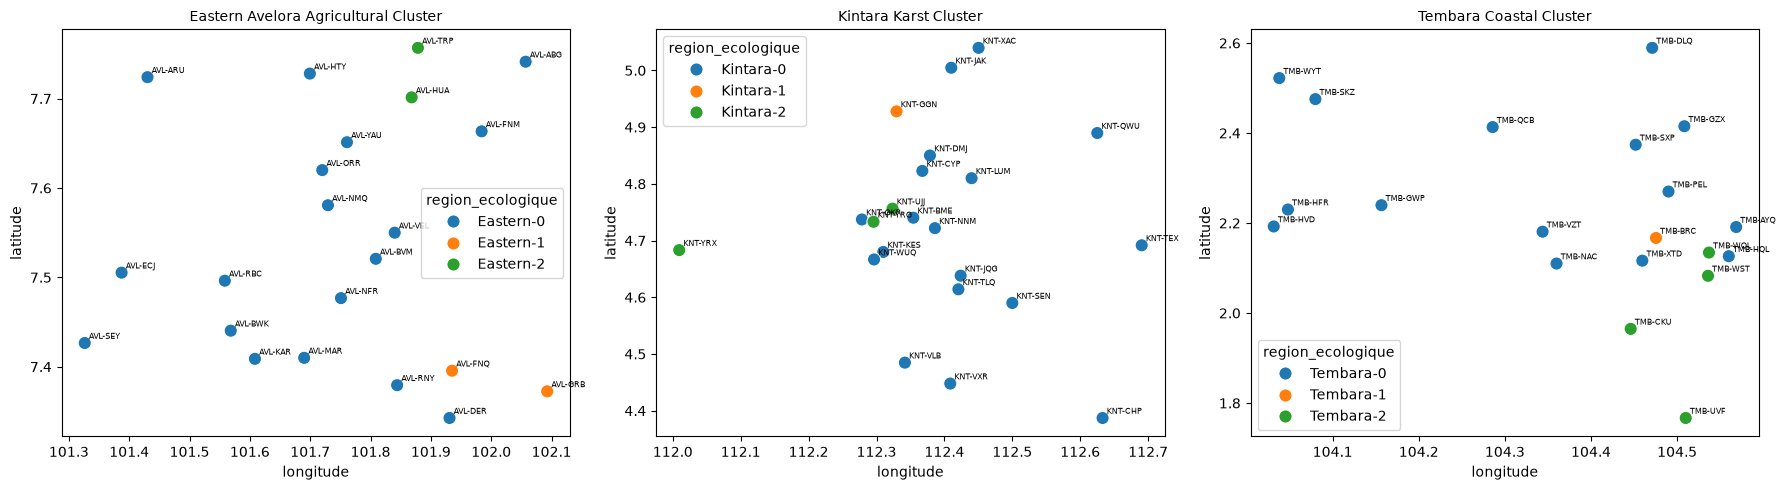

,taux_horaire,especes_comparaison,amplitude_saisonniere,temperature,pluie,humidite,vegetation,perturbation,pesticide,elevation_m
region_ecologique,,,,,,,,,,
Eastern-0,0.2,0.0,-0.1,0.3,-0.4,-0.5,0.2,-0.3,0.2,0.0
Eastern-1,-1.2,-2.3,-0.7,0.5,0.4,0.0,-1.7,1.6,1.7,0.9
Eastern-2,-0.6,-1.9,0.2,0.1,0.8,0.4,-1.9,1.6,0.5,0.2
Kintara-0,0.1,0.4,0.6,-0.9,-0.1,0.3,0.4,-0.1,-0.1,0.4
Kintara-1,-1.9,-1.8,-2.0,0.6,-0.9,1.2,-2.6,2.8,-1.5,0.4
Kintara-2,-0.4,-1.5,0.4,-1.2,0.8,0.2,-1.9,0.1,0.0,0.2
Tembara-0,-0.1,0.4,-0.4,0.4,0.6,0.4,0.5,-0.2,-0.0,-0.7
Tembara-1,4.7,1.3,2.1,1.3,-0.1,-1.8,0.8,-0.7,-1.3,0.8
Tembara-2,-0.3,-0.1,-0.7,1.5,-0.6,-0.7,-0.6,0.1,-1.2,-0.4


In [76]:
# Régionalisation (slide 7) : CAH de Ward contrainte par la contiguïté spatiale, région par région
profil_sites["region_ecologique"] = ""
for region, groupe in profil_sites.groupby("region"):
    m = (profil_sites["region"] == region).values
    contigu = AgglomerativeClustering(n_clusters=3, linkage="ward", connectivity=W[np.ix_(m, m)])
    labels = contigu.fit_predict(X_std.loc[groupe.index])
    profil_sites.loc[groupe.index, "region_ecologique"] = [f"{region.split()[0]}-{l}" for l in labels]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (region, groupe) in zip(axes, profil_sites.groupby("region")):
    sns.scatterplot(data=groupe, x="longitude", y="latitude", hue="region_ecologique", s=90, ax=ax)
    for nom, r in groupe.iterrows():
        ax.annotate(nom, (r["longitude"], r["latitude"]), fontsize=6, xytext=(3, 3), textcoords="offset points")
    ax.set_title(region, fontsize=10)
plt.tight_layout()
plt.show()
display(X_std.groupby(profil_sites["region_ecologique"]).mean().round(1))

**Résultats.**

- Les **trois régions sont éloignées de 650 à 1 200 km**, alors qu'un site n'est en médiane qu'à 6,6 km de son plus proche voisin. Les voisins d'un site sont donc toujours dans sa région.
- **Aucune variable n'est autocorrélée dans l'espace** (I de Moran, seuil de 5 %) :

  | Variable | I de Moran | p |
  |---|---|---|
  | taux horaire | −0,07 | 0,20 |
  | perturbation | −0,07 | 0,24 |
  | écart saisonnier depuis avril 2024 | 0,05 | 0,17 |
  | pesticides | 0,10 | 0,06 (à la limite) |

  Des sites voisins ne se ressemblent pas plus que des sites pris au hasard.
- **LISA** : seuls 2 sites sur 64 sont significatifs (KNT-NNM, point froid, et AVL-ECJ, point chaud). C'est ce que le hasard seul produit avec 64 tests (environ 3). **Il n'y a pas de zone de déclin.**
- **Régionalisation** : dans chaque région, elle isole une petite zone dégradée (moins de végétation, plus de perturbation) et, sur la côte de Tembara, une zone très active autour de TMB-BRC. Ce découpage en dit plus que les grandes régions administratives, qui mélangent ces milieux.

**Conclusion.** Le déclin observé depuis 2024 **n'est pas une tache sur la carte**. Une pollution ou une sécheresse régionale toucherait aussi les sites voisins. Ici, il frappe des sites précis et éloignés les uns des autres : la cause est sans doute **propre à ces sites**, c'est-à-dire liée à ce qui s'y passe.

# 8. Lire les rapports de terrain (cours 6)

`environmental_field_reports` contient 30 rapports : des informations sur le document (date, type, auteur, organisation, site) et un texte libre en anglais. Pour analyser ces textes, nous suivons la préparation du cours 6 : passage en minuscules, découpage en mots, suppression de la ponctuation et des chiffres, puis des mots vides (*the*, *and*, *of*…).

**Choix assumé** : nous ne ramenons pas les mots à leur forme de base (lemmatisation), et nous n'identifions pas leur nature grammaticale. Le corpus est court (30 textes) et écrit dans un anglais technique très répétitif : ces étapes n'auraient fusionné que quelques pluriels, sans changer les conclusions.

Encodage : caractères non ASCII présents : 0 textes
Longueur des textes (mots) : {'count': 30.0, 'mean': 171.0, 'std': 59.0, 'min': 100.0, '25%': 130.0, '50%': 161.0, '75%': 190.0, 'max': 288.0}


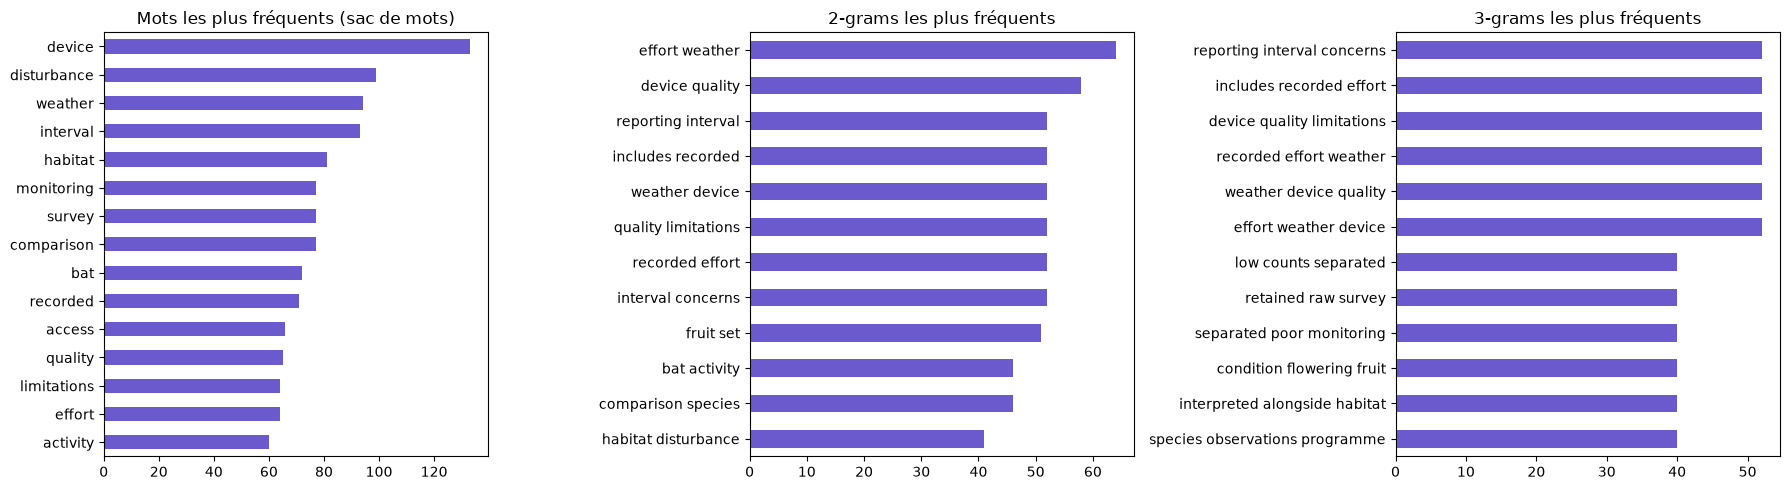

In [77]:
rapports = dataframes["environmental_field_reports"].sort_values("document_date").reset_index(drop=True)
print("Encodage : caractères non ASCII présents :", rapports["text"].str.contains(r"[^\x00-\x7F]").sum(), "textes")
print("Longueur des textes (mots) :", rapports["text"].str.split().str.len().describe().round(0).to_dict())


def pretraiter(texte):
    texte = texte.lower()
    texte = re.sub(r"[^a-z\s]", " ", texte)            # ponctuation, chiffres et codes retirés
    return [t for t in texte.split() if t not in ENGLISH_STOP_WORDS and len(t) > 2]

rapports["tokens"] = rapports["text"].apply(pretraiter)
frequences = Counter(t for tokens in rapports["tokens"] for t in tokens)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
pd.Series(dict(frequences.most_common(15))).sort_values().plot.barh(ax=axes[0], color="slateblue")
axes[0].set_title("Mots les plus fréquents (sac de mots)")
for ax, n in zip(axes[1:], [2, 3]):
    cv = CountVectorizer(ngram_range=(n, n), stop_words="english", token_pattern=r"(?u)\b[a-zA-Z]{3,}\b")
    comptes = pd.Series(np.asarray(cv.fit_transform(rapports["text"]).sum(axis=0)).ravel(),
                        index=cv.get_feature_names_out())
    comptes.sort_values().tail(12).plot.barh(ax=ax, color="slateblue")
    ax.set_title(f"{n}-grams les plus fréquents")
plt.tight_layout()
plt.show()

**Fréquences des mots.** Les mots les plus fréquents (*device, disturbance, weather, habitat, monitoring*…) et surtout les groupes de trois mots (*reporting interval concerns*, *device quality limitations*…, chacun 52 fois) viennent de phrases types répétées dans presque tous les rapports. Compter les mots ne montre donc que le **vocabulaire commun**. Pour trouver ce qu'un rapport a de **particulier**, il faut d'autres outils : la détection des phrases répétées et le TF-IDF.

**Repérer les phrases types.** Une phrase est considérée comme tirée d'un modèle si un **autre** rapport contient une phrase presque identique, avec au moins 60 % de mots en commun (indice de Jaccard ≥ 0,6). Pour chaque rapport, nous calculons la part de ses phrases tirées d'un modèle.

In [78]:
# Repérer le « gabarit » : une phrase est considérée comme un modèle si un AUTRE rapport contient une phrase
# quasi identique (indice de Jaccard >= 0,6 sur les mots : seuls les codes de site ou de relevé changent).
def phrases(texte):
    return [p.strip() for p in re.split(r"(?<=[.!?])\s+|\n+", texte) if len(p.strip()) > 25]

toutes_phrases = [(i, p, set(re.findall(r"[a-z]+", p.lower())))
                  for i, texte in enumerate(rapports["text"]) for p in phrases(texte)]


def similarite_max_ailleurs(i, mots):
    return max(len(mots & m2) / len(mots | m2) for j, _, m2 in toutes_phrases if j != i)


table_phrases = pd.DataFrame({"doc": [i for i, _, _ in toutes_phrases], "phrase": [p for _, p, _ in toutes_phrases],
                              "jaccard_max_autres": [similarite_max_ailleurs(i, m) for i, _, m in toutes_phrases]})
table_phrases["gabarit"] = table_phrases["jaccard_max_autres"] >= 0.6
rapports["part_gabarit"] = table_phrases.groupby("doc")["gabarit"].mean()
rapports["phrases_propres"] = table_phrases[~table_phrases["gabarit"]].groupby("doc")["phrase"].apply(list)

print("Phrases analysées :", len(table_phrases), "| part issue d'un gabarit :", round(table_phrases["gabarit"].mean(), 3))
rapports.sort_values("part_gabarit")[["document_id", "site_code", "document_date", "document_type",
                                      "author_organization", "part_gabarit"]].head(8).round(2)

Phrases analysées : 385 | part issue d'un gabarit : 0.912


,document_id,site_code,document_date,document_type,author_organization,part_gabarit
23,EFR-510088,KNT-KES,2024-04-02,ecological_incident_report,Horizon Field Research Cooperative,0.00
3,EFR-510082,KNT-JAK,2019-04-01,field_observation,Pollinator Justice Network,0.86
6,EFR-510122,KNT-QWU,2019-12-05,cave_access_note,Avelora Agricultural Resilience Agency,0.90
2,EFR-510011,KNT-DMJ,2018-09-11,cave_access_note,Pollinator Justice Network,0.90
15,EFR-510008,KNT-QWU,2022-05-12,cave_access_note,Threshold Earth Observatory,0.90
24,EFR-510109,KNT-GGN,2024-07-25,cave_access_note,Belen Agro-Industries,0.90
18,EFR-510032,KNT-DMJ,2023-04-04,cave_access_note,Threshold Earth Observatory,0.90
11,EFR-510098,KNT-GGN,2021-02-18,cave_access_note,Horizon Field Research Cooperative,0.90


Nous affichons, pour chaque rapport, les phrases qui ne viennent d'aucun modèle, en commençant par les rapports les plus originaux.

In [79]:
for _, r in rapports[rapports["phrases_propres"].notna()].sort_values("part_gabarit").iterrows():
    print(f"=== {r['document_id']} | {r['site_code']} | {r['document_date'].date()} | {r['document_type']} "
          f"| {r['author_organization']} | part de gabarit = {r['part_gabarit']:.2f}")
    for p in r["phrases_propres"]:
        print("   -", p)

=== EFR-510088 | KNT-KES | 2024-04-02 | ecological_incident_report | Horizon Field Research Cooperative | part de gabarit = 0.00
   - A post-access inspection was conducted at KNT-KES after the March access window.
   - The acoustic station remained operational, but the subsequent survey recorded a marked reduction in *Eonycteris spelaea* activity compared with other environmentally similar months.
   - Device uptime was above ninety percent and the acoustic-quality record did not show a sustained fault.
   - Weather interference was moderate and does not account for the full change.
   - Visual inspection identified fresh handling marks near the secondary entrance, two short lengths of cut restraint material, and disturbed sediment along a route not used by the monitoring team.
   - No dead animals were found.
   - The access register confirms authorized equipment entry, although the declared purpose was routine monitoring maintenance.
   - The entrance was photographed, the cut mater

**Des rapports écrits presque entièrement à partir de modèles.** 91 % des 385 phrases ont une quasi-copie dans un autre rapport. Les phrases propres à un rapport se limitent presque toujours au nom du site et à l'objet du mois. Trois rapports sortent du lot :

1. **EFR-510088 (KNT-KES, 2 avril 2024, Horizon Field Research Cooperative)** : 0 % de phrases types. C'est le **seul** texte entièrement original. Il décrit :
   - des **traces de manipulation** près d'une entrée secondaire ;
   - deux **morceaux de lien de contention coupés** ;
   - des **sédiments remués** sur un chemin que l'équipe de suivi n'emprunte pas ;
   - une baisse de l'activité d'*Eonycteris spelaea*, alors que l'appareil fonctionnait.

   Il précise que l'accès était autorisé « bien que l'objet déclaré ait été la maintenance de routine », et demande de **conserver le dossier d'accès**.
2. **EFR-510082 (KNT-JAK, 2019)** ajoute un paragraphe sur une **collecte autorisée de chauves-souris** pour les baguer, avant de les relâcher.
3. **EFR-510026 (KNT-CHP, 2021)** mentionne une collecte autorisée sur un site voisin.

Ailleurs, une même phrase revient dans 23 rapports : le rapport « ne transforme pas un comptage inhabituel en accusation de prélèvement organisé ».

**TF-IDF.** Le TF-IDF donne à chaque mot un poids élevé s'il est fréquent dans un rapport mais rare dans les autres : il fait ressortir le vocabulaire propre à chaque texte. Nous comparons ensuite les rapports deux à deux avec la **similarité cosinus**, qui vaut 1 pour deux textes identiques et 0 pour deux textes sans aucun mot en commun.

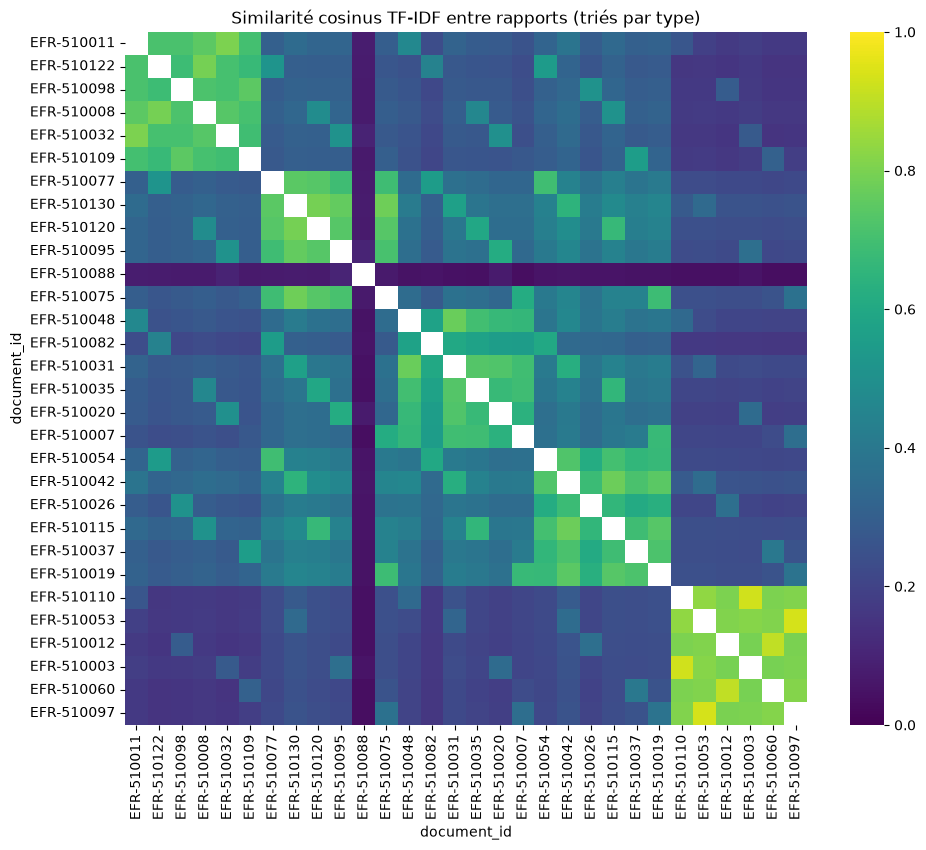

EFR-510088 - similarité moyenne aux autres : 0.06 | termes TF-IDF principaux : conducted, cut, post, material, post access, record, handling, access, inspection, station
EFR-510060 - similarité moyenne aux autres : 0.32 | termes TF-IDF principaux : device, review, vxr, knt vxr, dev kntvxr, kntvxr, kntvxr knt, vxr interval, cave microclimate, concerns cave
EFR-510012 - similarité moyenne aux autres : 0.32 | termes TF-IDF principaux : device, vxr, kntvxr knt, dev kntvxr, kntvxr, knt vxr, vxr interval, orchard pollination, survey includes, concerns orchard


In [80]:
tfidf = TfidfVectorizer(stop_words="english", token_pattern=r"(?u)\b[a-zA-Z]{3,}\b", ngram_range=(1, 2))
M_tfidf = tfidf.fit_transform(rapports["text"])
similarites = cosine_similarity(M_tfidf)
np.fill_diagonal(similarites, np.nan)
rapports["similarite_max"] = np.nanmax(similarites, axis=1)
rapports["similarite_moyenne"] = np.nanmean(similarites, axis=1)

ordre = rapports.sort_values(["document_type", "document_date"]).index
plt.figure(figsize=(11, 9))
sns.heatmap(pd.DataFrame(similarites, index=rapports["document_id"], columns=rapports["document_id"]).iloc[ordre, ordre],
            cmap="viridis", vmin=0, vmax=1)
plt.title("Similarité cosinus TF-IDF entre rapports (triés par type)")
plt.show()

vocab = tfidf.get_feature_names_out()
for doc in rapports.nsmallest(3, "similarite_moyenne")["document_id"]:
    i = rapports.index[rapports["document_id"] == doc][0]
    poids = M_tfidf[i].toarray().ravel()
    print(doc, "- similarité moyenne aux autres :", round(rapports.loc[i, "similarite_moyenne"], 2),
          "| termes TF-IDF principaux :", ", ".join(vocab[np.argsort(poids)[::-1][:10]]))

**Thèmes.** Deux méthodes cherchent les grands thèmes du corpus : la **LSA**, qui résume la matrice TF-IDF en quelques axes, et la **LDA**, qui décrit chaque texte comme un mélange de thèmes. Nous vérifions si un k-means sur ces thèmes retrouve les 5 types de documents.

In [81]:
# Modélisation thématique : LSA (SVD sur TF-IDF) et LDA (sur les comptages), 5 thèmes
lsa = TruncatedSVD(n_components=5, random_state=0)
docs_lsa = lsa.fit_transform(M_tfidf)
cv_lda = CountVectorizer(stop_words="english", token_pattern=r"(?u)\b[a-zA-Z]{3,}\b")
M_count = cv_lda.fit_transform(rapports["text"])
lda = LatentDirichletAllocation(n_components=5, random_state=0)
docs_lda = lda.fit_transform(M_count)

for nom, modele, termes in [("LSA", lsa, vocab), ("LDA", lda, cv_lda.get_feature_names_out())]:
    print(f"--- {nom}")
    for t, poids in enumerate(modele.components_):
        print(f"  thème {t} :", ", ".join(termes[np.argsort(poids)[::-1][:8]]))

rapports["theme_lsa"] = docs_lsa.argmax(axis=1)
rapports["theme_lda"] = docs_lda.argmax(axis=1)
rapports["cluster_texte"] = KMeans(n_clusters=5, n_init=20, random_state=0).fit_predict(docs_lsa)
for col in ["theme_lsa", "theme_lda", "cluster_texte"]:
    print(f"ARI {col} vs document_type : {adjusted_rand_score(rapports['document_type'], rapports[col]):.2f}")
pd.crosstab(rapports["document_type"], rapports["cluster_texte"])

--- LSA
  thème 0 : device, disturbance, interval, weather, habitat, monitoring, access, survey
  thème 1 : invalidate entire, monitoring month, invalidate, periods, period remediation, synchronization compare, fault lower, month brief
  thème 2 : visit, visit retain, checks, unauthorized equipment, unauthorized, continue, conditions entrance, close
  thème 3 : completed, team, wind intermittent, vegetation, dusk transect, varied, dusk, field
  thème 4 : temporary, evidence, incident, access path, path inspection, inspection, path, access noise
--- LDA
  thème 0 : incident, temporary, evidence, access, cycle, sensor, survey, reduction
  thème 1 : pollination, cycle, sensor, chp, site, access, seasonal, cave
  thème 2 : device, disturbance, interval, weather, habitat, comparison, survey, effort
  thème 3 : access, device, weather, disturbance, recorded, bat, interval, habitat
  thème 4 : device, quality, monitoring, interval, review, set, fruit, bat


ARI theme_lsa vs document_type : 0.24
ARI theme_lda vs document_type : 0.57
ARI cluster_texte vs document_type : 1.00


cluster_texte,0,1,2,3,4
document_type,,,,,
cave_access_note,0,6,0,0,0
ecological_incident_report,0,0,0,0,6
field_observation,6,0,0,0,0
monitoring_report,0,0,6,0,0
sensor_quality_report,0,0,0,6,0


Nous cherchons aussi directement les rapports qui parlent de prélèvement, de manipulation ou d'une espèce précise.

In [82]:
# Recherche ciblée de termes : qui parle de prélèvement, de manipulation ou d'espèce nommée ?
motifs = {"espèce nommée": r"\*[A-Z][a-z]+ [a-z]+\*", "removal": r"\bremoval\b", "handling": r"\bhandling\b",
          "restraint": r"\brestraint\b", "bat collection": r"bat collection", "access register": r"access register",
          "secondary entrance": r"secondary entrance"}
presences = pd.DataFrame({m: rapports["text"].str.contains(p, regex=True) for m, p in motifs.items()})
presences.index = rapports["document_id"]
print(presences.sum())
display(presences[presences.drop(columns="removal").any(axis=1)])
print("Mentions de « removal » : la phrase type est",
      repr(rapports.loc[rapports["text"].str.contains("removal"), "text"].str.extract(r"([^.\n]*removal[^.\n]*)")[0].iloc[0]))

espèce nommée          1
removal               24
handling               2
restraint              1
bat collection         2
access register        1
secondary entrance     1
dtype: int64


,espèce nommée,removal,handling,restraint,bat collection,access register,secondary entrance
document_id,,,,,,,
EFR-510082,False,True,False,False,True,False,False
EFR-510026,False,True,True,False,True,False,False
EFR-510088,True,True,True,True,False,True,True


Mentions de « removal » : la phrase type est 'The report does not convert an unusual count into a claim about organized removal'


Enfin, nous regardons qui signe les rapports : quelles organisations, et combien de rapports chacune.

In [83]:
# Métadonnées : qui écrit des rapports écologiques ?
display(pd.crosstab(rapports["author_organization"], rapports["document_type"], margins=True))

document_type,cave_access_note,ecological_incident_report,field_observation,monitoring_report,sensor_quality_report,All
author_organization,,,,,,
Asterion Clinical Institute,0,1,0,1,0,2
Avelora Agricultural Resilience Agency,1,1,1,1,1,5
Belen Agro-Industries,1,1,0,1,1,4
Bell Conservation Survey,0,0,1,0,0,1
Horizon Field Research Cooperative,1,2,1,1,1,6
Lantern Investigative Bureau,0,0,0,1,0,1
Marot Ecological Policy Office,0,0,1,0,0,1
Pollinator Justice Network,1,0,1,0,2,4
Threshold Earth Observatory,2,1,0,1,1,5


**TF-IDF et similarité.** Les rapports forment 5 blocs très homogènes, un par type de document. **EFR-510088 a une similarité moyenne de 0,06** avec les autres rapports, contre 0,32 pour le rapport le moins semblable après lui : c'est **l'anomalie du corpus**. Ses mots les plus caractéristiques sont *cut, post access, material, handling, inspection*.

**Thèmes.** Un k-means sur la LSA retrouve **exactement** les 5 types de documents (ARI = 1,00), et la LDA les retrouve en partie (0,57). Le contenu d'un rapport est donc entièrement dicté par son type, à une exception près.

**Qui écrit ?** 10 organisations signent des rapports, dont certaines inattendues pour un suivi de chauves-souris :

- l'**Asterion Clinical Institute**, un institut clinique (2 rapports) ;
- **Belen Agro-Industries** (4) ;
- le **Lantern Investigative Bureau** (1).

La Horizon Field Research Cooperative en signe 6, dont le seul rapport détaillé.

# 9. Graphes et processus (cours 4)

## 9.1 Qui observe quels sites ?

Une explication simple des chutes serait une **équipe d'observation** qui compte mal. Pour la tester, nous construisons un graphe **biparti** : d'un côté les équipes, de l'autre les sites, avec un lien entre une équipe et chaque site qu'elle a suivi. Nous le **projetons** ensuite sur les sites : deux sites sont reliés s'ils ont une équipe en commun.

In [84]:
equipes = (dataframes["bat_surveys"].dropna(subset=["observer_team"])
           .groupby(["observer_team", "site_code"]).size().reset_index(name="releves"))
G_eq = nx.Graph()
G_eq.add_nodes_from(equipes["observer_team"].unique(), bipartite="equipe")
G_eq.add_nodes_from(equipes["site_code"].unique(), bipartite="site")
G_eq.add_weighted_edges_from(equipes[["observer_team", "site_code", "releves"]].itertuples(index=False, name=None))
print(f"Graphe biparti : {G_eq.number_of_nodes()} nœuds, {G_eq.number_of_edges()} liens, densité = {nx.density(G_eq):.3f}")
deg_eq = pd.Series(dict(G_eq.degree(equipes["observer_team"].unique())), name="sites suivis").sort_values()
print("Degré des équipes (nombre de sites suivis) :", deg_eq.to_dict())

G_sites = bipartite.weighted_projected_graph(G_eq, equipes["site_code"].unique())
print(f"\nProjection sur les sites : {G_sites.number_of_nodes()} nœuds, {G_sites.number_of_edges()} liens, "
      f"densité = {nx.density(G_sites):.3f}, composantes connexes = {nx.number_connected_components(G_sites)}")
print("Coefficient de regroupement moyen :", round(nx.average_clustering(G_sites), 3))

communautes = nx.community.louvain_communities(G_sites, weight="weight", seed=0)
print("Louvain :", len(communautes), "communautés, modularité =",
      round(nx.community.modularity(G_sites, communautes, weight="weight"), 3))
communaute_site = {s: i for i, c in enumerate(communautes) for s in c}
display(pd.crosstab(profil_sites["region"], pd.Series(communaute_site, name="communauté Louvain")))

gn = next(nx.community.girvan_newman(G_sites))
print("Girvan-Newman, 1re division :", [len(c) for c in gn], "- modularité =",
      round(nx.community.modularity(G_sites, gn), 3))

Graphe biparti : 79 nœuds, 64 liens, densité = 0.021
Degré des équipes (nombre de sites suivis) : {'TEAM-11-1': 3, 'TEAM-11-5': 4, 'TEAM-12-3': 4, 'TEAM-13-3': 4, 'TEAM-13-2': 4, 'TEAM-13-1': 4, 'TEAM-12-5': 4, 'TEAM-12-4': 4, 'TEAM-13-5': 4, 'TEAM-13-4': 4, 'TEAM-12-2': 5, 'TEAM-11-4': 5, 'TEAM-11-2': 5, 'TEAM-12-1': 5, 'TEAM-11-3': 5}

Projection sur les sites : 64 nœuds, 107 liens, densité = 0.053, composantes connexes = 15
Coefficient de regroupement moyen : 1.0
Louvain : 15 communautés, modularité = 0.927


communauté Louvain,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14
region,,,,,,,,,,,,,,,
Eastern Avelora Agricultural Cluster,0,0,0,0,0,5,5,4,4,4,0,0,0,0,0
Kintara Karst Cluster,3,5,5,5,4,0,0,0,0,0,0,0,0,0,0
Tembara Coastal Cluster,0,0,0,0,0,0,0,0,0,0,4,4,4,4,4


Girvan-Newman, 1re division : [1, 2, 5, 5, 5, 4, 5, 5, 4, 4, 4, 4, 4, 4, 4, 4] - modularité = 0.909


Nous regardons en particulier les équipes des 8 sites qui reviendront dans la suite (dont KNT-KES, KNT-LUM et KNT-SEN), puis nous dessinons le graphe.

Équipes intervenues sur les 8 sites historiques du programme :
site_code
KNT-KES    [TEAM-11-2]
KNT-LUM    [TEAM-11-3]
KNT-SEN    [TEAM-11-4]
AVL-MAR    [TEAM-12-5]
AVL-VEL    [TEAM-12-1]
AVL-ORR    [TEAM-12-2]
TMB-NAC    [TEAM-13-3]
TMB-PEL    [TEAM-13-4]
Name: observer_team, dtype: object


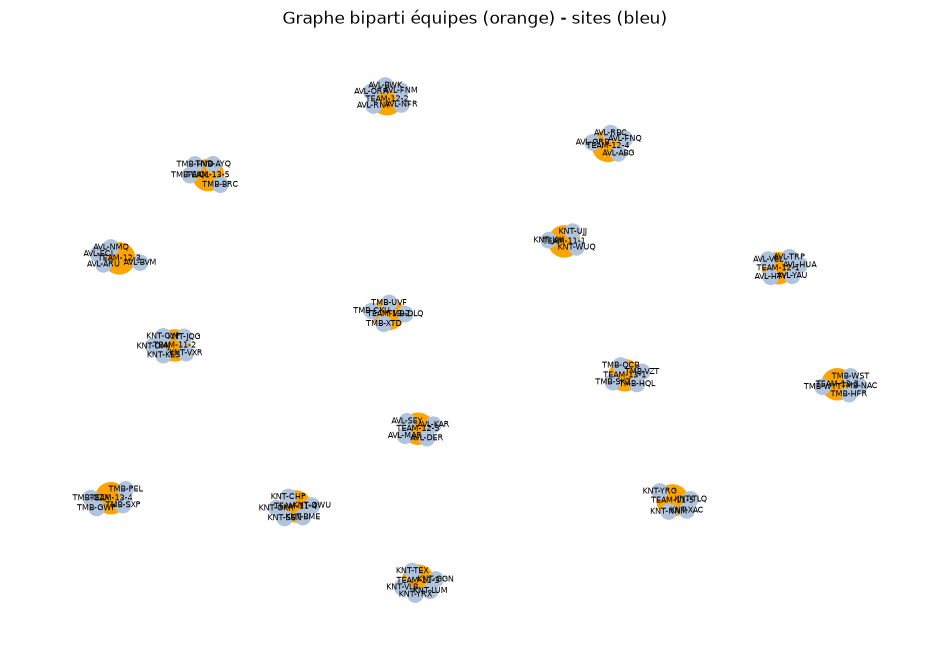

In [85]:
equipes_par_site = equipes.groupby("site_code")["observer_team"].apply(sorted)
noyau = ["KNT-KES", "KNT-LUM", "KNT-SEN", "AVL-MAR", "AVL-VEL", "AVL-ORR", "TMB-NAC", "TMB-PEL"]
print("Équipes intervenues sur les 8 sites historiques du programme :")
print(equipes_par_site.loc[noyau])

fig, ax = plt.subplots(figsize=(12, 8))
pos = nx.spring_layout(G_eq, seed=1, k=0.35)
couleurs = ["orange" if G_eq.nodes[n]["bipartite"] == "equipe" else "lightsteelblue" for n in G_eq.nodes]
nx.draw_networkx(G_eq, pos, node_color=couleurs, node_size=[500 if c == "orange" else 120 for c in couleurs],
                 font_size=6, width=0.4, ax=ax)
ax.set_title("Graphe biparti équipes (orange) - sites (bleu)")
ax.axis("off")
plt.show()

**Résultat.**

- **Chaque site est suivi par une seule équipe** (64 liens pour 64 sites), et chaque équipe suit 3 à 5 sites. La projection se découpe donc en **15 groupes séparés**, un par équipe, dans lesquels tous les sites sont reliés entre eux.
- Les algorithmes de détection de communautés retrouvent ces 15 groupes : Louvain (modularité de 0,93) et Girvan-Newman (0,91). La **modularité** mesure à quel point les liens restent à l'intérieur des groupes ; proche de 1, les groupes sont très nets. Le préfixe des équipes correspond à la région : 11 pour Kintara, 12 pour Avelora, 13 pour Tembara.
- Les 8 sites mis en avant ont chacun **une équipe différente**.

Les chutes ne peuvent donc pas venir d'une équipe qui compterait mal. Ce graphe permet d'**écarter une explication**.

## 9.2 Le registre des accès aux sites

Le rapport d'incident de KNT-KES (partie 8) demande de conserver le **dossier d'accès** au site. Ce registre existe : `public_records/site_access_case_events.csv`. Chaque dossier concerne un de nos 64 sites et suit les étapes d'une demande d'accès : dépôt, revues, autorisation, entrée, sortie, clôture. C'est exactement la forme d'un **journal d'événements**, la matière première du *process mining* (cours 4) : un dossier, une activité, une date.

Avant de l'analyser, nous le nettoyons comme en partie 3 : activités écrites en majuscules harmonisées, dates aux formats mélangés converties, espaces en trop retirés.

In [86]:
acces = dataframes["site_access_case_events"].copy()
acces["activity"] = normaliser_categorie(acces["activity"])
acces["access_purpose"] = normaliser_categorie(acces["access_purpose"])
acces["event_time"] = pd.to_datetime(acces["event_time"], format="mixed")
acces = acces.sort_values(["access_case_number", "event_time"]).reset_index(drop=True)
print(acces.shape, "-", acces["access_case_number"].nunique(), "dossiers sur", acces["site_code"].nunique(), "sites")
print("Tous les sites du registre sont des sites écologiques :",
      set(acces["site_code"]) <= set(dataframes["monitoring_sites"]["site_code"]))

journal = pm4py.format_dataframe(acces, case_id="access_case_number", activity_key="activity",
                                 timestamp_key="event_time")
variantes = pm4py.get_variants(journal)
variantes = pd.Series({" > ".join(v): (len(c) if isinstance(c, list) else c) for v, c in variantes.items()},
                      name="nb_dossiers").sort_values(ascending=False)
variantes.to_frame()

(413, 15) - 60 dossiers sur 50 sites
Tous les sites du registre sont des sites écologiques : True


,nb_dossiers
request_submitted > technical_review > wildlife_review > authorization_granted > access_started > access_completed > closure_recorded,28
request_submitted > technical_review > authorization_granted > access_started > access_completed > closure_recorded,11
request_submitted > technical_review > wildlife_review > security_review > authorization_granted > access_started > access_completed > closure_recorded,11
request_submitted > technical_review > wildlife_review > authorization_denied > closure_recorded,4
request_submitted > technical_review > authorization_denied > closure_recorded,2
request_submitted > technical_review > wildlife_review > authorization_denied > request_submitted > authorization_granted > access_started > access_completed > closure_recorded,2
request_submitted > technical_review > authorization_granted > access_started > access_completed > closure_recorded > closure_recorded,1
request_submitted > technical_review > wildlife_review > security_review > authorization_denied > request_submitted > authorization_granted > access_started > access_completed > closure_recorded,1


Nous découvrons le processus à partir du journal :

- le **graphe des enchaînements** (DFG) compte combien de fois chaque étape est suivie de chaque autre ;
- le **Heuristic Miner** ne garde que les enchaînements fiables. Nous recalculons à la main son degré de dépendance pour vérifier le résultat de la bibliothèque pm4py ;
- l'**Inductive Miner** produit un modèle de processus complet.

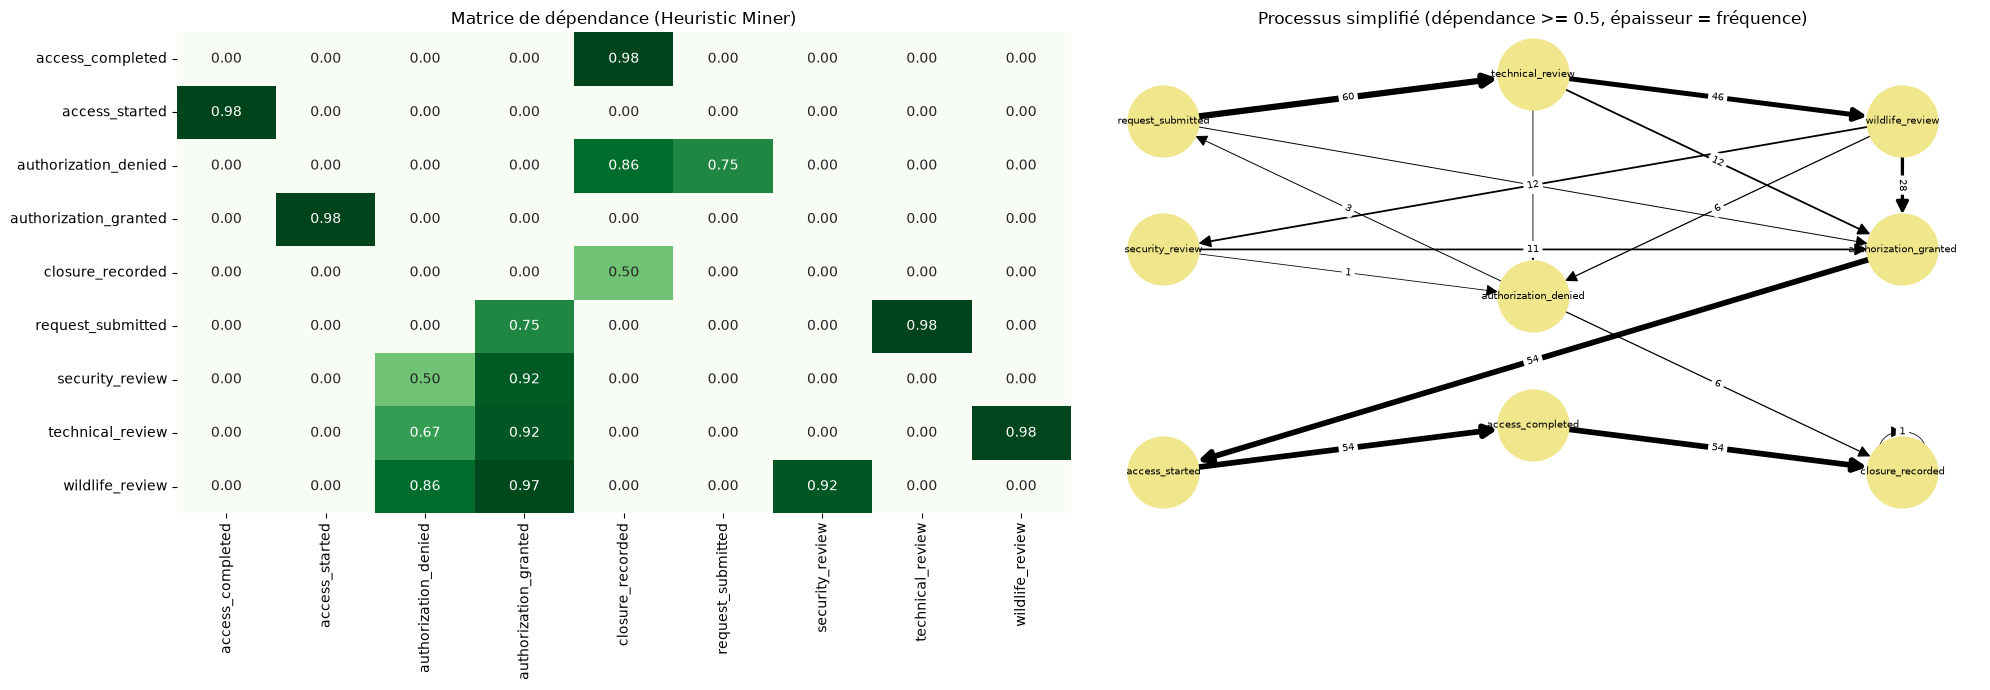

Liens retenus identiques à ceux de pm4py : False
Liens propres à pm4py : [] | propres à notre calcul : [('closure_recorded', 'closure_recorded')]

Arbre de processus (Inductive Miner) :
->( +( 'technical_review', *( 'request_submitted', tau ), X( tau, ->( X( tau, ->( 'wildlife_review', X( tau, 'security_review' ) ) ), X( tau, 'authorization_denied' ) ) ) ), X( tau, ->( 'authorization_granted', 'access_started', 'access_completed' ) ), *( 'closure_recorded', tau ) )


In [87]:
dfg, debuts, fins = pm4py.discover_dfg(journal)

# Heuristic Miner (slide 23) : degré de dépendance a => b = (|a>b| - |b>a|) / (|a>b| + |b>a| + 1)
activites = sorted({a for a, _ in dfg} | {b for _, b in dfg})
dependance = pd.DataFrame(0.0, index=activites, columns=activites)
for (a, b), n_ab in dfg.items():
    n_ba = dfg.get((b, a), 0)
    # boucle sur une même activité : |a>a| / (|a>a| + 1), comme dans la version originale de l'algorithme
    dependance.loc[a, b] = n_ab / (n_ab + 1) if a == b else (n_ab - n_ba) / (n_ab + n_ba + 1)

seuil_lambda = 0.5
G_proc = nx.DiGraph()
for (a, b), n in dfg.items():
    if dependance.loc[a, b] >= seuil_lambda:
        G_proc.add_edge(a, b, poids=n)

fig, axes = plt.subplots(1, 2, figsize=(20, 7))
sns.heatmap(dependance, annot=True, fmt=".2f", cmap="Greens", ax=axes[0], cbar=False)
axes[0].set_title("Matrice de dépendance (Heuristic Miner)")
ordre_proc = ["request_submitted", "technical_review", "wildlife_review", "security_review", "authorization_denied",
              "authorization_granted", "access_started", "access_completed", "closure_recorded"]
pos = {a: (i % 3 * 2.0, -(i // 3) * 1.5 + (0.4 if i % 2 else 0)) for i, a in enumerate(ordre_proc)}
nx.draw_networkx(G_proc, pos, ax=axes[1], node_color="khaki", node_size=2600, font_size=7, arrowsize=18,
                 width=[0.5 + 4 * G_proc[a][b]["poids"] / max(dfg.values()) for a, b in G_proc.edges])
nx.draw_networkx_edge_labels(G_proc, pos, edge_labels={(a, b): G_proc[a][b]["poids"] for a, b in G_proc.edges},
                             font_size=7, ax=axes[1])
axes[1].set_title(f"Processus simplifié (dépendance >= {seuil_lambda}, épaisseur = fréquence)")
axes[1].axis("off")
plt.tight_layout()
plt.show()

reseau_pm4py = pm4py.discover_heuristics_net(journal, dependency_threshold=seuil_lambda)
liens_pm4py = sorted((a, b) for a, d in reseau_pm4py.dependency_matrix.items() for b, v in d.items()
                     if v >= seuil_lambda)
print("Liens retenus identiques à ceux de pm4py :", liens_pm4py == sorted(G_proc.edges))
print("Liens propres à pm4py :", sorted(set(liens_pm4py) - set(G_proc.edges)),
      "| propres à notre calcul :", sorted(set(G_proc.edges) - set(liens_pm4py)))
print("\nArbre de processus (Inductive Miner) :")
print(pm4py.discover_process_tree_inductive(journal))

Nous résumons ensuite chaque dossier (organisation, site, objet, matériel, confidentialité, heure d'entrée…) pour comparer les organisations entre elles.

In [88]:
# Caractéristiques de chaque dossier
dossiers = acces.groupby("access_case_number").agg(
    site_code=("site_code", "first"), organisation=("requesting_organization_name", "first"),
    objet=("access_purpose", "first"), equipement=("equipment_category", "first"),
    confidentialite=("confidentiality_class", "first"), debut=("event_time", "min"), fin=("event_time", "max"),
    nb_evenements=("activity", "size"),
    refus=("activity", lambda a: (a == "authorization_denied").any()),
    accorde=("activity", lambda a: (a == "authorization_granted").any()),
)
debut_acces = acces[acces["activity"] == "access_started"].groupby("access_case_number")["event_time"].first()
fin_acces = acces[acces["activity"] == "access_completed"].groupby("access_case_number")["event_time"].first()
dossiers["debut_acces"] = debut_acces
dossiers["duree_dossier_j"] = (dossiers["fin"] - dossiers["debut"]).dt.days
dossiers["duree_acces_h"] = (fin_acces - debut_acces).dt.total_seconds() / 3600
dossiers["heure_entree"] = debut_acces.dt.hour
dossiers["horizon"] = dossiers["organisation"].eq("Horizon Field Research Cooperative")

print("Dossiers par organisation (top 5) :")
print(dossiers["organisation"].value_counts().head(5))
synthese = dossiers.groupby("horizon").agg(
    dossiers=("site_code", "size"), sites=("site_code", "nunique"),
    duree_dossier_j=("duree_dossier_j", "median"), duree_acces_h=("duree_acces_h", "median"),
    entree_18h=("heure_entree", lambda h: (h == 18).mean()),
    confidentiel_ou_restreint=("confidentialite", lambda c: c.isin(["confidential", "restricted"]).mean()),
    cold_storage=("equipement", lambda e: e.str.contains("cold-storage").mean()),
    refus_puis_accord=("refus", lambda r: (r & dossiers.loc[r.index, "accorde"]).mean()),
).rename(index={True: "Horizon Field Research Coop.", False: "autres organisations"})
display(synthese.round(2))
print("Sites visités par Horizon :", sorted(dossiers.loc[dossiers["horizon"], "site_code"].unique()))

Dossiers par organisation (top 5) :
organisation
Horizon Field Research Cooperative       18
Nordhaven Maritime Safety Agency          2
Valenne Laboratory Materials              2
Interregional Procurement Cooperative     2
Nordhaven Refrigeration Works             2
Name: count, dtype: int64


,dossiers,sites,duree_dossier_j,duree_acces_h,entree_18h,confidentiel_ou_restreint,cold_storage,refus_puis_accord
horizon,,,,,,,,
autres organisations,42,42,17.0,18.0,0.0,0.26,0.00,0.00
Horizon Field Research Coop.,18,8,34.0,9.0,1.0,0.78,0.39,0.17


Sites visités par Horizon : ['AVL-MAR', 'AVL-ORR', 'AVL-VEL', 'KNT-KES', 'KNT-LUM', 'KNT-SEN', 'TMB-NAC', 'TMB-PEL']


**Le processus d'accès.**

- Le parcours normal est : demande → revue technique → (revue faune) → (revue sécurité) → autorisation → entrée → sortie → clôture. Il couvre 50 des 60 dossiers.
- Les parcours rares contiennent un **refus suivi d'une nouvelle demande**, puis d'une autorisation. L'Inductive Miner représente ce retour en arrière par une **boucle**.
- Notre calcul manuel du Heuristic Miner donne le même graphe que pm4py, à une boucle près, qui vient d'un seul dossier clôturé deux fois.

**Horizon face aux autres organisations.** La Horizon Field Research Cooperative détient **18 des 60 dossiers** ; aucune autre organisation n'en a plus de 2.

| | Horizon | Autres organisations |
|---|---|---|
| Sites | 8 sites, visités à répétition | 42 sites, chacun une fois |
| Durée du dossier (médiane) | 34 jours | 17 jours |
| Entrée sur le site | **toujours à 18 h, de nuit**, 9 h sur place | jamais de nuit, 18 h sur place |
| Confidentiel ou restreint | **78 %** | 26 % |
| Matériel réfrigéré (*cold-storage*) | **39 %** | 0 % |
| Refus, puis accord | 17 % (3 dossiers) | 0 % |

Or la nuit est le moment où les chauves-souris sont actives, et le matériel réfrigéré sert à conserver des échantillons. **Les 8 sites d'Horizon comprennent KNT-KES, KNT-LUM et KNT-SEN**, les trois grottes qui décrochaient en partie 2, ainsi que AVL-MAR, AVL-ORR, AVL-VEL, TMB-NAC et TMB-PEL.

**Une contradiction entre deux sources.** Selon le rapport EFR-510088, l'accès de mars 2024 avait pour objet la « maintenance de routine ». Le registre (dossier ACC-2024-0014) indique un **« programme de suivi nocturne de la faune »**, avec du matériel acoustique et une caméra.

**Le réseau des acteurs.** Nous construisons un graphe qui relie les organisations, les personnes et les sites, d'après les rapports et le registre des accès. Les mesures de **centralité** indiquent quels acteurs occupent une position clé : le **degré** (nombre de liens), l'**intermédiarité** (*betweenness* : combien de chemins passent par l'acteur) et la **proximité** (*closeness* : à quel point l'acteur est proche de tous les autres).

In [89]:
# Graphe des acteurs : organisations, personnes et sites, d'après les rapports ET le registre des accès
G_act = nx.Graph()
for _, r in rapports.iterrows():
    G_act.add_edge(("org", r["author_organization"]), ("site", r["site_code"]), source="rapport")
    if pd.notna(r["author_name"]):
        G_act.add_edge(("pers", r["author_name"]), ("org", r["author_organization"]), source="rapport")
        G_act.add_edge(("pers", r["author_name"]), ("site", r["site_code"]), source="rapport")
for _, r in acces.iterrows():
    G_act.add_edge(("org", r["requesting_organization_name"]), ("site", r["site_code"]), source="acces")
    if pd.notna(r["authorized_person_name"]):
        G_act.add_edge(("pers", r["authorized_person_name"]), ("site", r["site_code"]), source="acces")

print(f"{G_act.number_of_nodes()} nœuds, {G_act.number_of_edges()} liens, "
      f"{nx.number_connected_components(G_act)} composante(s) connexe(s)")
centralites = pd.DataFrame({"degre": dict(G_act.degree()), "betweenness": nx.betweenness_centrality(G_act),
                            "closeness": nx.closeness_centrality(G_act)})
centralites["type"] = [n[0] for n in centralites.index]
centralites.index = [n[1] for n in centralites.index]
print("Organisations les plus centrales :")
display(centralites[centralites["type"] == "org"].sort_values("betweenness", ascending=False).head(6).round(3))

personnes_rapport = set(rapports["author_name"].dropna())
personnes_acces = set(acces["authorized_person_name"].dropna())
print("Auteurs de rapports qui apparaissent aussi comme personnes autorisées dans le registre des accès :",
      sorted(personnes_rapport & personnes_acces))

145 nœuds, 496 liens, 1 composante(s) connexe(s)


Organisations les plus centrales :


,degre,betweenness,closeness,type
Horizon Field Research Cooperative,18,0.044,0.413,org
Avelora Agricultural Resilience Agency,10,0.034,0.371,org
Belen Agro-Industries,8,0.018,0.326,org
Threshold Earth Observatory,9,0.018,0.386,org
Pollinator Justice Network,8,0.014,0.378,org
Asterion Clinical Institute,4,0.003,0.336,org


Auteurs de rapports qui apparaissent aussi comme personnes autorisées dans le registre des accès : ['Amina Elen', 'Anika Dren', 'Calen Jaren', 'Daria Zaven', 'Doran Norel', 'Doran Wessen', 'Farah Norel', 'Ilyan Rho', 'J. Varlan', 'Jalen Zorin', 'Jonah Bell', 'Jora Vela', 'Julien Marot', 'Mara Venn', 'Nadia Istra', 'Ravin Palen', 'Selene Aras', 'Uma Wessen', 'Vera Waren', 'Zalia Dalen']


**Le réseau des acteurs** (145 nœuds, 496 liens, tous reliés entre eux). La **Horizon Field Research Cooperative est l'organisation la plus centrale** (18 liens, intermédiarité de 0,044, proximité de 0,41), devant l'agence de résilience agricole d'Avelora.

20 auteurs de rapports sont aussi des **personnes autorisées** dans le registre des accès : ceux qui écrivent les rapports et ceux qui interviennent sur le terrain forment un même petit réseau. Une même organisation demande les accès, intervient de nuit sur les sites, et signe le seul rapport qui décrit un prélèvement possible.

# 10. Que deviennent les chauves-souris après chaque accès ?

C'est le test central de notre hypothèse. Si les accès d'Horizon s'accompagnent de prélèvements de chauves-souris, alors on doit observer :

1. une chute de l'activité **juste après chaque accès Horizon** ;
2. **pas** de chute après les accès des autres organisations ;
3. **pas** de chute pour les espèces de comparaison ;
4. une chute qui ne s'explique ni par un **appareil en panne**, ni par un **changement du milieu**.

**Méthode : une étude d'événements.** Pour chaque accès, nous suivons l'écart saisonnier du site (partie 7.2) de 3 mois avant à 6 mois après le mois d'entrée sur le site, noté k = 0. Nous faisons ensuite la moyenne, séparément pour Horizon et pour les autres organisations.

Accès couverts par les relevés : {'autres': 26, 'Horizon': 15}


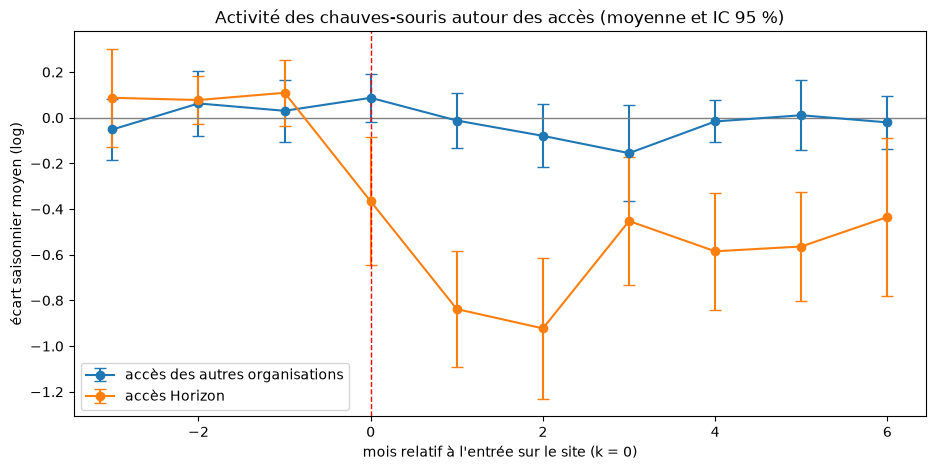

In [90]:
evenements = dossiers.dropna(subset=["debut_acces"]).copy()
evenements["mois_acces"] = evenements["debut_acces"].dt.to_period("M").dt.to_timestamp()
evenements = evenements[(evenements["mois_acces"] >= eco["reporting_month"].min())
                        & (evenements["mois_acces"] <= eco["reporting_month"].max())]
print("Accès couverts par les relevés :", evenements["horizon"].value_counts().rename({True: "Horizon", False: "autres"}).to_dict())

log_comp = np.log1p(eco["comparison_species_count"])
log_acou = np.log1p(eco["acoustic_detection_count"])
eco["ecart_especes_comparaison"] = log_comp - log_comp.groupby([eco["site_code"], eco["mois_calendaire"]]).transform("median")
eco["ecart_acoustique"] = log_acou - log_acou.groupby([eco["site_code"], eco["mois_calendaire"]]).transform("median")
for col in ["uptime_pct", "weather_interference", "habitat_disturbance_index"]:
    eco[f"ecart_{col}"] = eco[col] - eco.groupby("site_code")[col].transform("median")

indicateurs = ["ecart_saisonnier", "ecart_acoustique", "ecart_especes_comparaison", "ecart_uptime_pct",
               "ecart_weather_interference", "ecart_habitat_disturbance_index"]
eco_idx = eco.set_index(["site_code", "reporting_month"])
lignes = []
for dossier, ev in evenements.iterrows():
    for k in range(-3, 7):
        cle = (ev["site_code"], ev["mois_acces"] + pd.DateOffset(months=k))
        if cle in eco_idx.index:
            lignes.append({"dossier": dossier, "site_code": ev["site_code"], "horizon": ev["horizon"], "k": k,
                           "comptage": eco_idx.loc[cle, "observed_bat_count"], **eco_idx.loc[cle, indicateurs].to_dict()})
etude = pd.DataFrame(lignes)

resume = etude.groupby(["horizon", "k"])["ecart_saisonnier"].agg(["mean", "sem", "count"]).reset_index()
fig, ax = plt.subplots(figsize=(11, 5))
for horizon, groupe in resume.groupby("horizon"):
    nom = "accès Horizon" if horizon else "accès des autres organisations"
    ax.errorbar(groupe["k"], groupe["mean"], yerr=1.96 * groupe["sem"], marker="o", capsize=4, label=nom)
ax.axhline(0, color="grey", lw=1)
ax.axvline(0, color="red", ls="--", lw=1)
ax.set_xlabel("mois relatif à l'entrée sur le site (k = 0)")
ax.set_ylabel("écart saisonnier moyen (log)")
ax.set_title("Activité des chauves-souris autour des accès (moyenne et IC 95 %)")
ax.legend()
plt.show()

**Contrôles.** Nous refaisons le même calcul sur d'autres indicateurs : espèces de comparaison, détections acoustiques, uptime de l'appareil, interférence météo et perturbation de l'habitat.

In [91]:
# Contrôles : la baisse touche-t-elle aussi les espèces de comparaison, l'appareil, la météo, l'habitat ?
apres = etude[etude["k"].isin([1, 2])].groupby("horizon")[indicateurs].mean()
avant = etude[etude["k"].isin([-3, -2, -1])].groupby("horizon")[indicateurs].mean()
controles = pd.concat({"avant (k = -3 à -1)": avant, "après (k = 1 et 2)": apres}).T
controles.columns = [f"{p} | {'Horizon' if h else 'autres'}" for p, h in controles.columns]
controles.round(2)

,avant (k = -3 à -1) | autres,avant (k = -3 à -1) | Horizon,après (k = 1 et 2) | autres,après (k = 1 et 2) | Horizon
ecart_saisonnier,0.01,0.09,-0.05,-0.88
ecart_acoustique,-0.03,0.13,-0.07,-0.74
ecart_especes_comparaison,0.01,0.01,-0.07,-0.09
ecart_uptime_pct,-1.00,-0.55,-1.58,0.40
ecart_weather_interference,7.71,-4.84,-2.76,3.68
ecart_habitat_disturbance_index,1.03,-0.24,-0.76,-0.76


**Test placebo.** Une baisse aussi forte pourrait-elle arriver par hasard ? Nous tirons 2 000 fois des « faux accès », à des dates prises au hasard sur les mêmes sites, et refaisons le même calcul. Si les vrais accès donnent une baisse plus forte que tous les faux, le hasard est écarté.

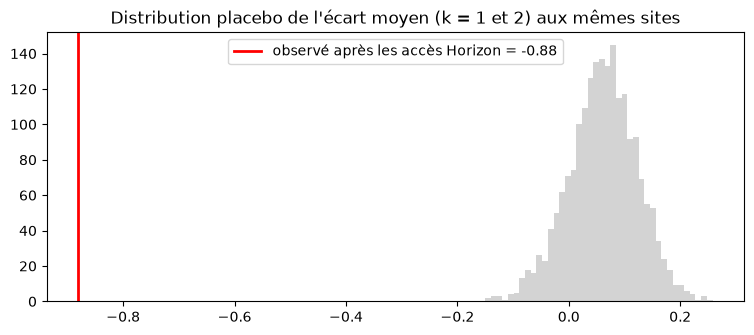

Écart observé = -0.88 (soit -59 % d'activité), placebo : moyenne 0.06, min -0.15 ; p = 0.0005


In [92]:
# Test par permutation (placebo) : des « faux accès » tirés au hasard aux mêmes sites donnent-ils une baisse aussi forte ?
horizon_ev = evenements[evenements["horizon"]]
obs = etude[etude["horizon"] & etude["k"].isin([1, 2])]["ecart_saisonnier"].mean()

ecart_par_cle = eco.set_index(["site_code", "reporting_month"])["ecart_saisonnier"].to_dict()
mois_dispo = [pd.Timestamp(m) for m in sorted(eco["reporting_month"].unique())][3:-3]
vrais = {(s, m + pd.DateOffset(months=k)) for s, m in zip(evenements["site_code"], evenements["mois_acces"])
         for k in range(-3, 7)}
rng = np.random.default_rng(0)
nulle = []
for _ in range(2000):
    valeurs = []
    for s in horizon_ev["site_code"]:
        while True:                       # mois placebo hors des fenêtres des vrais accès
            m = mois_dispo[rng.integers(len(mois_dispo))]
            if (s, m) not in vrais:
                break
        valeurs += [ecart_par_cle[(s, m + pd.DateOffset(months=k))] for k in (1, 2)
                    if (s, m + pd.DateOffset(months=k)) in ecart_par_cle]
    nulle.append(np.mean(valeurs))
nulle = np.array(nulle)
p_valeur = (1 + (nulle <= obs).sum()) / (len(nulle) + 1)

plt.figure(figsize=(9, 3.5))
plt.hist(nulle, bins=40, color="lightgrey")
plt.axvline(obs, color="red", lw=2, label=f"observé après les accès Horizon = {obs:.2f}")
plt.legend()
plt.title("Distribution placebo de l'écart moyen (k = 1 et 2) aux mêmes sites")
plt.show()
print(f"Écart observé = {obs:.2f} (soit {100 * (np.exp(obs) - 1):.0f} % d'activité), "
      f"placebo : moyenne {nulle.mean():.2f}, min {nulle.min():.2f} ; p = {p_valeur:.4f}")

Nous regardons ensuite chaque accès Horizon séparément, et nous vérifions s'il a fait l'objet d'un rapport de terrain dans les 3 mois.

In [93]:
# Les épisodes un par un, et ceux qui ont été documentés dans un rapport de terrain
episodes = etude[etude["horizon"]].pivot_table(index=["dossier", "site_code"], columns="k", values="comptage")
episodes = episodes[[c for c in [-1, 0, 1, 2] if c in episodes.columns]]
episodes.columns = [f"comptage k={c}" for c in episodes.columns]
episodes = episodes.join(evenements[["objet", "equipement", "confidentialite"]], on="dossier")
deficit = (etude[etude["horizon"] & etude["k"].isin([1, 2])].groupby("dossier")["ecart_saisonnier"].mean()
           .rename("deficit_k1_k2"))
episodes = episodes.join(deficit, on="dossier")

def documente(ligne):
    m = evenements.loc[ligne.name[0], "mois_acces"]
    r = rapports[(rapports["site_code"] == ligne.name[1]) & (rapports["document_date"] >= m)
                 & (rapports["document_date"] <= m + pd.DateOffset(months=3))]
    return ", ".join(r["document_id"] + " (" + r["document_type"] + ")") or "aucun rapport"

episodes["rapport dans les 3 mois"] = episodes.apply(documente, axis=1)
print("Épisodes avec un déficit (écart moyen k=1-2 < -0,3) :", (episodes["deficit_k1_k2"] < -0.3).sum(), "sur", len(episodes))
episodes.round(2)

Épisodes avec un déficit (écart moyen k=1-2 < -0,3) : 14 sur 15


,,comptage k=-1,comptage k=0,comptage k=1,comptage k=2,objet,equipement,confidentialite,deficit_k1_k2,rapport dans les 3 mois
dossier,site_code,,,,,,,,,
ACC-2019-0004,TMB-PEL,11.0,5.0,5.0,3.0,acoustic monitoring and equipment maintenance,portable monitoring and cold-storage equipment,confidential,-0.45,aucun rapport
ACC-2019-0005,KNT-LUM,15.0,4.0,3.0,1.0,night wildlife monitoring programme,protective field equipment,confidential,-1.55,aucun rapport
ACC-2019-0006,AVL-VEL,18.0,10.0,4.0,10.0,acoustic monitoring and equipment maintenance,portable monitoring and cold-storage equipment,restricted,-0.88,aucun rapport
ACC-2020-0007,KNT-SEN,15.0,4.0,9.0,6.0,habitat survey and sample documentation,protective field equipment,restricted,-0.51,aucun rapport
ACC-2020-0008,AVL-ORR,23.0,15.0,9.0,8.0,acoustic monitoring and equipment maintenance,acoustic and camera equipment,confidential,-0.51,aucun rapport
ACC-2021-0009,KNT-KES,25.0,38.0,9.0,11.0,acoustic monitoring and equipment maintenance,protective field equipment,standard,-0.76,aucun rapport
ACC-2021-0010,AVL-MAR,36.0,30.0,3.0,5.0,acoustic monitoring and equipment maintenance,portable monitoring and cold-storage equipment,restricted,-1.21,aucun rapport
ACC-2022-0011,TMB-NAC,16.0,8.0,3.0,2.0,habitat survey and sample documentation,acoustic and camera equipment,confidential,-1.72,aucun rapport
ACC-2023-0012,KNT-LUM,6.0,3.0,3.0,3.0,habitat survey and sample documentation,portable monitoring and cold-storage equipment,standard,-1.21,aucun rapport


**Lecture inverse.** Partons cette fois des 72 déficits trouvés sans a priori en partie 7.2 : combien tombent dans les 3 mois qui suivent un accès ?

In [94]:
# Lecture inverse : parmi les déficits détectés sans a priori par la STL (partie 7.2), combien suivent un accès ?
fenetres = {"Horizon": set(), "autres": set()}
for _, ev in evenements.iterrows():
    for k in range(0, 3):
        fenetres["Horizon" if ev["horizon"] else "autres"].add((ev["site_code"], ev["mois_acces"] + pd.DateOffset(months=k)))
cles_deficits = list(zip(deficits_retenus["site_code"], deficits_retenus["reporting_month"]))
print(f"Déficits STL retenus : {len(cles_deficits)}")
for nom, f in fenetres.items():
    n = sum(c in f for c in cles_deficits)
    print(f"  dans les 0-2 mois suivant un accès {nom} : {n} ({100 * n / len(cles_deficits):.0f} %) "
          f"alors que ces fenêtres ne couvrent que {100 * len(f) / len(eco):.1f} % des relevés")
print("\nSites des 8 accès Horizon : déficits STL retenus hors fenêtre d'accès")
hors = deficits_retenus[deficits_retenus["site_code"].isin(noyau)
                        & ~pd.Series(cles_deficits, index=deficits_retenus.index).isin(fenetres["Horizon"])]
hors[["site_code", "reporting_month", "observed_bat_count", "z_stl"]].round(2)

Déficits STL retenus : 72
  dans les 0-2 mois suivant un accès Horizon : 6 (8 %) alors que ces fenêtres ne couvrent que 0.9 % des relevés
  dans les 0-2 mois suivant un accès autres : 1 (1 %) alors que ces fenêtres ne couvrent que 1.6 % des relevés

Sites des 8 accès Horizon : déficits STL retenus hors fenêtre d'accès


,site_code,reporting_month,observed_bat_count,z_stl
1575,AVL-VEL,2020-04-01,6.0,-3.15
1621,AVL-VEL,2024-02-01,4.0,-3.27
2369,KNT-KES,2021-06-01,5.0,-3.38
2695,KNT-SEN,2022-08-01,1.0,-5.06
4225,TMB-PEL,2020-02-01,1.0,-3.83


**Le résultat central.**

- **Après les accès Horizon, l'activité chute.** L'écart saisonnier passe d'environ +0,1 avant l'accès à **−0,84 puis −0,92** un et deux mois après, soit environ **59 % de chauves-souris en moins** que d'habitude à cette période. La baisse est nette dès le mois de l'accès. Six mois plus tard, l'écart est encore de −0,4 à −0,6 : la population ne se reconstitue pas.
- **Après les accès des 26 autres organisations, rien ne se passe** : l'écart reste entre −0,15 et +0,09.
- **Les contrôles** :
  - les **espèces de comparaison** ne bougent pas (−0,09) ;
  - l'**appareil** fonctionne normalement (uptime de +0,4 point), sans panne, avec une qualité toujours bonne ;
  - la **perturbation de l'habitat** ne change pas ;
  - l'**interférence météo** augmente un peu (+3,7 points), mais elle n'a aucun lien avec l'activité (partie 4) ;
  - les **détections acoustiques**, mesurées indépendamment du comptage visuel, baissent aussi (−0,74).

  La baisse touche donc **seulement les chauves-souris** : ce n'est ni une erreur de mesure ni un changement du milieu.
- **Test placebo.** Sur 2 000 tirages de faux accès, l'écart moyen vaut +0,06 et ne descend jamais sous −0,15. L'écart observé (−0,88) est **en dehors de toute la distribution** : p ≈ 0,0005, la plus petite valeur possible avec 2 000 tirages.
- **Accès par accès.** **Les 14 accès Horizon observables sont tous suivis d'une baisse**, de −0,45 à −1,72. Le 15e (juin 2025, dernier mois des données) est trop récent pour être évalué. **Un seul a donné lieu à un rapport** : KNT-KES en 2024. Les 13 autres sont passés inaperçus.
- **Lecture inverse.** 8 % des 72 déficits tombent dans les 3 mois qui suivent un accès Horizon, alors que ces périodes ne représentent que 0,9 % des relevés : c'est **9 fois plus que le hasard**. Pour les autres organisations, il n'y a pas d'excès (1 % des déficits pour 1,6 % des relevés).

*Une corrélation n'est pas une causalité.* Nous montrons une coïncidence **systématique, spécifique et robuste**, pas *qui* prélève ni *pourquoi*. Mais toutes les autres explications testées sont écartées : saison, météo, appareil, équipe, habitat, géographie.

**Et les vergers ?** Certaines chauves-souris pollinisent les fleurs de durian. Si elles disparaissent, la formation des fruits (la **nouaison**) pourrait en souffrir. Nous regardons d'abord quelles variables sont liées à la nouaison, puis son évolution après les accès.

Corrélation de Spearman (relevés de vergers) :
fruit_set_rate_pct           0.49
durian_yield_kg              0.07
durian_flower_density        0.27
other_pollinator_activity    0.31
Name: taux_horaire, dtype: float64


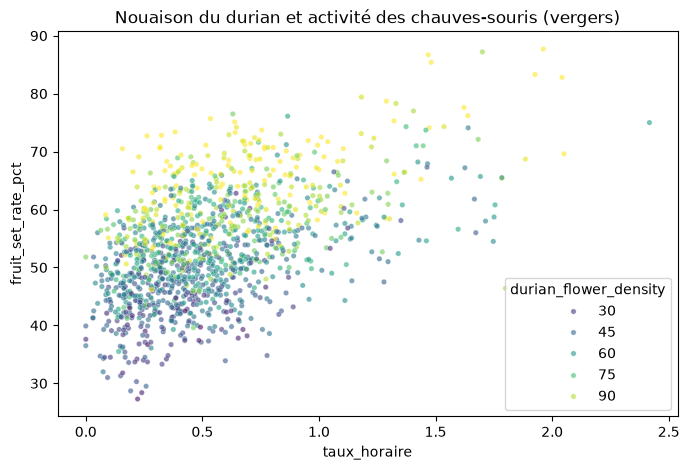

mean       count      
horizon False True  False True 
k                              
-2       2.55  3.03     7     6
-1       1.84  2.83     7     6
 0      -0.54 -1.43     7     6
 1       1.41 -3.09     7     5
 2      -4.83 -5.07     7     5
 3      -1.08  1.96     7     5

In [95]:
# Et les vergers ? Les chauves-souris nectarivores pollinisent le durian
print("Corrélation de Spearman (relevés de vergers) :")
print(verger[["fruit_set_rate_pct", "durian_yield_kg", "durian_flower_density", "other_pollinator_activity",
              "taux_horaire"]].corr(method="spearman")["taux_horaire"].drop("taux_horaire").round(2))

fig, ax = plt.subplots(figsize=(8, 5))
sns.scatterplot(data=verger, x="taux_horaire", y="fruit_set_rate_pct", hue="durian_flower_density",
                palette="viridis", s=15, alpha=0.6, ax=ax)
ax.set_title("Nouaison du durian et activité des chauves-souris (vergers)")
plt.show()

verger["mois_calendaire"] = verger["reporting_month"].dt.month
verger["ecart_nouaison"] = verger["fruit_set_rate_pct"] - verger.groupby(["site_code", "mois_calendaire"])["fruit_set_rate_pct"].transform("median")
v_idx = verger.set_index(["site_code", "reporting_month"]).sort_index()
lignes = []
for dossier, ev in evenements[evenements["site_code"].isin(verger["site_code"].unique())].iterrows():
    for k in range(-2, 4):
        cle = (ev["site_code"], ev["mois_acces"] + pd.DateOffset(months=k))
        if cle in v_idx.index:
            lignes.append({"horizon": ev["horizon"], "k": k, "ecart_nouaison": v_idx.loc[cle, "ecart_nouaison"]})
pd.DataFrame(lignes).pivot_table(index="k", columns="horizon", values="ecart_nouaison", aggfunc=["mean", "count"]).round(2)

**Les vergers.** Dans les vergers de durian, l'activité des chauves-souris est la variable la plus liée au **taux de nouaison** (Spearman de **0,49**), devant les autres pollinisateurs (0,31) et la densité de fleurs (0,27). C'est cohérent avec le rôle de pollinisateur d'*Eonycteris spelaea*, l'espèce citée dans le rapport. Le rendement, lui, n'est pas lié à l'activité (0,07).

Dans les trois vergers visités par Horizon (AVL-MAR, AVL-ORR, AVL-VEL), la nouaison baisse un peu le mois qui suit l'accès (−3,1 points, contre +1,4 pour les autres accès en verger). Mais il y a **trop peu de cas** (5 à 7 épisodes) pour conclure. Nous retenons un **lien plausible mais non démontré** entre ces prélèvements et la pollinisation.

# 11. Synthèse : ce que cachent les données écologiques

## Le récit en cinq étapes

1. **En apparence**, un programme de suivi ordinaire : 64 sites, 78 mois, une saison marquée, et une activité plus faible là où l'habitat est perturbé ou traité (Spearman de −0,40 et −0,25). Quelques pannes d'appareil. Des rapports de terrain écrits à partir de modèles, qui ne signalent presque jamais rien.
2. **Un seul rapport détonne** (EFR-510088, KNT-KES, avril 2024) : traces de manipulation, liens de contention coupés, chute d'*Eonycteris spelaea* juste après une « fenêtre d'accès ».
3. **Le registre des accès**, que ce rapport demande de conserver, montre qu'une organisation, la **Horizon Field Research Cooperative**, a obtenu 18 accès de 2018 à 2025 sur **8 sites, toujours les mêmes**. Ces accès ont lieu de nuit et sont souvent confidentiels ou restreints (78 %). 39 % d'entre eux utilisent du matériel réfrigéré, et trois ont été obtenus après un refus.
4. **Chacun de ces accès est suivi d'une chute de l'activité des chauves-souris** : −59 % en moyenne (p ≈ 0,0005). Les autres espèces ne sont pas touchées, et ni l'appareil, ni la météo, ni l'habitat n'expliquent la baisse. Rien de tel après les accès des autres organisations.
5. **Un seul de ces 14 épisodes a été signalé.** Les 13 autres sont passés inaperçus, cachés par les rapports types et par les variations de saison.

**L'hypothèse la plus cohérente avec les données** : des prélèvements répétés et discrets de chauves-souris, réalisés sous couvert d'accès autorisés pour du « suivi » ou de la « maintenance », avec un effet possible, mais non démontré, sur la pollinisation des vergers de durian.

## Ce que chaque cours a apporté

| Cours | Méthodes | Ce qu'elles ont apporté |
|---|---|---|
| 1 | nettoyage, statistiques descriptives, Pearson et Spearman | des données fiables ; le rôle de la perturbation et des pesticides |
| 2 | mises à l'échelle, distances, ACP, t-SNE, CAH, k-means, DBSCAN | pas de groupes naturels ; un axe de qualité écologique ; le choix des sites témoins |
| 3 | co-occurrences, Apriori, IQR, z-scores, Isolation Forest, LOF, DBSCAN, ABOD | les chutes ne sont pas des situations répétées ; une valeur aberrante n'est pas forcément une anomalie |
| 4 | graphe biparti, graphe des acteurs, Louvain, Girvan-Newman, Heuristic et Inductive Miner | équipe d'observation écartée ; Horizon au centre du réseau ; des accès atypiques |
| 5 | décomposition, ACF, STL, fenêtre glissante, Haversine, Moran, LISA, Voronoï, régionalisation | saison retirée ; des déficits locaux et non régionaux |
| 6 | prétraitement, sac de mots, n-grams, phrases types, TF-IDF, LSA, LDA | EFR-510088, seul rapport original |

## Limites

- **Une corrélation n'est pas une causalité.** Nous montrons une coïncidence systématique, pas l'auteur ni le but des prélèvements.
- **Peu de cas** : 14 épisodes Horizon, et 5 à 7 pour les vergers. Le test placebo compense en partie ce manque pour le résultat principal, mais pas pour la nouaison.
- **Des choix de nettoyage et de seuils** (médiane pour compléter, tertiles, z = −3, λ = 0,5) peuvent introduire des biais. Nous les avons justifiés et, quand c'était possible, comparés : MAD contre écart-type, standardisation contre min-max, quatre détecteurs d'anomalies, trois perplexités pour le t-SNE.
- **Texte** : pas de lemmatisation (choix expliqué en partie 8).
- **Données synthétiques** : l'histoire est fictive (README).

## Pistes hors du dossier ecology

- Le registre des procédures (`regulatory_case_events`) contient deux plaintes environnementales visant KNT-KES, en mars 2019 et avril 2023. Elles sont rattachées aux expéditions `SHP-2018-00007` et `SHP-2024-00007`. La seconde implique **Meridian BioLogistics**, une société de logistique biologique et de chaîne du froid.
- L'**Asterion Clinical Institute**, qui signe 2 rapports écologiques, porte le même nom que l'« Asterion Central Clinical Campus » du dossier `health`, où l'on trouve des procédures d'« administration de résilience métabolique ».

Ces pistes sont suivies dans `02_analyse_logistics.ipynb`, `03_rapport_health.ipynb` et `00_synthese.ipynb`.

# Annexe : usage de l'IA générative

Le README et le cours 0 demandent d'être honnête et transparent sur l'usage de l'IA générative. Nous avons utilisé un assistant d'IA générative, Claude (Anthropic).

- **Pourquoi et pour quoi faire** : nous avons utilisé l'assistant pour obtenir des **lignes directrices** et pour **proposer les étapes d'analyse**, en s'appuyant sur les supports des cours 0 à 6 : quelles méthodes appliquer à nos données, dans quel ordre, et avec quels contrôles. Nous l'avons sollicité après notre travail initial de la partie 1.
